# Sniper Window buys and backtest outcomes

This notebook inspects the **actual forked engine's saved results**, not a new
strategy simulation. The cohort is **October 10, 2026, 16:00–17:00 UTC
(19:00–20:00 Kyiv)**, with retained observations through 17:16:22 UTC.

It includes every filled simulated buy, historical curve charts with entry and
exit markers, fees and PnL, both settlement modes, and detailed diagnostics for
the **seven positions left open by the strict historical-liquidity check**.
All wallet and token links go to GMGN.

**Sell failure interpretation:** those seven had **zero submitted sell attempts**.
The strategy rejected their full-position quotes before creating an order. A
full sell submitted against that same recorded state would fail the modeled
real-SOL reserve check, but our replay omits our buy's added SOL and token reserve
changes from later states. This does **not** prove that the real strategy could
never sell. A smaller sale may fit the recorded reserves, another state may have
more liquidity, and a consistent counterfactual replay would have different reserves.

Creator-fee income is included in each reference buyer's observed break-even.
Developer accrual and its effect on cashflow are shown separately below.

The completed virtual-settlement result uses explicit assumed liquidity where
necessary. It is a **modeled result, not actual on-chain PnL**.

In [1]:
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
from bisect import bisect_left
import csv, gzip, hashlib, html, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, HTML, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / 'src/backtest').is_dir() and (p / 'var/dnipro').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from backtest.plugins.protocols.pumpfun.model import (
    PumpCurveStateV1, PumpCurveLifecycle, PumpMode, PumpQuoteError,
    PumpQuoteErrorCode, PumpSellLiquidityPolicy, sell_quote,
)
from backtest.plugins.execution.pump_sniper import profile
from backtest.plugins.strategies.creator_income import CreatorFeeIncome, allocate_creator_fee

RUN_DIRS = {
    'strict': ROOT / 'var/dnipro/sniper-window-20261010-slot-traces-strict-v1',
    'virtual': ROOT / 'var/dnipro/sniper-window-20261010-slot-traces-virtual-v1',
}
SOURCE = ROOT.parent / 'solana-live-indexer/research/sniper_break_even/data/2026-10-10-1600-1700'
EXPORT = ROOT / 'var/dnipro/sniper-window-20261010-slot-traces-notebook-v1'
EXPORT.mkdir(parents=True, exist_ok=True)
SOL = 'So11111111111111111111111111111111111111112'
LAMPORTS = 1_000_000_000
pd.set_option('display.max_rows', 60)
pd.set_option('display.max_colwidth', 70)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = [name for name in ['DejaVu Sans', 'Hiragino Sans GB', 'Hiragino Sans', 'Noto Sans CJK JP'] if name in available_fonts]

def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def utc(seconds):
    return datetime.fromtimestamp(int(seconds), timezone.utc).isoformat()

def parse_time(value):
    if isinstance(value, (int, float)):
        return int(value)
    return int(datetime.fromisoformat(value.replace('Z', '+00:00')).replace(tzinfo=timezone.utc).timestamp())

def read_gz(path):
    with gzip.open(path, 'rt') as stream:
        return [json.loads(line) for line in stream]

def linked_table(frame, link_column='gmgn_url', label_column='token', floats=6):
    data = frame.copy()
    if link_column in data and label_column in data:
        data[label_column] = [f'<a href="{html.escape(str(url), quote=True)}" target="_blank" rel="noopener">{html.escape(str(label))}</a>' for label, url in zip(data[label_column], data[link_column])]
        data = data.drop(columns=link_column)
    display(HTML(data.to_html(index=False, escape=False, float_format=lambda x: f'{x:,.{floats}f}', na_rep='—')))

## Verify the saved evidence

Every native output and frozen export is checked against its completion
manifest. This notebook makes no ClickHouse or RPC requests. The ledger is
checked in integer lamports and raw token units; SOL values and plots are views.

In [2]:
runs = {}
for name, folder in RUN_DIRS.items():
    manifest = json.loads((folder / 'manifest.json').read_text())
    assert manifest['complete'], name
    for filename, digest in manifest['files'].items():
        assert sha(folder / filename) == digest, (name, filename)
    runs[name] = json.loads((folder / 'result.json').read_text())
    for transaction in runs[name]['ledger']:
        totals = defaultdict(int)
        for posting in transaction['postings']:
            totals[posting['asset_id']] += posting['amount_atomic']
        assert all(v == 0 for v in totals.values()), transaction['transaction_id']
    summary = runs[name]['summary']
    cash = next(b[3] for b in summary['engine_summary']['final_balances'] if b[0] == 'portfolio:available:' + SOL and b[2] == SOL)
    assert cash - summary['policy']['bankroll_lamports'] == summary['realized_net_pnl_lamports'] - summary['open_cash_cost_lamports']

source_manifest = json.loads((SOURCE / 'manifest.json').read_text())
assert source_manifest['complete']
assert sha(SOURCE / 'manifest.json') == runs['virtual']['summary']['source_manifest_sha256']
assert runs['strict']['summary']['source_input_sha256'] == runs['virtual']['summary']['source_input_sha256']
assert runs['strict']['summary']['policy'] == runs['virtual']['summary']['policy']
parts = [source_manifest['births'], *source_manifest['parts'], *source_manifest['metadata']]
for part in parts:
    path = SOURCE / 'snapshot' / part['file']
    assert sha(path) == part['file_sha256'], part['name']
    assert len(read_gz(path)) == part['rows'], part['name']

birth_list = read_gz(SOURCE / 'snapshot' / source_manifest['births']['file'])
births = {b['mint']: b for b in birth_list}
clock = {}
all_trades = []
for part in source_manifest['parts']:
    rows = read_gz(SOURCE / 'snapshot' / part['file'])
    if part['name'].endswith('-clock'):
        clock.update({int(r['slot']): parse_time(r['observed_block_time']) for r in rows})
    elif part['name'].endswith('-trades'):
        for row in rows:
            row['payload'] = json.loads(row['decoded_extension_json'] or '{}')
            row['time'] = parse_time(row['block_time'] if row['block_time'] is not None else row['payload']['timestamp'])
            row['boundary'] = (int(row['slot']) << 32) + int(row['tx_idx']) + 1
            clock.setdefault(int(row['slot']), row['time'])
        all_trades.extend(rows)
assert len(all_trades) == runs['virtual']['summary']['retained_input_trade_events']
rows_by_run = {name: {r['mint']: r for r in run['positions']} for name, run in runs.items()}
blocked_mints = [r['mint'] for r in runs['strict']['positions'] if r['status'] == 'OPEN' and r['reason'] == 'INSUFFICIENT_REAL_SOL_RESERVES']
filled_mints = [r['mint'] for r in runs['virtual']['positions'] if r['status'] == 'CLOSED']
trades_by_mint = defaultdict(list)
for row in all_trades:
    if row['mint'] in filled_mints:
        trades_by_mint[row['mint']].append(row)
for mint in trades_by_mint:
    trades_by_mint[mint].sort(key=lambda r: (r['slot'], r['tx_idx'], tuple(r['instruction_path']), r['event_uid']))
for mint in blocked_mints:
    assert rows_by_run['strict'][mint]['exit_attempts'] == 0
    assert rows_by_run['strict'][mint]['entry_time'] + runs['strict']['summary']['policy']['holding_seconds'] < max(clock.values())

print(f'Verified {len(births):,} launches, {len(all_trades):,} retained trades and both native ledgers.')
print('Final retained clock:', utc(max(clock.values())))
print('Seven open positions have data beyond their five-minute deadlines; none submitted a sell.')

Verified 2,342 launches, 187,107 retained trades and both native ledgers.
Final retained clock: 2026-10-10T17:16:22+00:00
Seven open positions have data beyond their five-minute deadlines; none submitted a sell.


## Results and execution assumptions

Strict replay caps a sell by the recorded real-SOL reserve. Virtual settlement
uses the same full-position integer curve quote and records any funding shortfall
separately. Both keep later historical reserves unchanged by our orders.

The policy starts with 10 SOL, targets 5% net return, waits one slot for buys and
sells, exits after five minutes if the target is not reached, and uses 5% minimum
output tolerance. Network/priority cost is 0.000105 SOL per submission, tips are
zero, and account rent is 0.002039280 SOL, refunded on a completed full sale.

In [3]:
summary_rows = []
for name, run in runs.items():
    s = run['summary']
    summary_rows.append({
        'run': name, 'settlement_mode': s['execution_mode'], 'signals': s['signals'],
        'filled_buys': s['filled_entries'], 'closed': s['closed_positions'], 'open': s['open_positions'],
        'net_realized_or_modeled_pnl_SOL': s['realized_net_pnl_lamports'] / LAMPORTS,
        'open_cash_cost_SOL': s['open_cash_cost_lamports'] / LAMPORTS,
        'available_cash_SOL': float(s['final_available_sol']),
        'assumed_gross_liquidity_SOL': s.get('synthetic_shortfall_lamports', 0) / LAMPORTS,
    })
summary_table = pd.DataFrame(summary_rows)
display(summary_table)
print('The strict PnL is partial. The virtual PnL is complete under its explicit funding assumption.')

,run,settlement_mode,signals,filled_buys,closed,open,net_realized_or_modeled_pnl_SOL,open_cash_cost_SOL,available_cash_SOL,assumed_gross_liquidity_SOL
0,strict,EXOGENOUS_REPLAY,38,22,15,7,0.433958,9.701283,0.732675,0.000000
1,virtual,EXOGENOUS_VIRTUAL_SETTLEMENT,38,27,27,0,-3.759502,0.000000,6.240498,7.942451


The strict PnL is partial. The virtual PnL is complete under its explicit funding assumption.


## Every filled simulated buy

These are our hypothetical orders, not a wallet's observed on-chain transactions.
Token quantities stay in raw integer units because launch decimals are not
independently established. Cash cost includes protocol/creator fees, network
cost and posted rent. The selected early buyer's observed wallet is supplied
for comparison; its role does not prove private intent or ownership.

In [4]:
settlements = {name: {tx['correlation_id']: tx for tx in run['ledger'] if tx['reason'] == 'ORDER_SETTLEMENT'} for name, run in runs.items()}
fill_by_run_mint = {}
buy_records = []
for name, run in runs.items():
    by_mint = defaultdict(dict)
    for fill in run['fills']:
        side = 'BUY' if fill['sold_asset_id'] == SOL else 'SELL'
        by_mint[fill['pool_id']][side] = fill
    fill_by_run_mint[name] = by_mint
    for mint, sides in by_mint.items():
        fill = sides['BUY']
        position = rows_by_run[name][mint]
        tx = settlements[name][fill['order_id']]
        amounts = defaultdict(int)
        for p in tx['postings']:
            if p['asset_id'] == SOL and p['amount_atomic'] > 0:
                amounts[p['account_kind']] += p['amount_atomic']
        cost = sum(amounts[k] for k in ['VENUE', 'PROTOCOL_FEE', 'CREATOR_FEE', 'NETWORK_FEE', 'PORTFOLIO_LOCKED'])
        assert cost == position['entry_cash_lamports']
        buy_records.append({
            'run': name, 'token': position['symbol'], 'mint': mint, 'gmgn_url': position['gmgn_url'],
            'buy_UTC': utc(position['entry_time']), 'buy_slot': position['entry_slot'],
            'tokens_raw': fill['amount_out_atomic'], 'cash_cost_SOL': cost / LAMPORTS,
            'curve_deposit_SOL': amounts['VENUE'] / LAMPORTS,
            'protocol_fee_SOL': amounts['PROTOCOL_FEE'] / LAMPORTS,
            'creator_fee_SOL': amounts['CREATOR_FEE'] / LAMPORTS,
            'network_fee_SOL': amounts['NETWORK_FEE'] / LAMPORTS,
            'posted_rent_SOL': amounts['PORTFOLIO_LOCKED'] / LAMPORTS,
            'early_buyer_gmgn': position['sniper_gmgn_url'],
            'early_buyer_observed_cost_SOL': position['sniper_cost_lamports'] / LAMPORTS,
            'strict_open_due_to_liquidity': mint in blocked_mints,
            'order_id': fill['order_id'],
        })
all_buys = pd.DataFrame(buy_records).sort_values(['run', 'buy_slot'])
virtual_buys = all_buys[all_buys['run'] == 'virtual'].reset_index(drop=True)
linked_table(virtual_buys[['token', 'gmgn_url', 'buy_UTC', 'buy_slot', 'cash_cost_SOL', 'tokens_raw', 'early_buyer_observed_cost_SOL', 'strict_open_due_to_liquidity']])
print('All 49 filled buy records across both runs are exported; this view shows the 27 virtual-run buys.')

token,buy_UTC,buy_slot,cash_cost_SOL,tokens_raw,early_buyer_observed_cost_SOL,strict_open_due_to_liquidity
NEZARA,2026-10-10T16:01:32+00:00,455314020,1.515876,42088632742058,2.201685,False
henry,2026-10-10T16:03:23+00:00,455314524,1.056564,11763264605813,2.102424,False
VYRNO,2026-10-10T16:09:27+00:00,455316173,1.341706,26842278108988,2.008905,False
Snoopy,2026-10-10T16:10:02+00:00,455316334,2.465211,41872403351426,3.015005,False
DDAVE,2026-10-10T16:11:46+00:00,455316797,0.937811,24785490300603,1.000505,False
BRIMHUB,2026-10-10T16:13:33+00:00,455317287,0.728648,20596225447131,1.500455,False
DOG,2026-10-10T16:13:39+00:00,455317312,1.823553,35805029856472,3.022968,False
PKMON,2026-10-10T16:15:23+00:00,455317792,0.675999,16988732367466,1.003627,False
CATS,2026-10-10T16:18:18+00:00,455318586,2.381423,54309034763193,1.441299,False
UNBOX,2026-10-10T16:21:18+00:00,455319402,1.278135,17776824091415,1.500480,True


All 49 filled buy records across both runs are exported; this view shows the 27 virtual-run buys.


## Per-token PnL and outcomes in both runs

A blank strict PnL means the position remains open or was not entered; it is not
zero profit. The virtual run can enter five additional tokens after earlier
exits release capital. Two original completed positions also change exit time,
so its final result is not the old PnL plus only seven added sales.

In [5]:
outcome_records = []
for mint in filled_mints:
    v, s = rows_by_run['virtual'][mint], rows_by_run['strict'][mint]
    outcome_records.append({
        'token': v['symbol'], 'mint': mint, 'gmgn_url': v['gmgn_url'],
        'buy_UTC': utc(v['entry_time']), 'buy_cost_SOL': v['entry_cash_lamports'] / LAMPORTS,
        'virtual_exit_UTC': utc(v['exit_time']), 'virtual_exit_reason': v['reason'],
        'virtual_net_pnl_SOL': v['closed_pnl_lamports'] / LAMPORTS,
        'strict_status': s['status'], 'strict_reason': s['reason'],
        'strict_net_pnl_SOL': s['closed_pnl_lamports'] / LAMPORTS if s.get('closed_pnl_lamports') is not None else np.nan,
        'assumed_liquidity_SOL': v.get('exit_synthetic_shortfall_lamports', 0) / LAMPORTS,
        'formerly_open': mint in blocked_mints,
    })
outcomes = pd.DataFrame(outcome_records).sort_values('virtual_net_pnl_SOL', ascending=False).reset_index(drop=True)
linked_table(outcomes[['token', 'gmgn_url', 'buy_cost_SOL', 'virtual_net_pnl_SOL', 'virtual_exit_reason', 'strict_status', 'strict_net_pnl_SOL', 'assumed_liquidity_SOL']])
assert sum(r['closed_pnl_lamports'] for r in runs['virtual']['positions'] if r['status'] == 'CLOSED') - runs['virtual']['summary']['failed_entry_cost_lamports'] == runs['virtual']['summary']['realized_net_pnl_lamports']

token,buy_cost_SOL,virtual_net_pnl_SOL,virtual_exit_reason,strict_status,strict_net_pnl_SOL,assumed_liquidity_SOL
up,1.448896,0.503905,TARGET,ENTRY_REJECTED,—,0.000000
STOR,3.484782,0.377087,TARGET,CLOSED,0.377087,0.000000
DDAVE,0.937811,0.251393,TARGET,CLOSED,0.251393,0.000000
CATS,2.381423,0.245288,TARGET,CLOSED,0.245288,0.000000
Snoopy,2.465211,0.218507,TARGET,CLOSED,0.218507,0.000000
BETDRONE,2.515411,0.173065,TARGET,CLOSED,0.173065,0.000000
DOG,1.823553,0.131135,TARGET,CLOSED,0.131135,0.000000
NEZARA,1.515876,0.120954,TARGET,CLOSED,0.120954,0.000000
QCHESHIRE,0.663845,0.079211,TARGET,CLOSED,0.079211,0.000000
VYRNO,1.341706,0.077972,TARGET,CLOSED,0.077972,0.000000


findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


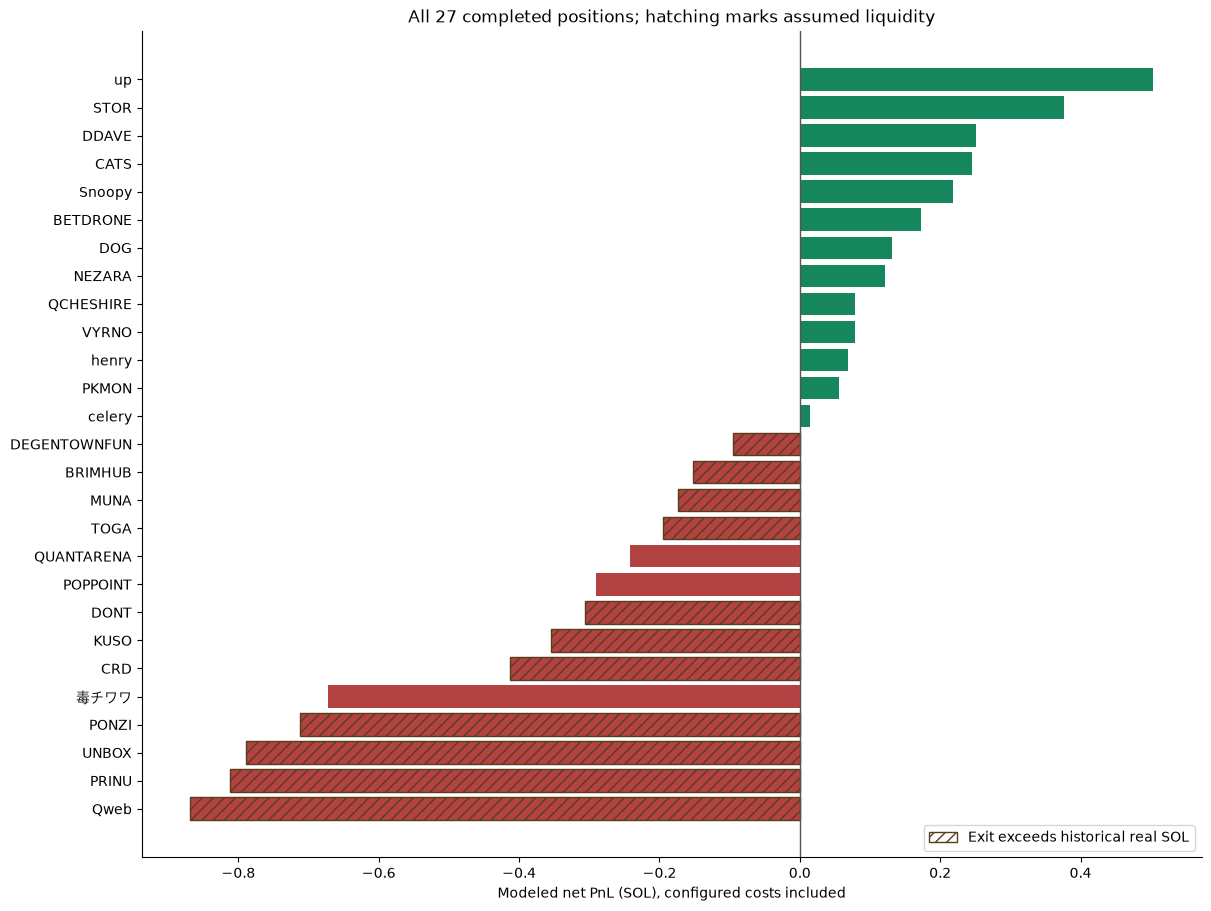

In [6]:
ordered = outcomes.sort_values('virtual_net_pnl_SOL')
fig, ax = plt.subplots(figsize=(12, 9), layout='constrained')
bars = ax.barh(ordered['token'], ordered['virtual_net_pnl_SOL'], color=['#16875c' if n > 0 else '#b34343' for n in ordered['virtual_net_pnl_SOL']])
for bar, shortfall in zip(bars, ordered['assumed_liquidity_SOL']):
    if shortfall > 0:
        bar.set_hatch('///')
        bar.set_edgecolor('#593d1b')
ax.axvline(0, color='#555', linewidth=1)
ax.set_xlabel('Modeled net PnL (SOL), configured costs included')
ax.set_title('All 27 completed positions; hatching marks assumed liquidity')
ax.legend(handles=[Patch(facecolor='white', edgecolor='#593d1b', hatch='///', label='Exit exceeds historical real SOL')], loc='lower right')
fig.savefig(EXPORT / 'pnl_all_positions.png', dpi=160)
plt.show()

## Historical curves with our buys and exits

The line is **historical curve valuation in SOL**, computed as virtual SOL / raw
virtual tokens × raw total supply. It is a pricing proxy, not a USD GMGN market
cap. The triangle and exit markers use each hypothetical fill's **average curve
execution price**, expressed on the same valuation scale, before external fees.
They can differ from the historical spot line because each order has size impact.

Purple stars show the selected early buyer's observed buys up to the actual
signal transaction. Green triangles mark our simulated buys. Blue exits fit
historical liquidity; orange exits use assumed liquidity. The dashed line marks
the five-minute deadline only for the seven strict-open positions. Each view
covers the launch through the relevant exit/deadline plus 30 seconds. Retained
curve history is kept separate from any migration-pool history.
Dashed horizontal tails show the last observed state carried forward by this
replay; they are not additional observed transactions or interpolated prices.

findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


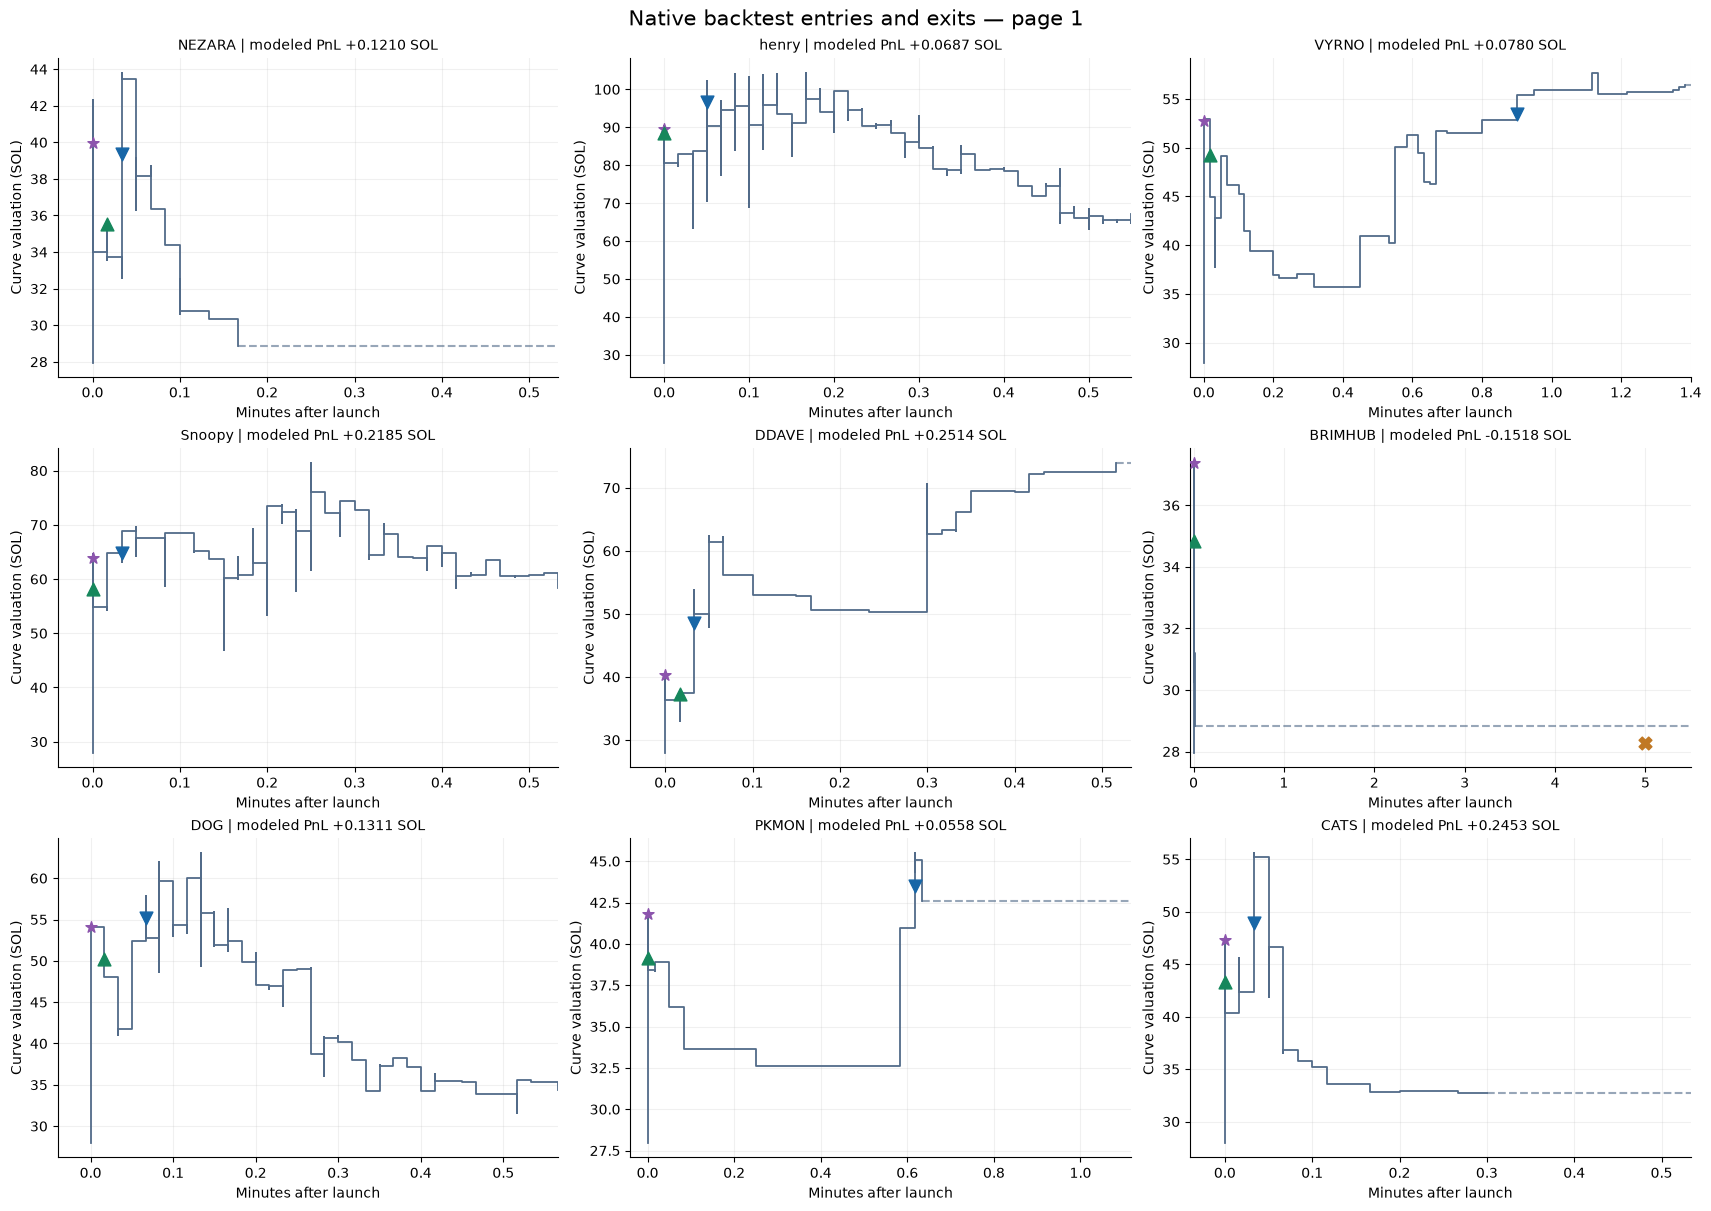

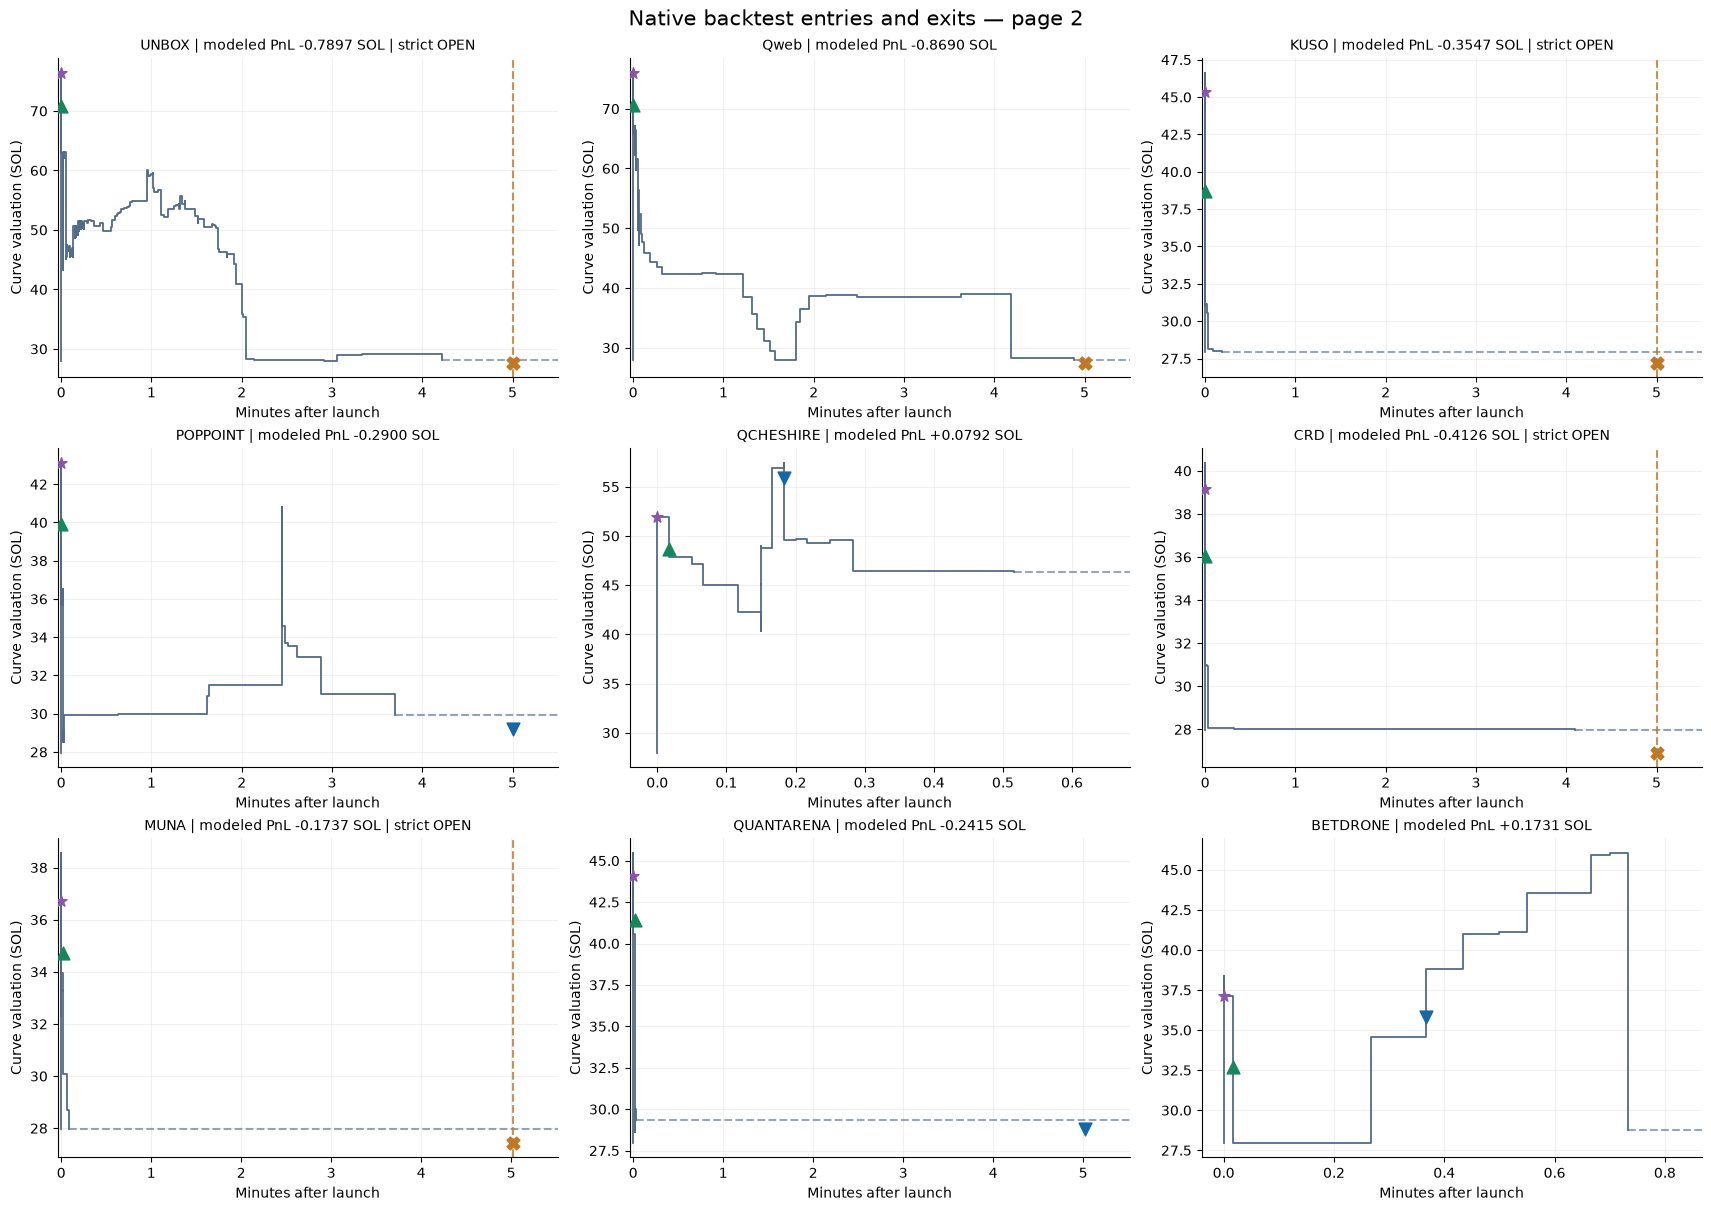

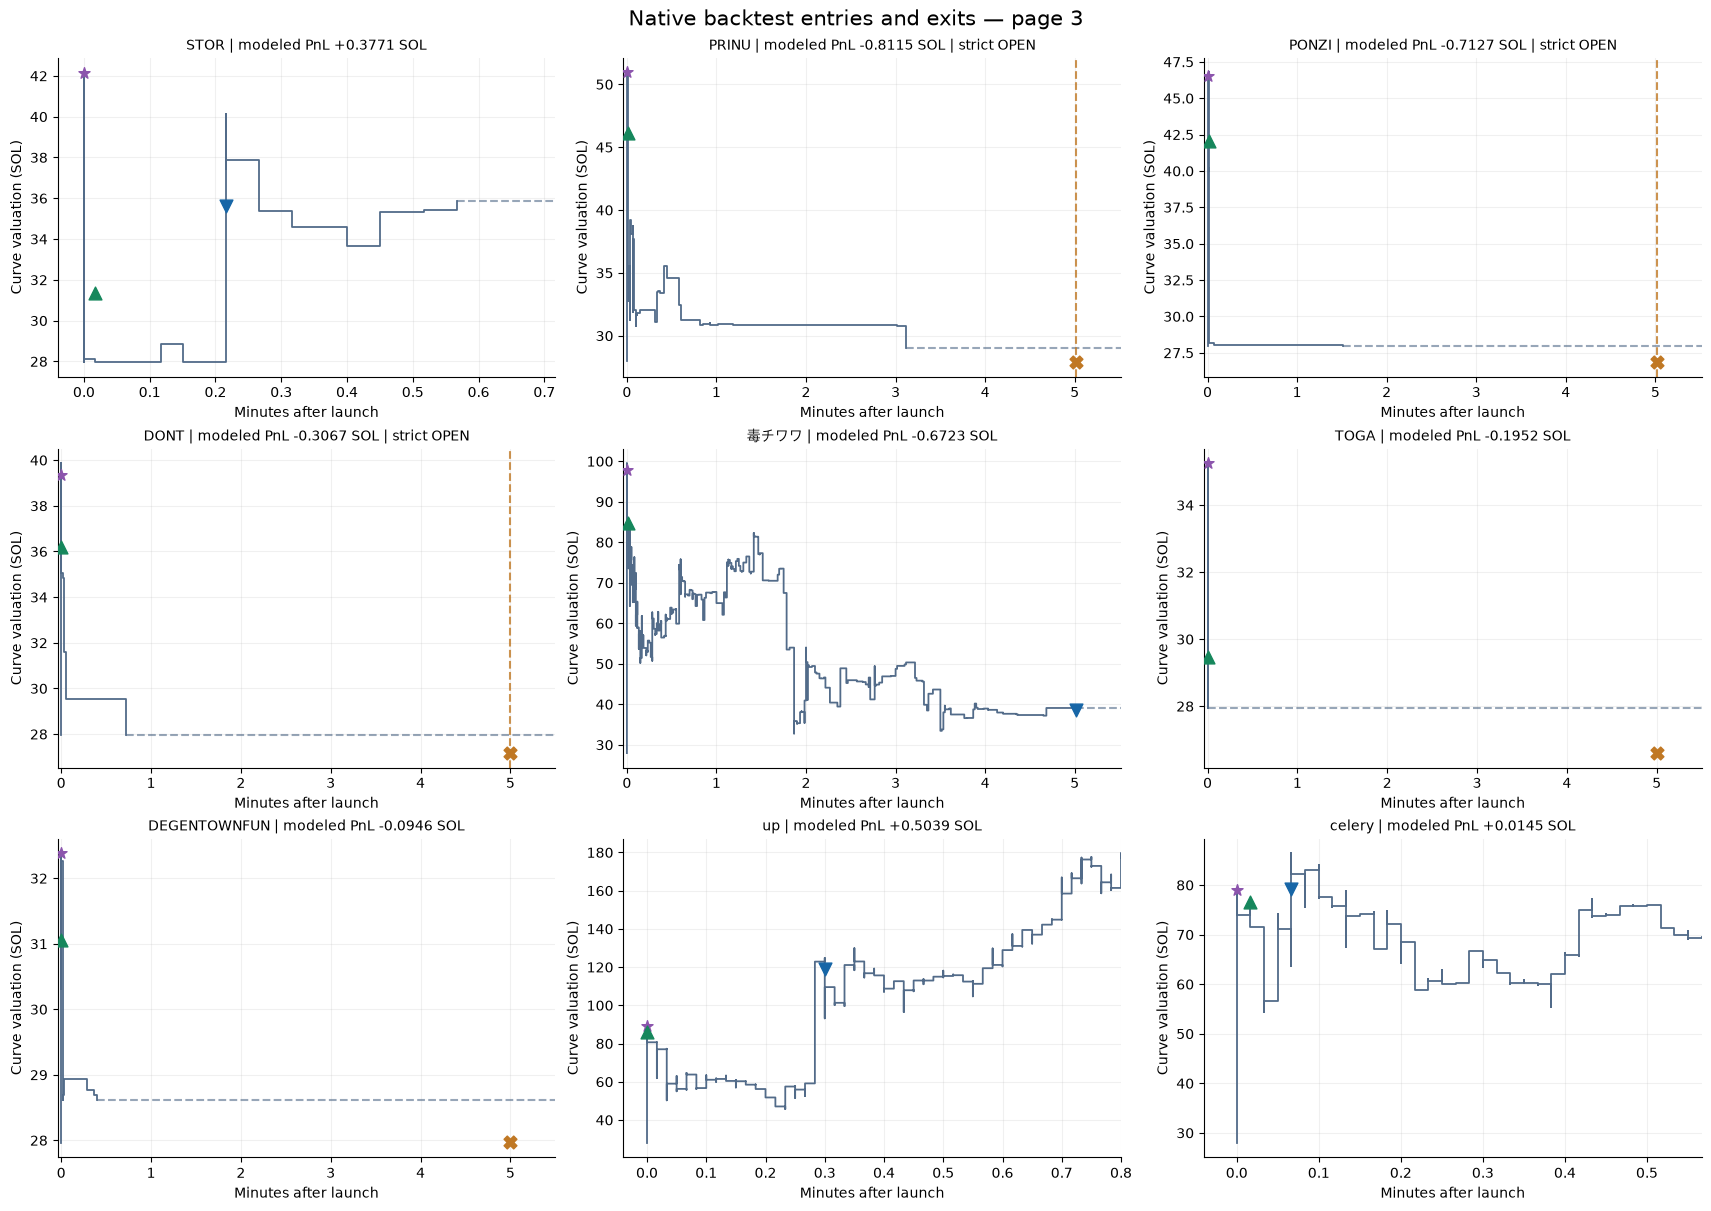

In [7]:
reservations = {name: {tx['correlation_id']: tx['boundary_ordinal'] for tx in run['ledger'] if tx['reason'] == 'ORDER_RESERVATION'} for name, run in runs.items()}
buy_lookup = {(r['run'], r['mint']): r for r in buy_records}

def history(mint):
    birth = births[mint]
    launch_time = parse_time(birth['block_time'] if birth['block_time'] is not None else json.loads(birth['decoded_extension_json'])['timestamp'])
    supply = int(birth['supply_raw'])
    rows = trades_by_mint[mint]
    frame = pd.DataFrame({
        'minutes': [0.0] + [(r['time'] - launch_time) / 60 for r in rows],
        'boundary': [(int(birth['slot']) << 32) + int(birth['tx_idx']) + 1] + [r['boundary'] for r in rows],
        'virtual_sol_raw': [int(birth['initial_virtual_quote_raw'])] + [int(r['virtual_quote']) for r in rows],
        'virtual_token_raw': [int(birth['initial_virtual_base_raw'])] + [int(r['virtual_base']) for r in rows],
        'real_sol_raw': [int(birth.get('initial_real_quote_raw') or 0)] + [int(r['real_quote']) for r in rows],
    })
    frame['valuation_SOL'] = frame['virtual_sol_raw'] / frame['virtual_token_raw'] * supply / LAMPORTS
    return frame, launch_time, supply

def token_curve(ax, mint, legend=False):
    p = rows_by_run['virtual'][mint]
    frame, launch_time, supply = history(mint)
    deadline = p['entry_time'] + runs['virtual']['summary']['policy']['holding_seconds']
    end_time = max(p['exit_time'], deadline if mint in blocked_mints else p['exit_time']) + 30
    end_min = (min(end_time, max(clock.values())) - launch_time) / 60
    frame = frame[frame['minutes'] <= end_min]
    ax.step(frame['minutes'], frame['valuation_SOL'], where='post', color='#526b89', linewidth=1.3)
    last = frame.iloc[-1]
    if last['minutes'] < end_min:
        ax.plot([last['minutes'], end_min], [last['valuation_SOL']] * 2, color='#526b89', linestyle='--', alpha=0.6)
    buy = fill_by_run_mint['virtual'][mint]['BUY']
    decision = reservations['virtual'][buy['order_id']]
    selected = [r for r in trades_by_mint[mint] if r['trader'] == p['sniper_wallet'] and r['side'] == 'buy' and r['boundary'] <= decision]
    ax.scatter([(r['time'] - launch_time) / 60 for r in selected], [r['virtual_quote'] / r['virtual_base'] * supply / LAMPORTS for r in selected], marker='*', s=70, color='#8c55ad', zorder=6)
    buy_value = buy_lookup['virtual', mint]['curve_deposit_SOL'] / buy['amount_out_atomic'] * supply
    ax.scatter([(p['entry_time'] - launch_time) / 60], [buy_value], marker='^', s=85, color='#16875c', zorder=7)
    sell = fill_by_run_mint['virtual'][mint]['SELL']
    sell_value = p['exit_gross_curve_lamports'] / LAMPORTS / sell['amount_in_atomic'] * supply
    synthetic = p['exit_synthetic_shortfall_lamports'] > 0
    ax.scatter([(p['exit_time'] - launch_time) / 60], [sell_value], marker='X' if synthetic else 'v', s=85, color='#c07824' if synthetic else '#1766a7', zorder=7)
    if mint in blocked_mints:
        ax.axvline((deadline - launch_time) / 60, color='#c07824', linestyle='--', alpha=0.8)
    ax.set_xlim(-0.04, max(end_min, 0.12))
    ax.set_xlabel('Minutes after launch')
    ax.set_ylabel('Curve valuation (SOL)')
    status = ' | strict OPEN' if mint in blocked_mints else ''
    ax.set_title(f"{p['symbol']} | modeled PnL {p['closed_pnl_lamports'] / LAMPORTS:+.4f} SOL{status}", fontsize=10)
    ax.grid(alpha=0.18)
    if legend:
        ax.legend(handles=[
            Line2D([], [], color='#526b89', label='Historical curve'),
            Line2D([], [], color='#526b89', linestyle='--', label='Last state held in replay'),
            Line2D([], [], marker='*', linestyle='', color='#8c55ad', label='Selected early buyer'),
            Line2D([], [], marker='^', linestyle='', color='#16875c', label='Our buy: average price'),
            Line2D([], [], marker='v', linestyle='', color='#1766a7', label='Our sell: no shortfall'),
            Line2D([], [], marker='X', linestyle='', color='#c07824', label='Our sell: assumed liquidity'),
        ], fontsize=8)

chronological = sorted(filled_mints, key=lambda m: rows_by_run['virtual'][m]['entry_slot'])
for start in range(0, len(chronological), 9):
    fig, axes = plt.subplots(3, 3, figsize=(17, 12), layout='constrained')
    for ax, mint in zip(axes.flat, chronological[start:start + 9]):
        token_curve(ax, mint)
    for ax in list(axes.flat)[len(chronological[start:start + 9]):]:
        ax.set_visible(False)
    page = start // 9 + 1
    fig.suptitle(f'Native backtest entries and exits — page {page}', fontsize=15)
    fig.savefig(EXPORT / f'entry_exit_page_{page}.png', dpi=160)
    plt.show()

## Seven liquidity-blocked positions and partial-sale capacity

The full-position sell quote below is reconstructed at the virtual run's actual
exit boundary from the last historical transaction **before** that boundary.
The existing Pump quote function confirms the strict rejection. The partial-sale
quantity is the largest raw balance whose gross curve output fits the recorded
real reserve; its quote is then checked by the same upstream function.

Partial-sale proceeds exclude rent refund because the account still holds tokens.
The net amount subtracts one configured network fee. A negative amount means the
small sale would cost more in network fees than it returns. This is a diagnostic
of the **recorded state**, not a repaired counterfactual strategy.

In [8]:
def state_before(mint, boundary):
    tape = trades_by_mint[mint]
    eligible = [r for r in tape if r['boundary'] < boundary]
    assert eligible, mint
    row = eligible[-1]
    birth = births[mint]
    state = PumpCurveStateV1(
        int(row['virtual_base']), int(row['virtual_quote']), int(row['real_base']), int(row['real_quote']),
        int(birth['supply_raw']), PumpCurveLifecycle.ACTIVE,
        PumpMode.TOKEN_2022 if birth['token_program'].startswith('Tokenz') else PumpMode.NORMAL,
    )
    return row, state

liquidity_records = []
for mint in blocked_mints:
    strict, virtual = rows_by_run['strict'][mint], rows_by_run['virtual'][mint]
    sell_fill = fill_by_run_mint['virtual'][mint]['SELL']
    historical, state = state_before(mint, sell_fill['boundary_ordinal'])
    quantity = int(sell_fill['amount_in_atomic'])
    now = int(virtual['exit_time'])
    fees = profile((int(historical['payload']['fee_basis_points']), int(historical['payload']['creator_fee_basis_points'])), now)
    virtual_quote = sell_quote(state, tokens_in_atomic=quantity, fee_profile=fees, effective_at_unix_s=now, liquidity_policy=PumpSellLiquidityPolicy.VIRTUAL_RESERVE_OUTPUT_WITH_EXPLICIT_SYNTHETIC_SHORTFALL_V1)
    assert virtual_quote.gross_curve_sol_lamports == virtual['exit_gross_curve_lamports']
    assert virtual_quote.synthetic_shortfall_lamports == virtual['exit_synthetic_shortfall_lamports']
    try:
        sell_quote(state, tokens_in_atomic=quantity, fee_profile=fees, effective_at_unix_s=now)
    except PumpQuoteError as error:
        assert error.code is PumpQuoteErrorCode.INSUFFICIENT_REAL_SOL_RESERVES
        rejection = error.code.value
    else:
        raise AssertionError('Expected the native strict reserve check to reject this full balance')
    low, high = 0, quantity
    x, y, real = state.virtual_sol_reserves_lamports, state.virtual_token_reserves_atomic, state.real_sol_reserves_lamports
    while low < high:
        middle = (low + high + 1) // 2
        if middle * x // (y + middle) <= real:
            low = middle
        else:
            high = middle - 1
    maximum_partial = low
    partial_receipt = None
    partial_error = ''
    if maximum_partial:
        try:
            partial = sell_quote(state, tokens_in_atomic=maximum_partial, fee_profile=fees, effective_at_unix_s=now)
            partial_receipt = partial.sol_out_lamports - runs['strict']['summary']['policy']['exit_network_fee_lamports']
        except PumpQuoteError as error:
            partial_error = error.code.value
    deadline = strict['entry_time'] + runs['strict']['summary']['policy']['holding_seconds']
    liquidity_records.append({
        'token': virtual['symbol'], 'mint': mint, 'gmgn_url': virtual['gmgn_url'],
        'buy_cost_SOL': strict['entry_cash_lamports'] / LAMPORTS,
        'full_balance_raw': quantity, 'full_sell_gross_SOL': virtual_quote.gross_curve_sol_lamports / LAMPORTS,
        'recorded_real_reserve_SOL': real / LAMPORTS,
        'assumed_shortfall_SOL': virtual_quote.synthetic_shortfall_lamports / LAMPORTS,
        'our_buy_curve_deposit_SOL': buy_lookup['virtual', mint]['curve_deposit_SOL'],
        'strict_quote_rejection': rejection, 'submitted_strict_sell_attempts': strict['exit_attempts'],
        'strict_failed_sell_fees_SOL': strict['failed_execution_cost_lamports'] / LAMPORTS,
        'virtual_exit_UTC': utc(now), 'deadline_UTC': utc(deadline),
        'follow_up_after_deadline_seconds': max(clock.values()) - deadline,
        'max_partial_sale_raw': maximum_partial, 'max_partial_sale_percent': 100 * maximum_partial / quantity,
        'partial_net_after_network_SOL': partial_receipt / LAMPORTS if partial_receipt is not None else np.nan,
        'partial_quote_error': partial_error,
        'virtual_net_pnl_SOL': virtual['closed_pnl_lamports'] / LAMPORTS,
    })
liquidity = pd.DataFrame(liquidity_records)
linked_table(liquidity[['token', 'gmgn_url', 'full_sell_gross_SOL', 'recorded_real_reserve_SOL', 'assumed_shortfall_SOL', 'submitted_strict_sell_attempts', 'max_partial_sale_percent', 'partial_net_after_network_SOL', 'virtual_net_pnl_SOL']], floats=9)
print('All seven full quotes reject against the recorded real reserves; zero sell submissions and zero failed-sell fees were charged.')

token,full_sell_gross_SOL,recorded_real_reserve_SOL,assumed_shortfall_SOL,submitted_strict_sell_attempts,max_partial_sale_percent,partial_net_after_network_SOL,virtual_net_pnl_SOL
UNBOX,0.492608375,0.113817432,0.378790943,0,22.813321545,0.112289713,-0.789749673
KUSO,0.782471229,0.000000007,0.782471222,0,0.000000996,-0.000104995,-0.354739282
CRD,1.120903763,0.000000011,1.120903752,0,0.000001031,-0.000104991,-0.412629933
MUNA,0.591433375,0.014499883,0.576933492,0,2.404503300,0.014213634,-0.173694964
PRINU,1.180741796,0.559728859,0.621012937,0,46.423547731,0.552627247,-0.811524738
PONZI,1.188826282,0.000000005,1.188826277,0,0.000000485,-0.000104997,-0.712726285
DONT,0.846539579,0.000000011,0.846539568,0,0.000001378,-0.000104991,-0.306697467


All seven full quotes reject against the recorded real reserves; zero sell submissions and zero failed-sell fees were charged.


findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


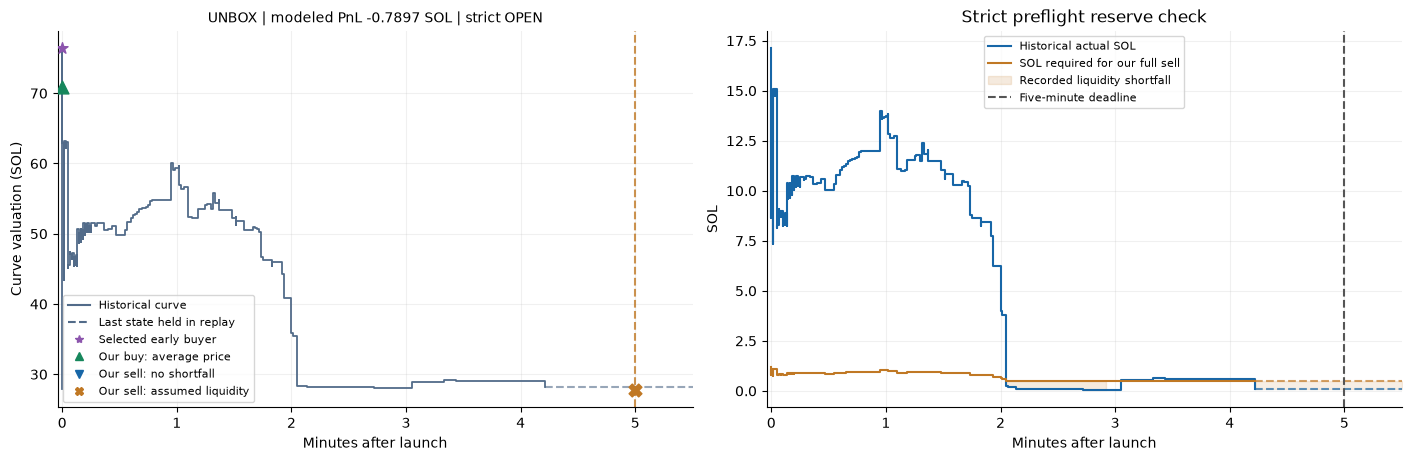

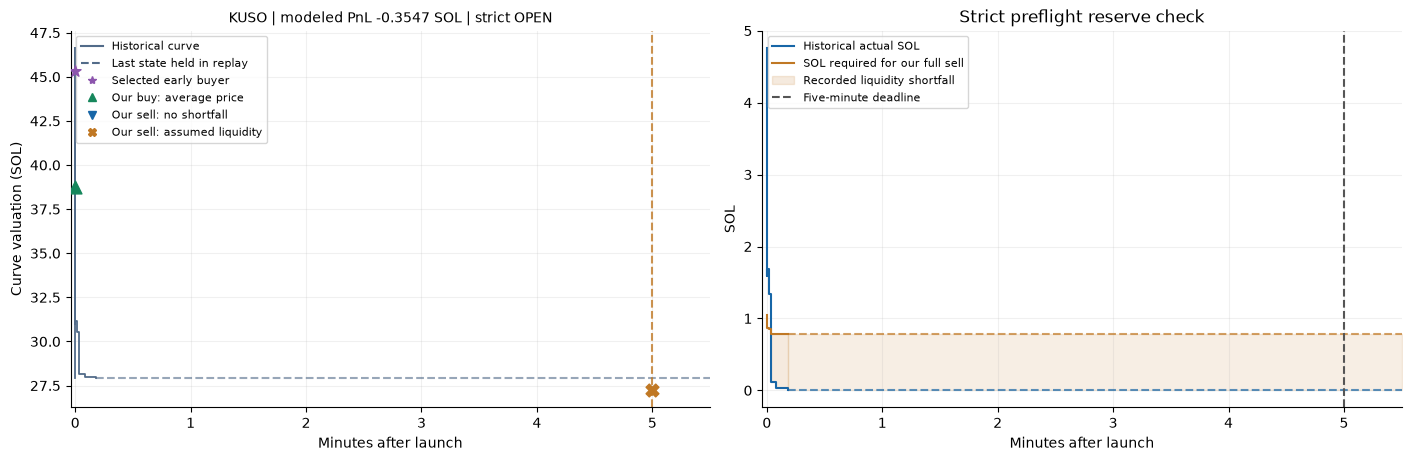

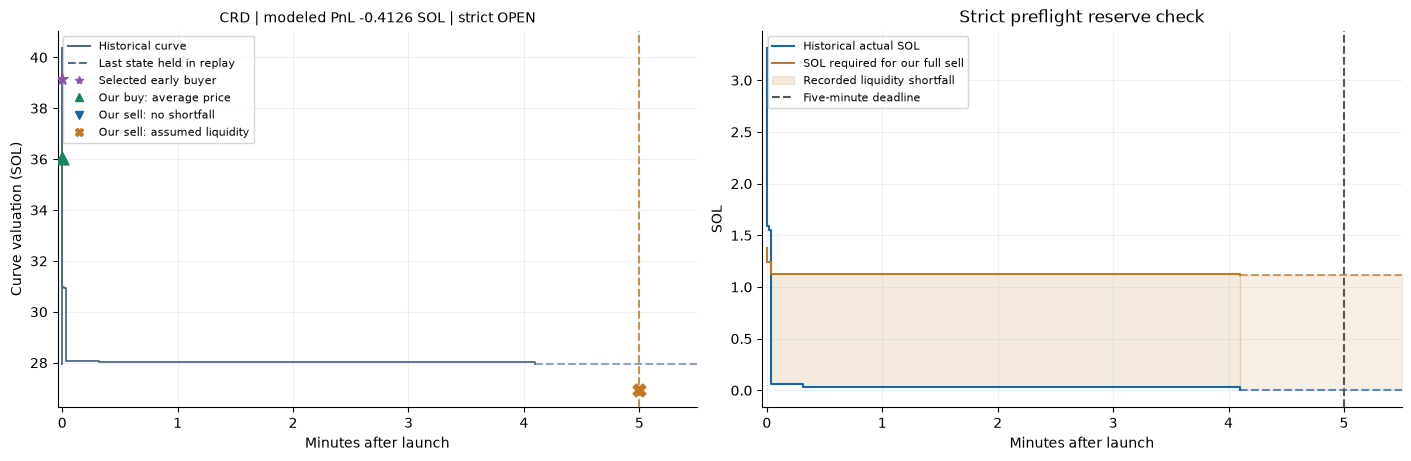

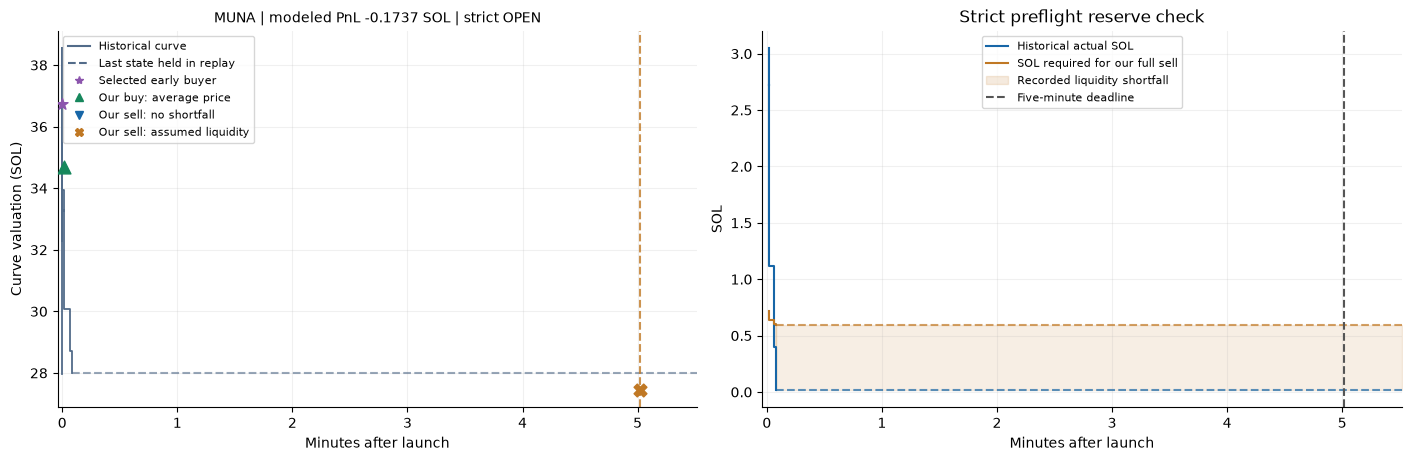

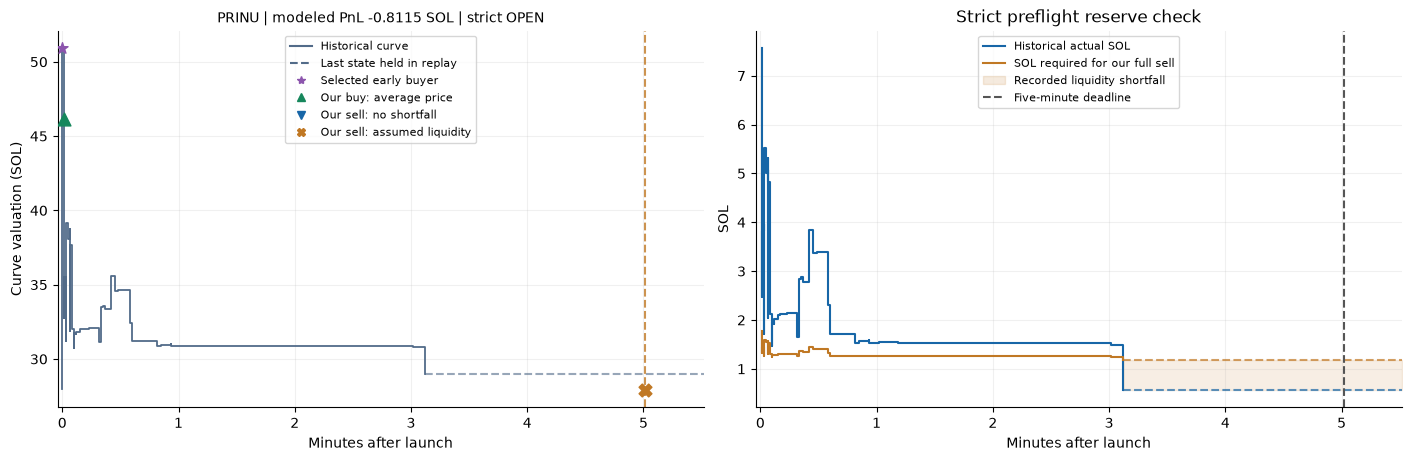

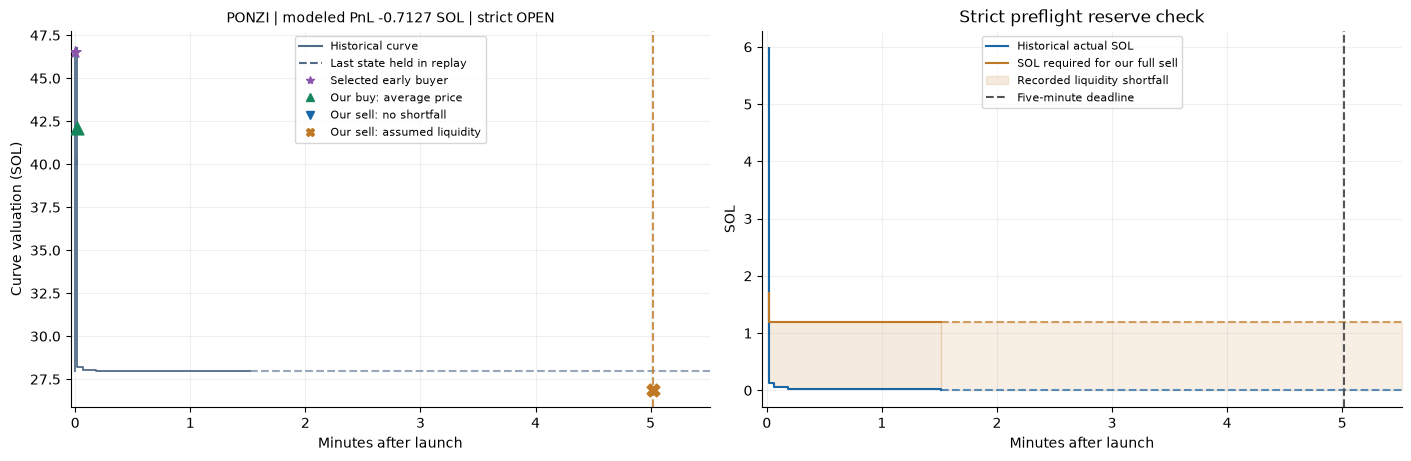

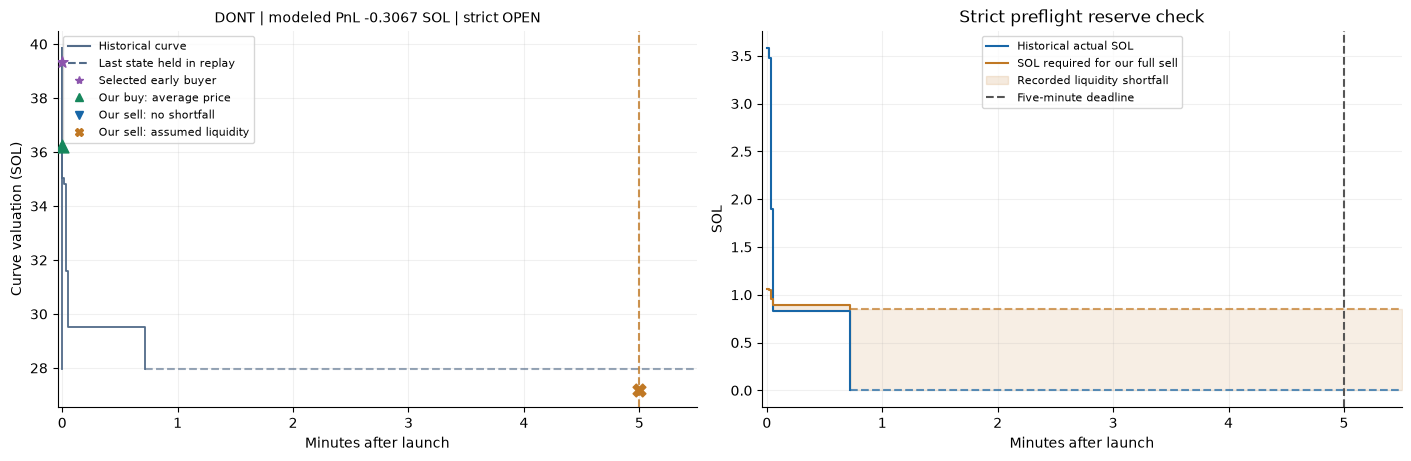

In [9]:
for mint in blocked_mints:
    p = rows_by_run['virtual'][mint]
    frame, launch_time, supply = history(mint)
    buy_fill = fill_by_run_mint['virtual'][mint]['BUY']
    deadline = p['entry_time'] + runs['strict']['summary']['policy']['holding_seconds']
    end_min = (deadline + 30 - launch_time) / 60
    entered = frame[(frame['boundary'] < buy_fill['boundary_ordinal'])].tail(1).copy()
    entered['minutes'] = (p['entry_time'] - launch_time) / 60
    later = frame[(frame['boundary'] >= buy_fill['boundary_ordinal']) & (frame['minutes'] <= end_min)]
    visible = pd.concat([entered, later]).copy()
    quantity = buy_fill['amount_out_atomic']
    required = np.array([int(quantity) * int(x) // (int(y) + int(quantity)) / LAMPORTS for x, y in zip(visible['virtual_sol_raw'], visible['virtual_token_raw'])])
    observed = visible['real_sol_raw'].to_numpy(dtype=float) / LAMPORTS
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout='constrained')
    token_curve(axes[0], mint, legend=True)
    axes[1].step(visible['minutes'], observed, where='post', color='#1766a7', label='Historical actual SOL')
    axes[1].step(visible['minutes'], required, where='post', color='#c07824', label='SOL required for our full sell')
    axes[1].fill_between(visible['minutes'], observed, required, where=required > observed, step='post', color='#c07824', alpha=0.15, label='Recorded liquidity shortfall')
    tail_start = visible['minutes'].iloc[-1]
    if tail_start < end_min:
        tail_x = [tail_start, end_min]
        axes[1].plot(tail_x, [observed[-1]] * 2, color='#1766a7', linestyle='--', alpha=0.7)
        axes[1].plot(tail_x, [required[-1]] * 2, color='#c07824', linestyle='--', alpha=0.7)
        axes[1].fill_between(tail_x, [observed[-1]] * 2, [required[-1]] * 2, color='#c07824', alpha=0.12)
    axes[1].axvline((deadline - launch_time) / 60, color='#555', linestyle='--', label='Five-minute deadline')
    axes[1].set(xlabel='Minutes after launch', ylabel='SOL', title='Strict preflight reserve check')
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.18)
    axes[1].set_xlim(axes[0].get_xlim())
    fig.savefig(EXPORT / f'liquidity_{mint}.png', dpi=160)
    plt.show()

## Inspect one token

Change `TOKEN` to any filled mint from the tables and rerun this cell. Its chart
and both saved position records are shown. Charts remain based on the frozen
historical tape; these orders are not newly simulated here.

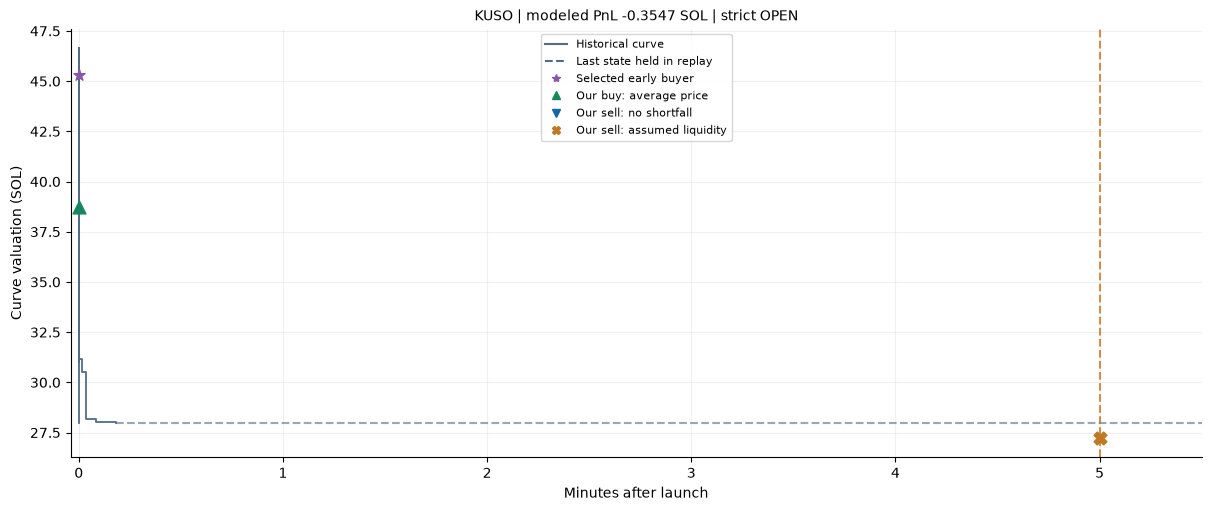

,0,1
run,strict,virtual
budget_lamports,1127219620,1127219620
closed_pnl_lamports,NaN,-354739282.0
creator,8Tkn47KhnHxZcbfKEUCKDC4N7kx8RAz6Q1WygZiUbcZg,8Tkn47KhnHxZcbfKEUCKDC4N7kx8RAz6Q1WygZiUbcZg
creator_fee_credit_enabled,1,1
developer_creator_fee_accrual_lamports,53032670,53032670
developer_creator_fee_accrual_sol,0.053032670,0.053032670
developer_observed_net_trade_cost_lamports,-379480029,-379480029
developer_observed_net_trade_cost_sol,-0.379480029,-0.379480029
developer_observed_tokens_raw,0,0


In [10]:
TOKEN = 'AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump'
assert TOKEN in filled_mints
fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
token_curve(ax, TOKEN, legend=True)
plt.show()
display(pd.DataFrame([dict(run=name, **rows_by_run[name][TOKEN]) for name in ['strict', 'virtual']]).T)

## Failed submissions and rejected entries

These are failures of **our simulated orders**. Minimum-output failures pay the
configured submitted-transaction cost. Capital rejections pay no submission fee.
The seven liquidity preflight rejections are not in this failure log because
there was no sell submission. The notebook does not invent failed-sell charges.

In [11]:
failure_records = []
for name, folder in RUN_DIRS.items():
    with (folder / 'execution_failures.csv').open() as stream:
        failures = list(csv.DictReader(stream))
    reserve_mint = {}
    paid_failure = defaultdict(int)
    # Reproduce the native strategy's content-derived BUY order identity.
    # This joins entry failures to tokens without guessing from shared slots.
    from backtest.domain.hashing import domain_digest
    component = domain_digest('dnipro.configured-sniper-window.v1', runs[name]['summary']['policy']).hex
    order_mints = {}
    for p in runs[name]['positions']:
        if 'signal_slot' not in p:
            continue
        boundaries = {r['boundary'] for r in trades_by_mint[p['mint']] if r['slot'] == p['signal_slot']}
        # Unfilled mints also need their own evidenced signal transaction.
        if not boundaries:
            boundaries = {r['boundary'] for r in all_trades if r['mint'] == p['mint'] and r['slot'] == p['signal_slot']}
        for boundary in boundaries:
            oid = domain_digest('dnipro.sniper-order.v1', {'mint': p['mint'], 'side': 'BUY', 'boundary': boundary, 'attempt': 0, 'component': component}).hex
            order_mints[oid] = p['mint']
    assert all(order_mints.get(sides['BUY']['order_id']) == mint for mint, sides in fill_by_run_mint[name].items())
    for tx in runs[name]['ledger']:
        for p in tx['postings']:
            if p['account_kind'] == 'NETWORK_FEE' and p['account_id'] == 'network:failed-execution':
                paid_failure[tx['correlation_id']] += p['amount_atomic']
            if tx['reason'] == 'ORDER_RESERVATION' and p['account_kind'] == 'PORTFOLIO_RESERVED' and p['asset_id'] != SOL:
                reserve_mint[tx['correlation_id']] = p['asset_id']
    for row in failures:
        oid = row['order_id']
        slot = int(row['boundary_ordinal']) >> 32
        mint = order_mints.get(oid, reserve_mint.get(oid))
        assert mint is not None, ('unmapped native failure', oid)
        position = rows_by_run[name][mint]
        failure_records.append({
            'run': name, 'token': position['symbol'], 'mint': mint, 'gmgn_url': position['gmgn_url'],
            'order_id': oid, 'slot': slot, 'time_UTC': utc(clock[slot]) if slot in clock else '',
            'failure_type': row['record_type'], 'reason': row['reason'],
            'submitted_network_fee_SOL': paid_failure[oid] / LAMPORTS,
        })
failures = pd.DataFrame(failure_records)
linked_table(failures.drop(columns=['order_id', 'mint']))
assert int(round(failures.loc[failures['run'] == 'virtual', 'submitted_network_fee_SOL'].sum() * LAMPORTS)) == runs['virtual']['summary']['failed_entry_cost_lamports']
signal_records = []
for name, run in runs.items():
    for p in run['positions']:
        if 'signal_slot' in p:
            signal_records.append({'run': name, 'token': p['symbol'], 'mint': p['mint'], 'gmgn_url': p['gmgn_url'], 'status': p['status'], 'reason': p['reason'], 'signal_slot': p['signal_slot'], 'requested_buy_budget_SOL': p['budget_lamports'] / LAMPORTS, 'buy_cash_cost_SOL': p['entry_cash_lamports'] / LAMPORTS, 'closed_pnl_SOL': p['closed_pnl_lamports'] / LAMPORTS if p.get('closed_pnl_lamports') is not None else None})
signals = pd.DataFrame(signal_records)
print('All 38 signals in each run, including unfilled entries, are exported separately.')

run,token,slot,time_UTC,failure_type,reason,submitted_network_fee_SOL
strict,p-,455316088,2026-10-10T16:09:09+00:00,ORDER_EXECUTION_FAILED_AND_RELEASED,MINIMUM_OUTPUT_NOT_MET,0.000105
strict,PAYROLL,455319610,2026-10-10T16:22:02+00:00,ORDER_EXECUTION_FAILED_AND_RELEASED,MINIMUM_OUTPUT_NOT_MET,0.000105
strict,ECX,455320466,2026-10-10T16:25:11+00:00,ORDER_EXECUTION_FAILED_AND_RELEASED,MINIMUM_OUTPUT_NOT_MET,0.000105
strict,PAYROLL,455322673,2026-10-10T16:33:13+00:00,ORDER_REJECTED,RISK_REJECTED,0.000000
strict,FUND,455322765,2026-10-10T16:33:35+00:00,ORDER_EXECUTION_FAILED_AND_RELEASED,MINIMUM_OUTPUT_NOT_MET,0.000105
strict,MASCHINA,455325537,2026-10-10T16:43:43+00:00,ORDER_REJECTED,RISK_REJECTED,0.000000
strict,PAGENT,455325689,2026-10-10T16:44:15+00:00,ORDER_EXECUTION_FAILED_AND_RELEASED,MINIMUM_OUTPUT_NOT_MET,0.000105
strict,毒チワワ,455326949,2026-10-10T16:48:50+00:00,ORDER_REJECTED,RISK_REJECTED,0.000000
strict,TOGA,455327461,2026-10-10T16:50:40+00:00,ORDER_REJECTED,RISK_REJECTED,0.000000
strict,DEGENTOWNFUN,455328348,2026-10-10T16:53:54+00:00,ORDER_REJECTED,RISK_REJECTED,0.000000


All 38 signals in each run, including unfilled entries, are exported separately.


## Developer fees and break-even

Reference-buyer cost now subtracts **creator fees accrued to that wallet before
its signal transaction**. Event creator/recipient fields and explicit shareholder
splits determine attribution; the launch creator is not assumed to receive every
fee. Claims do not create a second income credit. Unknown recipients and shared
rounding dust are retained as unallocated.

The developer table below separates historical trade cashflow, accrued creator
fees and additional fees from our hypothetical filled orders. Vault accrual is a
receivable estimate, not a proven wallet withdrawal. Cashflow plus accrual is
**not full realized or marked PnL**, particularly if observed tokens remain.
Future historical fee volume and fees from our planned buy do not enter the
signal's cost; fees from filled simulated orders appear separately here.

The old snapshots and runs are preserved. Both fee-aware reruns produced the
same entries, sizes and trading PnL: none of the 38 selected reference buyers
received creator-fee income by their entry signal.

In [12]:
BASELINE_DIRS = {
    'strict': ROOT / 'var/dnipro/sniper-window-20261010-primary-v2',
    'virtual': ROOT / 'var/dnipro/sniper-window-20261010-virtual-v1',
}
comparison = []
for name, folder in BASELINE_DIRS.items():
    old = json.loads((folder / 'result.json').read_text())
    for before in old['positions']:
        after = rows_by_run[name][before['mint']]
        for key, value in before.items():
            assert after.get(key) == value, (name, before['mint'], key)
    assert old['summary']['realized_net_pnl_lamports'] == runs[name]['summary']['realized_net_pnl_lamports']
    comparison.append({'run': name, 'PnL_before_SOL': old['summary']['realized_net_pnl_lamports'] / LAMPORTS,
                       'PnL_after_SOL': runs[name]['summary']['realized_net_pnl_lamports'] / LAMPORTS,
                       'reference_buyers_receiving_creator_income': runs[name]['summary']['fee_receiving_anchor_signals'],
                       'entries_sizes_and_exits_unchanged': True})
fee_comparison = pd.DataFrame(comparison)
display(fee_comparison)

# Attribute each filled order's paid creator fee using its evidenced route.
# This does not add developer income to our trading wallet or rerun execution.
simulated_income = CreatorFeeIncome()
simulated_fee_total = 0
for fill in runs['virtual']['fills']:
    mint = fill['pool_id']
    latest = [r for r in trades_by_mint[mint] if r['boundary'] <= fill['boundary_ordinal']][-1]
    tx = settlements['virtual'][fill['order_id']]
    creator_fee = sum(p['amount_atomic'] for p in tx['postings'] if p['account_kind'] == 'CREATOR_FEE' and p['asset_id'] == SOL)
    simulated_fee_total += creator_fee
    simulated_income.observe('our-fill:' + fill['order_id'], dict(latest, creator_fee=creator_fee))
simulated_income.verify()
assert sum(simulated_income.total.values()) == simulated_fee_total

developer_records = []
for mint in filled_mints:
    p = rows_by_run['virtual'][mint]
    creator = p['creator']
    buy = fill_by_run_mint['virtual'][mint]['BUY']
    signal_boundary = reservations['virtual'][buy['order_id']]
    at_signal = CreatorFeeIncome()
    dev_cost = 0
    paid_signatures = set()
    for trade in trades_by_mint[mint]:
        if trade['boundary'] > signal_boundary:
            break
        at_signal.observe(trade['event_uid'], trade)
        if trade['trader'] == creator:
            fee = 0
            if trade['fee_payer'] == creator and trade['signature'] not in paid_signatures and trade.get('network_fee') is not None:
                fee = int(trade['network_fee'])
                paid_signatures.add(trade['signature'])
            charged = int(trade['protocol_fee']) + int(trade['creator_fee'])
            dev_cost += int(trade['quote']) + charged + fee if trade['side'] == 'buy' else -(int(trade['quote']) - charged - fee)
    chosen_income = at_signal.income(mint, p['sniper_wallet'])
    assert chosen_income == p['sniper_creator_fee_income_lamports']
    additional = simulated_income.income(mint, creator)
    historical = p['developer_creator_fee_accrual_lamports']
    developer_records.append({
        'token': p['symbol'], 'mint': mint, 'gmgn_url': p['gmgn_url'],
        'developer_gmgn': 'https://gmgn.ai/sol/address/' + creator,
        'dev_trade_cost_by_signal_SOL': dev_cost / LAMPORTS,
        'dev_fee_accrual_by_signal_SOL': at_signal.income(mint, creator) / LAMPORTS,
        'dev_adjusted_net_cost_by_signal_SOL': (dev_cost - at_signal.income(mint, creator)) / LAMPORTS,
        'selected_reference_fee_income_SOL': chosen_income / LAMPORTS,
        'dev_historical_trade_cashflow_SOL': -p['developer_observed_net_trade_cost_lamports'] / LAMPORTS,
        'dev_historical_creator_fee_accrual_SOL': historical / LAMPORTS,
        'dev_additional_fees_from_our_fills_SOL': additional / LAMPORTS,
        'dev_cashflow_plus_accrual_with_our_fees_SOL': (-p['developer_observed_net_trade_cost_lamports'] + historical + additional) / LAMPORTS,
        'dev_observed_remaining_tokens_raw': p['developer_observed_tokens_raw'],
        'income_basis': 'accrual, not confirmed withdrawal',
    })
developers = pd.DataFrame(developer_records).sort_values('dev_historical_creator_fee_accrual_SOL', ascending=False)
linked_table(developers[['token', 'gmgn_url', 'dev_historical_trade_cashflow_SOL', 'dev_historical_creator_fee_accrual_SOL', 'dev_additional_fees_from_our_fills_SOL', 'dev_cashflow_plus_accrual_with_our_fees_SOL', 'dev_observed_remaining_tokens_raw']])
print('Full supported cohort creator-fee accrual:', runs['virtual']['summary']['observed_creator_fee_accrual_lamports'] / LAMPORTS, 'SOL')
print('Shared rounding/unallocated remainder:', runs['virtual']['summary']['unallocated_creator_fee_accrual_lamports'], 'lamports')

,run,PnL_before_SOL,PnL_after_SOL,reference_buyers_receiving_creator_income,entries_sizes_and_exits_unchanged
0,strict,0.433958,0.433958,0,True
1,virtual,-3.759502,-3.759502,0,True


token,dev_historical_trade_cashflow_SOL,dev_historical_creator_fee_accrual_SOL,dev_additional_fees_from_our_fills_SOL,dev_cashflow_plus_accrual_with_our_fees_SOL,dev_observed_remaining_tokens_raw
up,0.000000,3.093180,0.010213,3.103394,0
VYRNO,0.208019,1.705811,0.008276,1.922106,0
henry,0.000000,1.457742,0.006537,1.464279,0
DDAVE,-1.200110,1.069337,0.006379,-0.124394,40779097347944
毒チワワ,0.000000,1.018195,0.005191,1.023386,0
celery,0.000000,0.535657,0.011055,0.546712,0
Snoopy,0.000000,0.510524,0.015445,0.525969,0
DOG,0.000000,0.417225,0.011329,0.428554,0
CATS,0.000000,0.361172,0.015024,0.376196,0
Qweb,0.870715,0.349196,0.005769,1.225679,0


Full supported cohort creator-fee accrual: 154.260004195 SOL
Shared rounding/unallocated remainder: 71 lamports


## Every liquidity-shortfall case: native decisions, slots and observed inventory

The new native reruns persist `strategy_trace.csv` and `order_audit.csv`.
The old runs logged fills, ledger postings and order failures, but did not
retain every entry candidate and exit preflight decision. These new traces
reproduce the same token-level outcomes and costs, and are not inferred logs.

This section covers **all 11** completed-run exits with a positive shortfall,
including the seven strict-open positions. Historical wallet inventory means
**observed buys minus observed sells**. Transfers and complete balance states
are absent, so this is not an exact holder census. Negative observed inventory
is retained as a coverage warning. Our hypothetical wallet is separate.

Slot-end views include all retained transactions in that slot. The signal and
landing checkpoints use the exact transaction boundary instead; they prevent
later transactions in the same slot from leaking into entry explanations.

In [13]:
from backtest.plugins.strategies.sniper_window import threshold
from backtest.plugins.protocols.pumpfun.model import buy_quote
from decimal import Decimal
from bisect import bisect_right

shortfall_mints = [m for m in filled_mints if rows_by_run['virtual'][m].get('exit_synthetic_shortfall_lamports', 0) > 0]
assert len(shortfall_mints) == 11 and set(blocked_mints).issubset(shortfall_mints)
trace_records = []
audit_records = []
for name, directory in RUN_DIRS.items():
    with (directory / 'strategy_trace.csv').open() as stream:
        records = list(csv.DictReader(stream))
    for record in records:
        for field in ['boundary_ordinal', 'slot', 'time']:
            record[field] = int(record[field])
        trace_records.append(dict(run=name, **record))
    with (directory / 'order_audit.csv').open() as stream:
        audit_records.extend(dict(run=name, **r) for r in csv.DictReader(stream))
strategy_trace = pd.DataFrame(trace_records)
native_order_audit = pd.DataFrame(audit_records)
# Prove instrumentation preserved every saved per-token field and economic result.
for name in RUN_DIRS:
    old_dir = ROOT / ('var/dnipro/sniper-window-20261010-creator-fees-' + name + '-v1')
    previous = json.loads((old_dir / 'result.json').read_text())
    assert previous['positions'] == runs[name]['positions']
    for field in ['realized_net_pnl_lamports', 'filled_entries', 'closed_positions', 'open_positions', 'synthetic_shortfall_lamports']:
        assert previous['summary'][field] == runs[name]['summary'][field]
assert set(strategy_trace['mint']) == set(shortfall_mints)
print(f'Native decision records: {len(strategy_trace):,}; native order audit records: {len(native_order_audit):,}.')

def state_from(mint, observed=None):
    b = births[mint]
    x = int(observed['virtual_quote']) if observed else int(b['initial_virtual_quote_raw'])
    y = int(observed['virtual_base']) if observed else int(b['initial_virtual_base_raw'])
    real = int(observed['real_quote']) if observed else int(b.get('initial_real_quote_raw') or 0)
    real_y = int(observed['real_base']) if observed else int(b['initial_real_base_raw'])
    return PumpCurveStateV1(y, x, real_y, real, int(b['supply_raw']),
                           PumpCurveLifecycle.ACTIVE if real_y else PumpCurveLifecycle.COMPLETED,
                           PumpMode.TOKEN_2022 if b['token_program'].startswith('Tokenz') else PumpMode.NORMAL)

def recorded_quote(mint, quantity, observed, now):
    if quantity <= 0 or observed is None:
        return None
    return sell_quote(state_from(mint, observed), tokens_in_atomic=quantity,
        fee_profile=profile((int(observed['payload']['fee_basis_points']), int(observed['payload']['creator_fee_basis_points'])), now),
        effective_at_unix_s=now,
        liquidity_policy=PumpSellLiquidityPolicy.VIRTUAL_RESERVE_OUTPUT_WITH_EXPLICIT_SYNTHETIC_SHORTFALL_V1)

wallet_event_records, holder_slot_records, holder_checkpoint_records, slot_records, case_records, holder_economic_records = [], [], [], [], [], []
for mint in shortfall_mints:
    p = rows_by_run['virtual'][mint]
    b = births[mint]
    anchor = p['sniper_wallet']
    buy = fill_by_run_mint['virtual'][mint]['BUY']
    sell = fill_by_run_mint['virtual'][mint]['SELL']
    signal_boundary = reservations['virtual'][buy['order_id']]
    entry_boundary = buy['boundary_ordinal']
    exit_boundary = sell['boundary_ordinal']
    checkpoints = [('signal_after_transaction', signal_boundary, True), ('buy_landing_before_slot_trades', entry_boundary, False), ('exit_landing_before_slot_trades', exit_boundary, False)]
    ledgers = defaultdict(lambda: {'tokens': 0, 'cost': 0, 'bought': 0})
    paid = set()
    income = CreatorFeeIncome()
    last = None
    snapshots = []
    boundaries = []
    tape = trades_by_mint[mint]
    for trade in tape:
        w = trade['trader']
        before = dict(ledgers[w])
        fee = 0
        if trade['fee_payer'] == w and trade['signature'] not in paid and trade.get('network_fee') is not None:
            fee = int(trade['network_fee'])
            paid.add(trade['signature'])
        charges = int(trade['protocol_fee']) + int(trade['creator_fee'])
        before_adjusted_cost = before['cost'] - income.income(mint, w)
        full_before = recorded_quote(mint, before['tokens'], last, trade['time']) if trade['side'] == 'sell' else None
        sign = 1 if trade['side'] == 'buy' else -1
        ledgers[w]['tokens'] += sign * int(trade['tokens'])
        ledgers[w]['cost'] += int(trade['quote']) + charges + fee if sign == 1 else -(int(trade['quote']) - charges - fee)
        if sign == 1:
            ledgers[w]['bought'] += int(trade['quote']) + charges
        income.observe(trade['event_uid'], trade)
        if trade['side'] == 'sell':
            net_receipt = int(trade['quote']) - charges - fee
            full_pnl = full_before.sol_out_lamports - fee - before_adjusted_cost if full_before else None
        else:
            net_receipt = None
            full_pnl = None
        wallet_event_records.append({
            'token': p['symbol'], 'mint': mint, 'gmgn_url': p['gmgn_url'],
            'slot': int(trade['slot']), 'tx_idx': int(trade['tx_idx']), 'boundary_ordinal': trade['boundary'],
            'time_UTC': utc(trade['time']), 'event_uid': trade['event_uid'], 'signature': trade['signature'],
            'wallet': w, 'wallet_gmgn': 'https://gmgn.ai/sol/address/' + w,
            'is_anchor': w == anchor, 'is_launch_creator': w == p['creator'], 'side': trade['side'],
            'tokens_raw': int(trade['tokens']), 'curve_quote_lamports': int(trade['quote']),
            'protocol_fee_lamports': int(trade['protocol_fee']), 'creator_fee_lamports': int(trade['creator_fee']),
            'attributed_network_fee_lamports': fee, 'net_sell_receipt_lamports': net_receipt,
            'observed_tokens_before': before['tokens'], 'observed_tokens_after': ledgers[w]['tokens'],
            'observed_cash_cost_after': ledgers[w]['cost'],
            'creator_fee_accrual_after': income.income(mint, w),
            'full_exit_pnl_at_pretrade_state_lamports': full_pnl,
            'sold_entire_observed_position': sign == -1 and int(trade['tokens']) == before['tokens'],
            'closed_observed_cashflow_lamports': -ledgers[w]['cost'] if ledgers[w]['tokens'] == 0 else None,
            'coverage_negative_inventory': ledgers[w]['tokens'] < 0,
        })
        last = trade
        assert sum(value['tokens'] for value in ledgers.values()) == int(b['initial_virtual_base_raw'])-int(trade['virtual_base']), (mint,trade['event_uid'],'observed inventory conservation')
        boundaries.append(trade['boundary'])
        snapshots.append({w: dict(value, creator_income=income.income(mint, w)) for w, value in ledgers.items()})
    assert len(boundaries) == len(snapshots)

    def snapshot_at(boundary, inclusive):
        i = (bisect_right(boundaries, boundary) if inclusive else bisect_left(boundaries, boundary)) - 1
        return (snapshots[i], tape[i]) if i >= 0 else ({}, None)

    for name, boundary, inclusive in checkpoints:
        snapshot, observed = snapshot_at(boundary, inclusive)
        for w, ledger in snapshot.items():
            holder_checkpoint_records.append(dict(
                token=p['symbol'], mint=mint, gmgn_url=p['gmgn_url'], checkpoint=name,
                boundary_ordinal=boundary, slot=boundary >> 32, wallet=w,
                wallet_gmgn='https://gmgn.ai/sol/address/' + w, is_anchor=w == anchor,
                is_launch_creator=w == p['creator'], observed_tokens_raw=ledger['tokens'],
                supply_pct=ledger['tokens'] / int(b['supply_raw']) * 100,
                observed_cash_cost_lamports=ledger['cost'], creator_fee_accrual_lamports=ledger['creator_income'],
                coverage_negative_inventory=ledger['tokens'] < 0))
        observed_state = state_from(mint, observed)
        checkpoint_bps = (int(observed['payload']['fee_basis_points']), int(observed['payload']['creator_fee_basis_points']))
        if name == 'signal_after_transaction':
            our_quote = buy_quote(observed_state, spendable_gross_sol_lamports=p['budget_lamports'],
                fee_profile=profile(checkpoint_bps,p['signal_time']), effective_at_unix_s=p['signal_time'])
            own_q, deposit = our_quote.tokens_out_atomic, our_quote.net_curve_sol_lamports
        else:
            own_q = buy['amount_out_atomic']
            deposit = sum(posting['amount_atomic'] for posting in settlements['virtual'][buy['order_id']]['postings'] if posting['account_kind']=='VENUE' and posting['asset_id']==SOL)
        if name != 'exit_landing_before_slot_trades':
            hypothetical = PumpCurveStateV1(observed_state.virtual_token_reserves_atomic-own_q,
                observed_state.virtual_sol_reserves_lamports+deposit,
                observed_state.real_token_reserves_atomic-own_q,observed_state.real_sol_reserves_lamports+deposit,
                observed_state.token_total_supply_atomic,observed_state.lifecycle,observed_state.mode)
            for w, ledger in snapshot.items():
                net_cost = ledger['cost']-ledger['creator_income']
                amount = ledger['tokens']
                q = sell_quote(hypothetical,tokens_in_atomic=amount,
                    fee_profile=profile(checkpoint_bps,p['signal_time']),effective_at_unix_s=p['signal_time'],
                    liquidity_policy=PumpSellLiquidityPolicy.VIRTUAL_RESERVE_OUTPUT_WITH_EXPLICIT_SYNTHETIC_SHORTFALL_V1) if amount>0 else None
                break_even = threshold(hypothetical,amount,net_cost+105000,checkpoint_bps) if amount>0 and net_cost+105000>0 else None
                hypothetical_pnl = q.sol_out_lamports-net_cost-105000 if q else None
                holder_economic_records.append(dict(token=p['symbol'],mint=mint,gmgn_url=p['gmgn_url'],checkpoint=name,
                    slot=boundary>>32,wallet=w,wallet_gmgn='https://gmgn.ai/sol/address/'+w,is_anchor=w==anchor,
                    is_launch_creator=w==p['creator'],observed_tokens_raw=amount,supply_pct=amount/int(b['supply_raw'])*100,
                    historical_trade_cashflow_lamports=-ledger['cost'],historical_creator_fee_accrual_lamports=ledger['creator_income'],
                    historical_cashflow_plus_fee_accrual_lamports=-net_cost,
                    hypothetical_full_exit_pnl_after_our_buy_lamports=hypothetical_pnl,
                    hypothetical_exit_shortfall_after_our_buy_lamports=q.synthetic_shortfall_lamports if q else None,
                    profitable_full_exit_after_our_buy=q is not None and hypothetical_pnl>=0 and q.synthetic_shortfall_lamports==0,
                    profitable_threshold_below_our_target=amount>0 and (break_even is None or break_even<Decimal(p['signal_our_threshold'])),
                    wallet_break_even_virtual_SOL=float(break_even)/LAMPORTS if break_even is not None else None,
                    our_signal_target_virtual_SOL=float(p['signal_our_threshold'])/LAMPORTS,
                    assumed_exit_network_fee_lamports=105000,scenario='our buy applied once; other orders unchanged'))
        if name == 'signal_after_transaction':
            assert snapshot[anchor]['tokens'] == p['sniper_tokens']
            assert snapshot[anchor]['cost'] - snapshot[anchor]['creator_income'] == p['sniper_cost_lamports']
        if name == 'buy_landing_before_slot_trades':
            entry_snapshot, entry_observed = snapshot, observed

    entry_state = state_from(mint, entry_observed)
    # Obtain integer deposit directly from the native ledger, not the display float.
    own_deposit = sum(posting['amount_atomic'] for posting in settlements['virtual'][buy['order_id']]['postings'] if posting['account_kind'] == 'VENUE' and posting['asset_id'] == SOL)
    after_entry = PumpCurveStateV1(entry_state.virtual_token_reserves_atomic - buy['amount_out_atomic'],
        entry_state.virtual_sol_reserves_lamports + own_deposit,
        entry_state.real_token_reserves_atomic - buy['amount_out_atomic'],
        entry_state.real_sol_reserves_lamports + own_deposit,
        entry_state.token_total_supply_atomic, entry_state.lifecycle, entry_state.mode)
    entry_ledger = entry_snapshot.get(anchor, {'tokens': 0, 'cost': 0, 'creator_income': 0})
    bps = (int(entry_observed['payload']['fee_basis_points']), int(entry_observed['payload']['creator_fee_basis_points']))
    needed = ((p['entry_cash_lamports'] - runs['virtual']['summary']['policy']['account_rent_refund_lamports']) * 10500 + 9999) // 10000 + 105000
    xs_entry = threshold(after_entry, entry_ledger['tokens'], entry_ledger['cost'] - entry_ledger['creator_income'], bps) if min(entry_ledger['tokens'], entry_ledger['cost'] - entry_ledger['creator_income']) > 0 else None
    xt_entry = threshold(after_entry, buy['amount_out_atomic'], needed, bps)
    epsilon = runs['virtual']['summary']['policy']['epsilon_lamports']
    completion = Decimal(after_entry.virtual_sol_reserves_lamports * after_entry.virtual_token_reserves_atomic) / (after_entry.virtual_token_reserves_atomic - after_entry.real_token_reserves_atomic)
    window_at_fill = xs_entry is not None and xs_entry - xt_entry >= epsilon and xs_entry > after_entry.virtual_sol_reserves_lamports and xt_entry < completion
    one_token_events = [r for r in wallet_event_records if r['mint'] == mint]
    anchor_sells = [r for r in one_token_events if r['is_anchor'] and r['side'] == 'sell']
    first_sell = anchor_sells[0] if anchor_sells else None
    prefill_sells = [r for r in one_token_events if r['side'] == 'sell' and signal_boundary < r['boundary_ordinal'] < entry_boundary]
    first_full_loss = next((r for r in anchor_sells if r['sold_entire_observed_position'] and r['closed_observed_cashflow_lamports'] is not None and r['closed_observed_cashflow_lamports'] < 0), None)
    # One state per retained slot; historical state/inventory carry forward explicitly.
    wanted_slots = [s for s in sorted(clock) if int(b['slot']) <= s <= int(p['exit_slot']) + 2]
    changed_slots = {int(r['slot']) for r in tape}
    for slot in wanted_slots:
        snapshot, observed = snapshot_at(((slot + 1) << 32), False)
        state = state_from(mint, observed)
        holding = snapshot.get(anchor, {'tokens': 0, 'cost': 0, 'creator_income': 0})
        positives = sorted([value['tokens'] for value in snapshot.values() if value['tokens'] > 0], reverse=True)
        full = recorded_quote(mint, buy['amount_out_atomic'], observed, clock[slot]) if slot >= p['entry_slot'] else None
        pnl = full.sol_out_lamports + 2039280 - 105000 - p['entry_cash_lamports'] - p['failed_execution_cost_lamports'] if full else None
        slot_records.append(dict(token=p['symbol'], mint=mint, slot=slot, relative_slot=slot-int(b['slot']),
            time_UTC=utc(clock[slot]), view='end_of_slot', observed_trade_this_slot=slot in changed_slots,
            last_observed_trade_slot=int(observed['slot']) if observed else None,
            virtual_sol_lamports=state.virtual_sol_reserves_lamports, real_sol_lamports=state.real_sol_reserves_lamports,
            virtual_tokens_raw=state.virtual_token_reserves_atomic,
            anchor_tokens_raw=holding['tokens'], anchor_cash_cost_lamports=holding['cost'], anchor_fee_accrual_lamports=holding['creator_income'],
            positive_observed_wallets=len(positives), negative_observed_wallets=sum(v['tokens'] < 0 for v in snapshot.values()),
            top1_observed_supply_pct=sum(positives[:1])/int(b['supply_raw'])*100,
            top3_observed_supply_pct=sum(positives[:3])/int(b['supply_raw'])*100,
            hypothetical_full_sell_gross_lamports=full.gross_curve_sol_lamports if full else None,
            hypothetical_full_sell_pnl_lamports=pnl,
            synthetic_shortfall_lamports=full.synthetic_shortfall_lamports if full else None))
        if slot in changed_slots or slot in [p['signal_slot'], p['entry_slot'], p['exit_slot']]:
            for w, ledger in snapshot.items():
                holder_slot_records.append(dict(token=p['symbol'], mint=mint, slot=slot, view='end_of_slot', wallet=w,
                    wallet_gmgn='https://gmgn.ai/sol/address/'+w, is_anchor=w == anchor, is_launch_creator=w == p['creator'],
                    observed_tokens_raw=ledger['tokens'], supply_pct=ledger['tokens']/int(b['supply_raw'])*100,
                    observed_cash_cost_lamports=ledger['cost'], creator_fee_accrual_lamports=ledger['creator_income'], coverage_negative_inventory=ledger['tokens'] < 0))
    profitable_others = [r for r in holder_economic_records if r['mint']==mint and r['checkpoint']=='signal_after_transaction' and not r['is_anchor'] and r['profitable_full_exit_after_our_buy']]
    case_records.append(dict(
        other_profitable_wallets_after_our_signal_buy=len(profitable_others),
        other_profitable_wallets_supply_pct=sum(r['supply_pct'] for r in profitable_others),
        token=p['symbol'], mint=mint, gmgn_url=p['gmgn_url'], strict_status=rows_by_run['strict'][mint]['status'],
        launch_slot=int(b['slot']), launch_UTC=utc(clock[int(b['slot'])]), signal_slot=p['signal_slot'],
        signal_tx_idx=(signal_boundary & ((1 << 32)-1))-1,
        entry_slot=p['entry_slot'], entry_age_seconds=p['entry_time']-clock[int(b['slot'])],
        entry_cost_SOL=p['entry_cash_lamports']/LAMPORTS, anchor_wallet=anchor,
        anchor_gmgn='https://gmgn.ai/sol/address/'+anchor,
        signal_window_margin_SOL=float(Decimal(p['signal_sniper_threshold'])-Decimal(p['signal_our_threshold']))/LAMPORTS,
        entry_window_still_valid=window_at_fill,
        entry_window_margin_SOL=float(xs_entry-xt_entry)/LAMPORTS if xs_entry is not None else None,
        sells_between_signal_and_landing=len(prefill_sells),
        anchor_first_sell_slot=first_sell['slot'] if first_sell else None,
        anchor_first_sell_relative_slot=first_sell['slot']-int(b['slot']) if first_sell else None,
        anchor_first_sell_pretrade_full_exit_pnl_SOL=first_sell['full_exit_pnl_at_pretrade_state_lamports']/LAMPORTS if first_sell and first_sell['full_exit_pnl_at_pretrade_state_lamports'] is not None else None,
        anchor_closed_observed_cashflow_SOL=first_full_loss['closed_observed_cashflow_lamports']/LAMPORTS if first_full_loss else None,
        anchor_full_loss_sale_observed=first_full_loss is not None,
        modeled_net_pnl_SOL=p['closed_pnl_lamports']/LAMPORTS,
        exit_slot=p['exit_slot'], exit_reason=p['reason'],
        exit_required_gross_SOL=p['exit_gross_curve_lamports']/LAMPORTS,
        exit_historical_real_SOL=p['exit_observed_real_sol_lamports']/LAMPORTS,
        exit_shortfall_SOL=p['exit_synthetic_shortfall_lamports']/LAMPORTS,
        own_ignored_curve_deposit_SOL=own_deposit/LAMPORTS,
        shortfall_exceeds_own_ignored_deposit=p['exit_synthetic_shortfall_lamports']>own_deposit,
    ))

holder_economics = pd.DataFrame(holder_economic_records)
cases = pd.DataFrame(case_records)
wallet_events = pd.DataFrame(wallet_event_records)
holder_slots = pd.DataFrame(holder_slot_records)
holder_checkpoints = pd.DataFrame(holder_checkpoint_records)
slot_states = pd.DataFrame(slot_records)
assert len(cases) == 11
linked_table(cases[['token','gmgn_url','signal_slot','signal_tx_idx','entry_slot','entry_age_seconds','sells_between_signal_and_landing','entry_window_still_valid','anchor_full_loss_sale_observed','modeled_net_pnl_SOL']])
linked_table(cases[['token','gmgn_url','other_profitable_wallets_after_our_signal_buy','other_profitable_wallets_supply_pct','anchor_closed_observed_cashflow_SOL']])
print('All eleven signal margins (SOL):', cases['signal_window_margin_SOL'].tolist())
print('Entry window fails when recomputed at landing:', int((~cases['entry_window_still_valid']).sum()))
print('Anchor full loss sale observed:', int(cases['anchor_full_loss_sale_observed'].sum()))

Native decision records: 101,605; native order audit records: 222.


token,signal_slot,signal_tx_idx,entry_slot,entry_age_seconds,sells_between_signal_and_landing,entry_window_still_valid,anchor_full_loss_sale_observed,modeled_net_pnl_SOL
BRIMHUB,455317286,460,455317287,0,0,True,True,-0.151824
UNBOX,455319401,339,455319402,0,0,True,True,-0.789750
Qweb,455319406,177,455319407,0,0,True,True,-0.869005
KUSO,455319916,953,455319917,0,1,True,True,-0.354739
CRD,455321879,798,455321880,0,0,False,True,-0.412630
MUNA,455323776,1132,455323777,1,1,False,True,-0.173695
PRINU,455325754,955,455325755,1,0,True,True,-0.811525
PONZI,455326046,429,455326047,1,0,True,True,-0.712726
DONT,455326076,299,455326077,0,0,True,True,-0.306697
TOGA,455327461,170,455327462,0,2,False,True,-0.195193


token,other_profitable_wallets_after_our_signal_buy,other_profitable_wallets_supply_pct,anchor_closed_observed_cashflow_SOL
BRIMHUB,3,6.000673,-0.289413
UNBOX,4,30.927480,-0.177572
Qweb,4,35.388420,-0.130284
KUSO,2,11.619562,-0.257542
CRD,1,5.049352,-0.168254
MUNA,2,2.710053,-0.210650
PRINU,4,14.235891,-0.413508
PONZI,4,14.097098,-0.316959
DONT,2,8.063701,-0.285437
TOGA,1,1.000000,-0.266163


All eleven signal margins (SOL): [0.0010000074226720003, 0.0010000033702735312, 0.001000016690601728, 0.0010000073225948215, 0.0010000001740803474, 0.001000017300546848, 0.0010000091900813212, 0.0010000038273967815, 0.0010000107511894066, 0.0010000034745660433, 0.0010000181230548147]
Entry window fails when recomputed at landing: 3
Anchor full loss sale observed: 11


## The developer and other profitable wallets are different from the reference buyer

The strategy credits observed creator fees to each wallet's break-even cost.
However, it accepts an entry if **one eligible early buyer** passes the sizing
formula. It does not require every holder to stay below break-even, nor veto
cheaper holders whose sale is already profitable. The developer can therefore
make money while the chosen reference buyer loses money.

The table below uses actual historical wallet cashflow and accrued creator
fees. The two hypothetical columns apply our buy once to the current curve
and ask whether each remaining position could already sell profitably.
They assume a 0.000105 SOL exit network fee and do not predict reactions.
Accrual is an estimated receivable, not a confirmed withdrawal.

In [14]:
example = 'J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump'
e = holder_economics[(holder_economics['mint']==example) & (holder_economics['checkpoint']=='signal_after_transaction')].copy()
for raw,label in [('historical_trade_cashflow_lamports','historical_trade_cashflow_SOL'),('historical_creator_fee_accrual_lamports','accrued_creator_fee_SOL'),('hypothetical_full_exit_pnl_after_our_buy_lamports','hypothetical_exit_PnL_after_our_buy_SOL')]:
    e[label] = e[raw]/LAMPORTS
display(e[['wallet_gmgn','is_launch_creator','is_anchor','supply_pct','historical_trade_cashflow_SOL','accrued_creator_fee_SOL','hypothetical_exit_PnL_after_our_buy_SOL','wallet_break_even_virtual_SOL','our_signal_target_virtual_SOL','profitable_full_exit_after_our_buy']])
ec = cases[cases['mint']==example].iloc[0]
display(Markdown(f"For [DEGENTOWNFUN]({rows_by_run['virtual'][example]['gmgn_url']}), the native signal was created **after tx {int(ec['signal_tx_idx'])} in slot {int(ec['signal_slot'])}**. This is after another early wallet sold profitably, not immediately after the reference wallet's buy. The creator still held tokens at that decision. **{int(ec['other_profitable_wallets_after_our_signal_buy'])} other observed wallet(s)** could already make a profitable full exit in the isolated post-buy quote diagnostic."))
display(developers[developers['mint']==example][['developer_gmgn','dev_historical_trade_cashflow_SOL','dev_historical_creator_fee_accrual_SOL','dev_cashflow_plus_accrual_with_our_fees_SOL']])

,wallet_gmgn,is_launch_creator,is_anchor,supply_pct,historical_trade_cashflow_SOL,accrued_creator_fee_SOL,hypothetical_exit_PnL_after_our_buy_SOL,wallet_break_even_virtual_SOL,our_signal_target_virtual_SOL,profitable_full_exit_after_our_buy
144,https://gmgn.ai/sol/address/4ZC96Gebcxz27N8Pf6zi1tnHmNnqUMfw4jUaPF...,True,False,1.10000,-0.314729,0.010008,0.037040,30.210062,33.224995,True
145,https://gmgn.ai/sol/address/EaoBCDSwUfzyqthe55Qne8StLxS64TwSq7m5wD...,False,False,0.00000,0.031691,0.000000,NaN,NaN,33.224995,False
146,https://gmgn.ai/sol/address/4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9j...,False,True,3.14622,-1.032005,0.000000,-0.073593,33.227712,33.224995,False


For [DEGENTOWNFUN](https://gmgn.ai/sol/token/J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump), the native signal was created **after tx 1011 in slot 455328348**. This is after another early wallet sold profitably, not immediately after the reference wallet's buy. The creator still held tokens at that decision. **1 other observed wallet(s)** could already make a profitable full exit in the isolated post-buy quote diagnostic.

,developer_gmgn,dev_historical_trade_cashflow_SOL,dev_historical_creator_fee_accrual_SOL,dev_cashflow_plus_accrual_with_our_fees_SOL
24,https://gmgn.ai/sol/address/4ZC96Gebcxz27N8Pf6zi1tnHmNnqUMfw4jUaPF...,0.031925,0.02068,0.056976


## Slot charts for all eleven cases

Each token has an early transaction view, observed wallet inventory, and the
full holding-period liquidity check. Early transaction x positions include
a fraction within the slot ordered by transaction index. Dashed vertical
markers show our signal, assumed next-slot buy, and exit. The price line is
recorded virtual SOL reserves, the variable used by the strategy's thresholds;
horizontal thresholds were calculated at the signal's hypothetical post-buy state.

Wallet balances here are observed inventory as a percentage of total supply.
Curves and inventories carried between observations are explicitly modeled
carry-forward states. End-of-slot inventories include transactions after a
buy landing at the beginning of that slot; use the boundary checkpoint CSV
for the causal position at entry.

findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


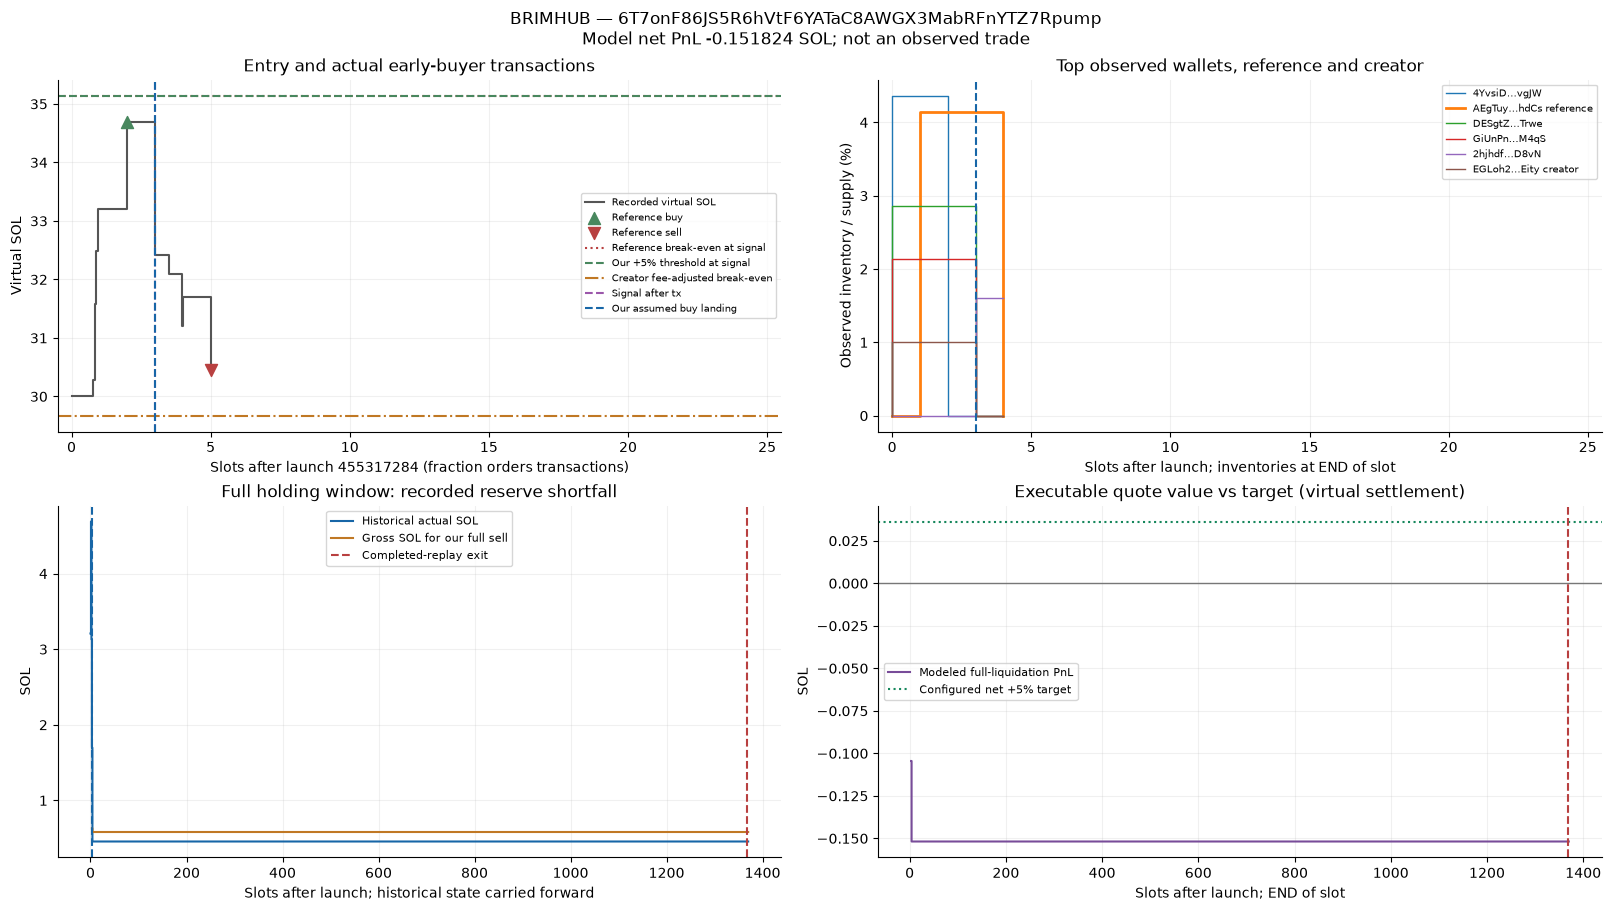

[BRIMHUB](https://gmgn.ai/sol/token/6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump): signal slot **455317286**, tx **460**; buy slot **455317287**. Sells before landing: **0**. Entry window still passes at landing: **True**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
85768,455317284,1955572844083544079,1791648813,ENTRY_CANDIDATE,NO_SIGNAL,4YvsiDz6xDhuwhKbwcjt5CeoDzpZUBSi4Uqx1VBTvgJW,43649120813451,1312943750,0
85770,455317284,1955572844083544080,1791648813,ENTRY_CANDIDATE,NO_SIGNAL,4YvsiDz6xDhuwhKbwcjt5CeoDzpZUBSi4Uqx1VBTvgJW,43649120813451,1312943750,0
85772,455317284,1955572844083544081,1791648813,ENTRY_CANDIDATE,NO_SIGNAL,4YvsiDz6xDhuwhKbwcjt5CeoDzpZUBSi4Uqx1VBTvgJW,43649120813451,1312943750,0
85774,455317285,1955572848378511469,1791648813,ENTRY_CANDIDATE,NO_SIGNAL,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,41397694869669,1500455000,0
85775,455317285,1955572848378511469,1791648813,ENTRY_CANDIDATE,NO_SIGNAL,4YvsiDz6xDhuwhKbwcjt5CeoDzpZUBSi4Uqx1VBTvgJW,43649120813451,1312943750,0
85777,455317286,1955572852673479117,1791648813,ENTRY_CANDIDATE,NO_SIGNAL,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,41397694869669,1500455000,726503853
85778,455317286,1955572852673479117,1791648813,ENTRY_SIGNAL,PENDING_BUY,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,41397694869669,1500455000,726503814
85779,455317286,1955572852673479117,1791648813,ORDER_ACCEPTED,PENDING_BUY,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,41397694869669,1500455000,
85780,455317287,1955572856968445952,1791648813,ORDER_FILLED,PENDING_BUY,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,41397694869669,1500455000,
87146,455318651,1955578715303837696,1791649113,ORDER_ACCEPTED,OPEN,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,0,289412586,


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
0,455317284,13,EGLoh2fjcQ11YuruYAdxJHLYjE3VAAmPMuxeKz2QEity,buy,10000000000000,10000000000000,NaN,NaN
4,455317285,108,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,buy,41397694869669,41397694869669,NaN,NaN
7,455317287,176,EGLoh2fjcQ11YuruYAdxJHLYjE3VAAmPMuxeKz2QEity,sell,10000000000000,0,32083356.0,52969206.0
10,455317288,217,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,sell,41397694869669,0,-289412586.0,-289412586.0


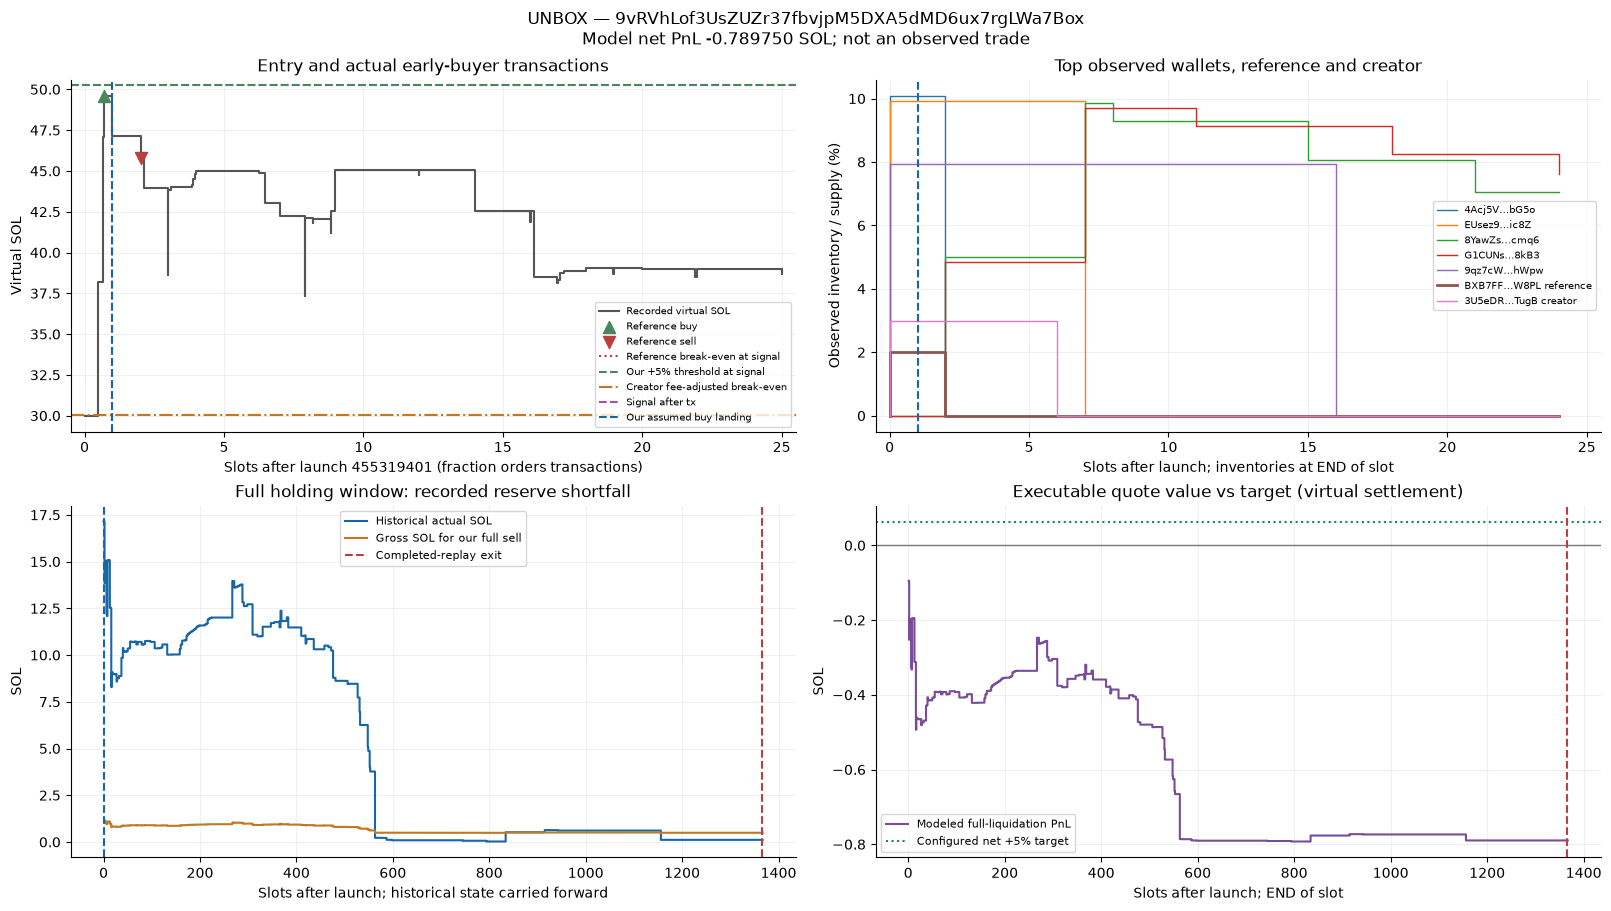

[UNBOX](https://gmgn.ai/sol/token/9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box): signal slot **455319401**, tx **339**; buy slot **455319402**. Sells before landing: **0**. Entry window still passes at landing: **True**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
87149,455319401,1955581936529309856,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,4Acj5VDoTzYcz5jNZxoWc7VZZrLSG2Hcna9MDENbbG5o,100914280281229,3347727334,0
87151,455319401,1955581936529309857,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,EUsez9vj6GM1mVhSFNkfb5HLD684TwuSCH5rABFPic8Z,99085719718762,4066446477,0
87152,455319401,1955581936529309857,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,4Acj5VDoTzYcz5jNZxoWc7VZZrLSG2Hcna9MDENbbG5o,100914280281229,3347727334,0
87154,455319401,1955581936529309917,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,113249708633255,6068200736,0
87155,455319401,1955581936529309917,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,EUsez9vj6GM1mVhSFNkfb5HLD684TwuSCH5rABFPic8Z,99085719718762,4066446477,0
87156,455319401,1955581936529309917,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,4Acj5VDoTzYcz5jNZxoWc7VZZrLSG2Hcna9MDENbbG5o,100914280281229,3347727334,0
87158,455319401,1955581936529309921,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,9qz7cWBqYBP2TnGfzMmxX64G4PQip7HtogjPBBnMhWpw,113249708633255,6068200736,0
87159,455319401,1955581936529309921,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,EUsez9vj6GM1mVhSFNkfb5HLD684TwuSCH5rABFPic8Z,99085719718762,4066446477,0
87160,455319401,1955581936529309921,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,4Acj5VDoTzYcz5jNZxoWc7VZZrLSG2Hcna9MDENbbG5o,100914280281229,3347727334,0
87161,455319401,1955581936529309921,1791649278,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,45932483661316,3099005000,0


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
38,455319401,158,3U5eDRNnCzQJoaSdkwARhaUSSr547FUpZFR9QkHvTugB,buy,30000000000000,30000000000000,NaN,NaN
44,455319401,242,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,buy,19971290352667,19971290352667,NaN,NaN
47,455319403,25,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,sell,19971290352667,0,-177572316.0,-1.775723e+08
58,455319407,281,3U5eDRNnCzQJoaSdkwARhaUSSr547FUpZFR9QkHvTugB,sell,30000000000000,0,903609453.0,1.014980e+09
141,455319517,227,3U5eDRNnCzQJoaSdkwARhaUSSr547FUpZFR9QkHvTugB,buy,195127275350,195127275350,NaN,NaN
156,455319588,930,3U5eDRNnCzQJoaSdkwARhaUSSr547FUpZFR9QkHvTugB,buy,186078929846,381206205196,NaN,NaN
176,455319673,573,3U5eDRNnCzQJoaSdkwARhaUSSr547FUpZFR9QkHvTugB,buy,167132038896,548338244092,NaN,NaN
216,455319909,672,3U5eDRNnCzQJoaSdkwARhaUSSr547FUpZFR9QkHvTugB,buy,214971653803,763309897895,NaN,NaN
254,455320343,338,3U5eDRNnCzQJoaSdkwARhaUSSr547FUpZFR9QkHvTugB,sell,763309897895,0,883867257.0,1.218156e+09


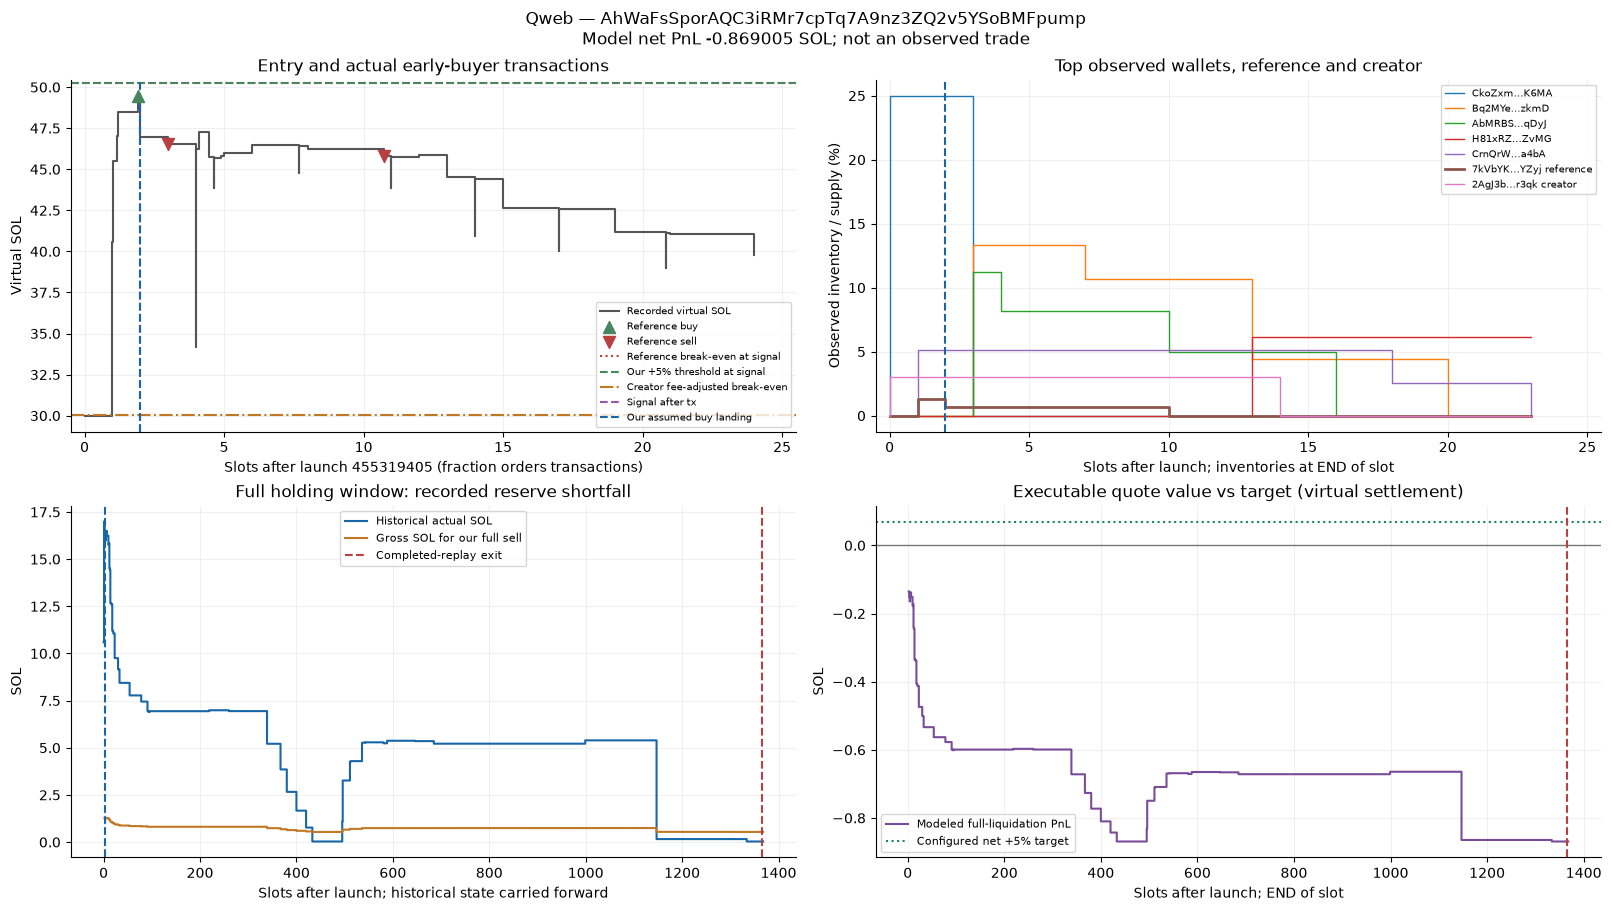

[Qweb](https://gmgn.ai/sol/token/AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump): signal slot **455319406**, tx **177**; buy slot **455319407**. Sells before landing: **0**. Entry window still passes at landing: **True**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
87205,455319405,1955581953709179696,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,CkoZxmALuShy6MAL3F9JRuDdkCyYSiV3PCNgiRzFK6MA,249999999999997,9851535519,0
87208,455319406,1955581958004146182,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,CkoZxmALuShy6MAL3F9JRuDdkCyYSiV3PCNgiRzFK6MA,249999999999997,9851535519,0
87209,455319406,1955581958004146182,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,CrnQrWkTButNe1TwBnNz4AT7gAfZYPW9nRw8DXoAa4bA,86008500305799,5011005000,0
87211,455319406,1955581958004146208,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,CkoZxmALuShy6MAL3F9JRuDdkCyYSiV3PCNgiRzFK6MA,249999999999997,9851535519,0
87212,455319406,1955581958004146208,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,CrnQrWkTButNe1TwBnNz4AT7gAfZYPW9nRw8DXoAa4bA,86008500305799,5011005000,0
87213,455319406,1955581958004146208,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,22279099595138,1531705000,0
87215,455319406,1955581958004146209,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,CkoZxmALuShy6MAL3F9JRuDdkCyYSiV3PCNgiRzFK6MA,249999999999997,9851535519,0
87216,455319406,1955581958004146209,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,CrnQrWkTButNe1TwBnNz4AT7gAfZYPW9nRw8DXoAa4bA,86008500305799,5011005000,0
87217,455319406,1955581958004146209,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,22279099595138,1531705000,0
87218,455319406,1955581958004146209,1791649279,ENTRY_CANDIDATE,NO_SIGNAL,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,20917853771130,1500455000,0


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
258,455319405,814,2AgJ3bj8BrhnpuATudrn3hocEewkyMCe2B2J5Xffr3qk,buy,30000000000000,30000000000000,NaN,NaN
263,455319406,165,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,buy,13249367105227,13249367105227,NaN,NaN
265,455319407,605,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,sell,6624683552613,6624683552614,NaN,-1.243832e+08
281,455319415,468,7kVbYKRgN32nLg7d1XyX6AnxRP9CpstFNyKJUGtcYZyj,sell,6624683552614,0,-130284380.0,-1.302844e+08
288,455319419,205,2AgJ3bj8BrhnpuATudrn3hocEewkyMCe2B2J5Xffr3qk,sell,30000000000000,0,870714557.0,1.081420e+09


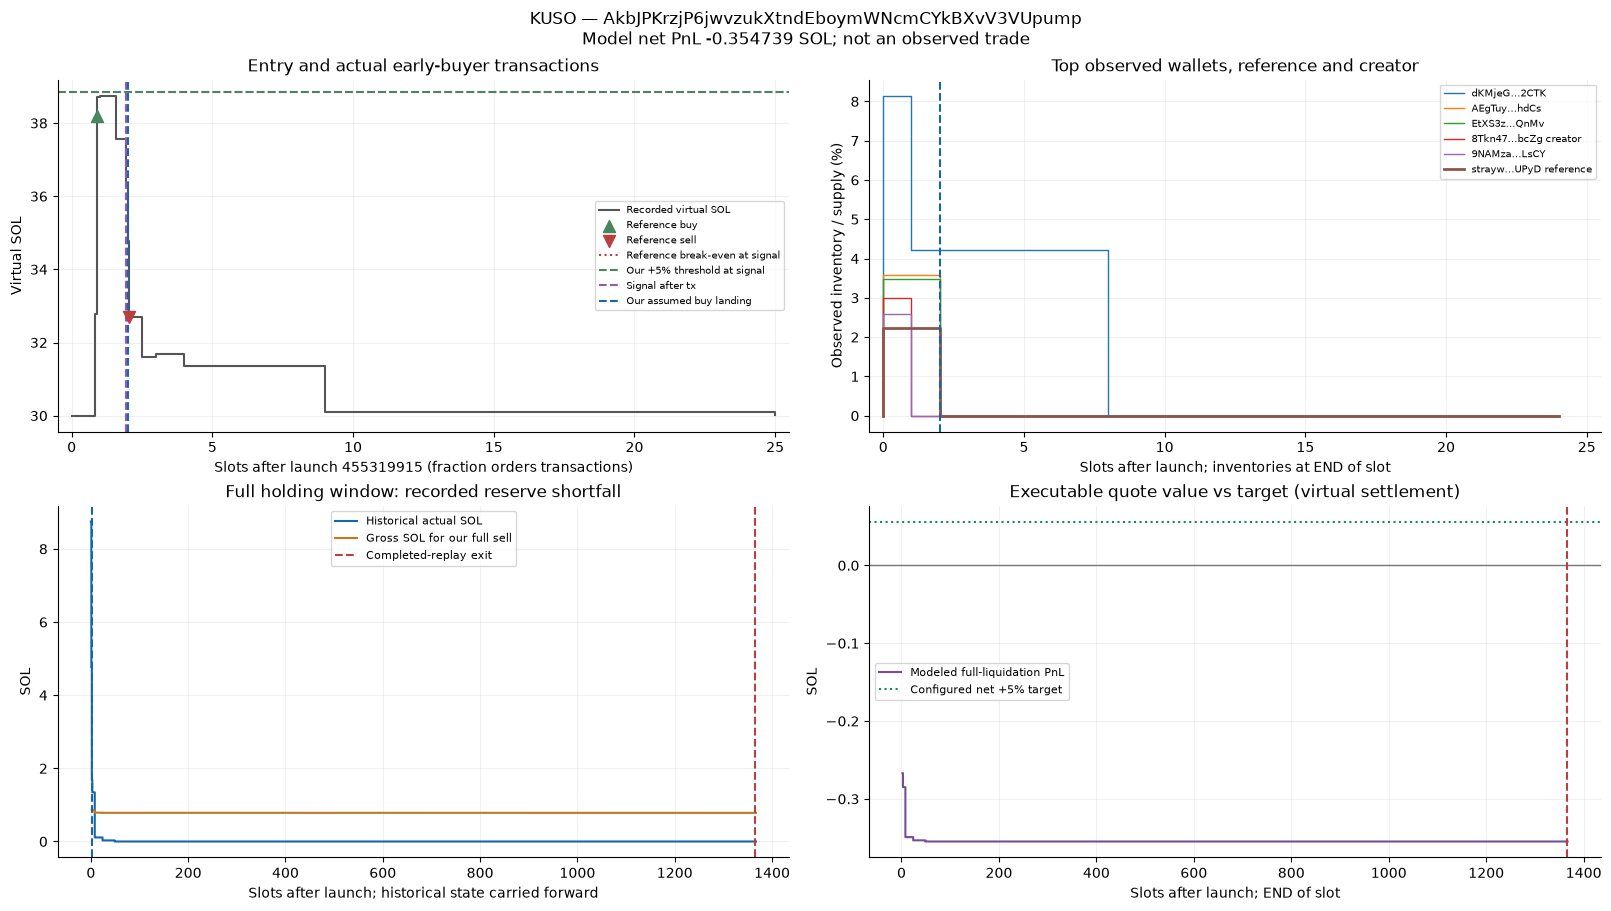

[KUSO](https://gmgn.ai/sol/token/AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump): signal slot **455319916**, tx **953**; buy slot **455319917**. Sells before landing: **1**. Entry window still passes at landing: **True**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
88463,455319915,1955584144142500552,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,EtXS3zbz67VqWVptE8FFETAw4f99AiEnf4Bdxh8SQnMv,34730735340997,1076423750,0
88465,455319915,1955584144142500553,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,EtXS3zbz67VqWVptE8FFETAw4f99AiEnf4Bdxh8SQnMv,34730735340997,1076423750,0
88467,455319915,1955584144142500606,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,81464884093072,3000005000,0
88468,455319915,1955584144142500606,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,EtXS3zbz67VqWVptE8FFETAw4f99AiEnf4Bdxh8SQnMv,34730735340997,1076423750,0
88470,455319915,1955584144142500616,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,81464884093072,3000005000,0
88471,455319915,1955584144142500616,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,35867496809101,1500455000,0
88472,455319915,1955584144142500616,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,EtXS3zbz67VqWVptE8FFETAw4f99AiEnf4Bdxh8SQnMv,34730735340997,1076423750,0
88474,455319915,1955584144142500618,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,81464884093072,3000005000,0
88475,455319915,1955584144142500618,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,35867496809101,1500455000,0
88476,455319915,1955584144142500618,1791649390,ENTRY_CANDIDATE,NO_SIGNAL,EtXS3zbz67VqWVptE8FFETAw4f99AiEnf4Bdxh8SQnMv,34730735340997,1076423750,0


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
346,455319915,710,8Tkn47KhnHxZcbfKEUCKDC4N7kx8RAz6Q1WygZiUbcZg,buy,30000000000000,30000000000000,NaN,NaN
351,455319915,777,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,buy,22366060260386,22366060260386,NaN,NaN
355,455319916,953,8Tkn47KhnHxZcbfKEUCKDC4N7kx8RAz6Q1WygZiUbcZg,sell,30000000000000,0,379480029.0,409239347.0
358,455319917,16,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,sell,22366060260386,0,-257541557.0,-257541557.0


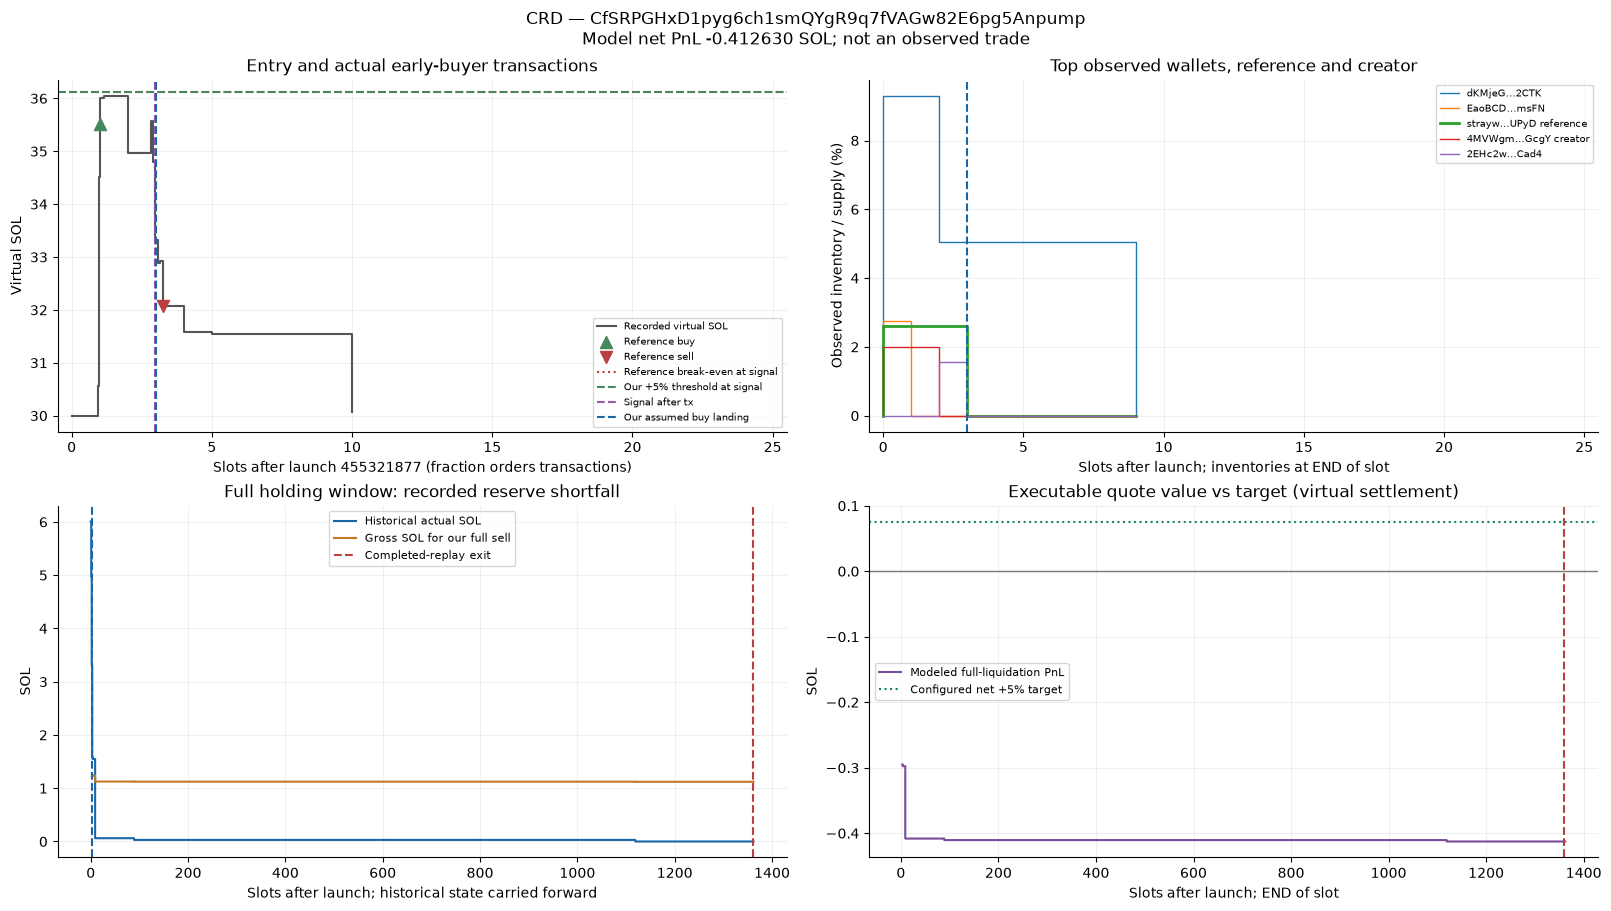

[CRD](https://gmgn.ai/sol/token/CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump): signal slot **455321879**, tx **798**; buy slot **455321880**. Sells before landing: **0**. Entry window still passes at landing: **False**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
91659,455321877,1955592570868335540,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,93043330444526,3000005000,0
91661,455321877,1955592570868335543,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,93043330444526,3000005000,0
91662,455321877,1955592570868335543,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,EaoBCDSwUfzyqthe55Qne8StLxS64TwSq7m5wD2umsFN,27465060093757,1005005000,0
91664,455321877,1955592570868335546,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,93043330444526,3000005000,0
91665,455321877,1955592570868335546,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,25937182989852,1008505001,0
91666,455321877,1955592570868335546,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,EaoBCDSwUfzyqthe55Qne8StLxS64TwSq7m5wD2umsFN,27465060093757,1005005000,0
91668,455321877,1955592570868335551,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,93043330444526,3000005000,0
91669,455321877,1955592570868335551,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,25937182989852,1008505001,0
91670,455321877,1955592570868335551,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,EaoBCDSwUfzyqthe55Qne8StLxS64TwSq7m5wD2umsFN,27465060093757,1005005000,0
91672,455321878,1955592575163302031,1791649819,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,93043330444526,3000005000,0


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
365,455321877,902,4MVWgmXA6HhYawHMyEeKMU8BqkFHnw1zrGfYU4dSGcgY,buy,20000000000000,20000000000000,NaN,NaN
368,455321877,953,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,buy,25937182989852,25937182989852,NaN,NaN
373,455321879,735,4MVWgmXA6HhYawHMyEeKMU8BqkFHnw1zrGfYU4dSGcgY,sell,20000000000000,0,181155579.0,204335802.0
378,455321880,264,straywAWvrXhKJKCLiVwaPvTuqd419c2i4Ry9cvUPyD,sell,25937182989852,0,-168253903.0,-168253903.0


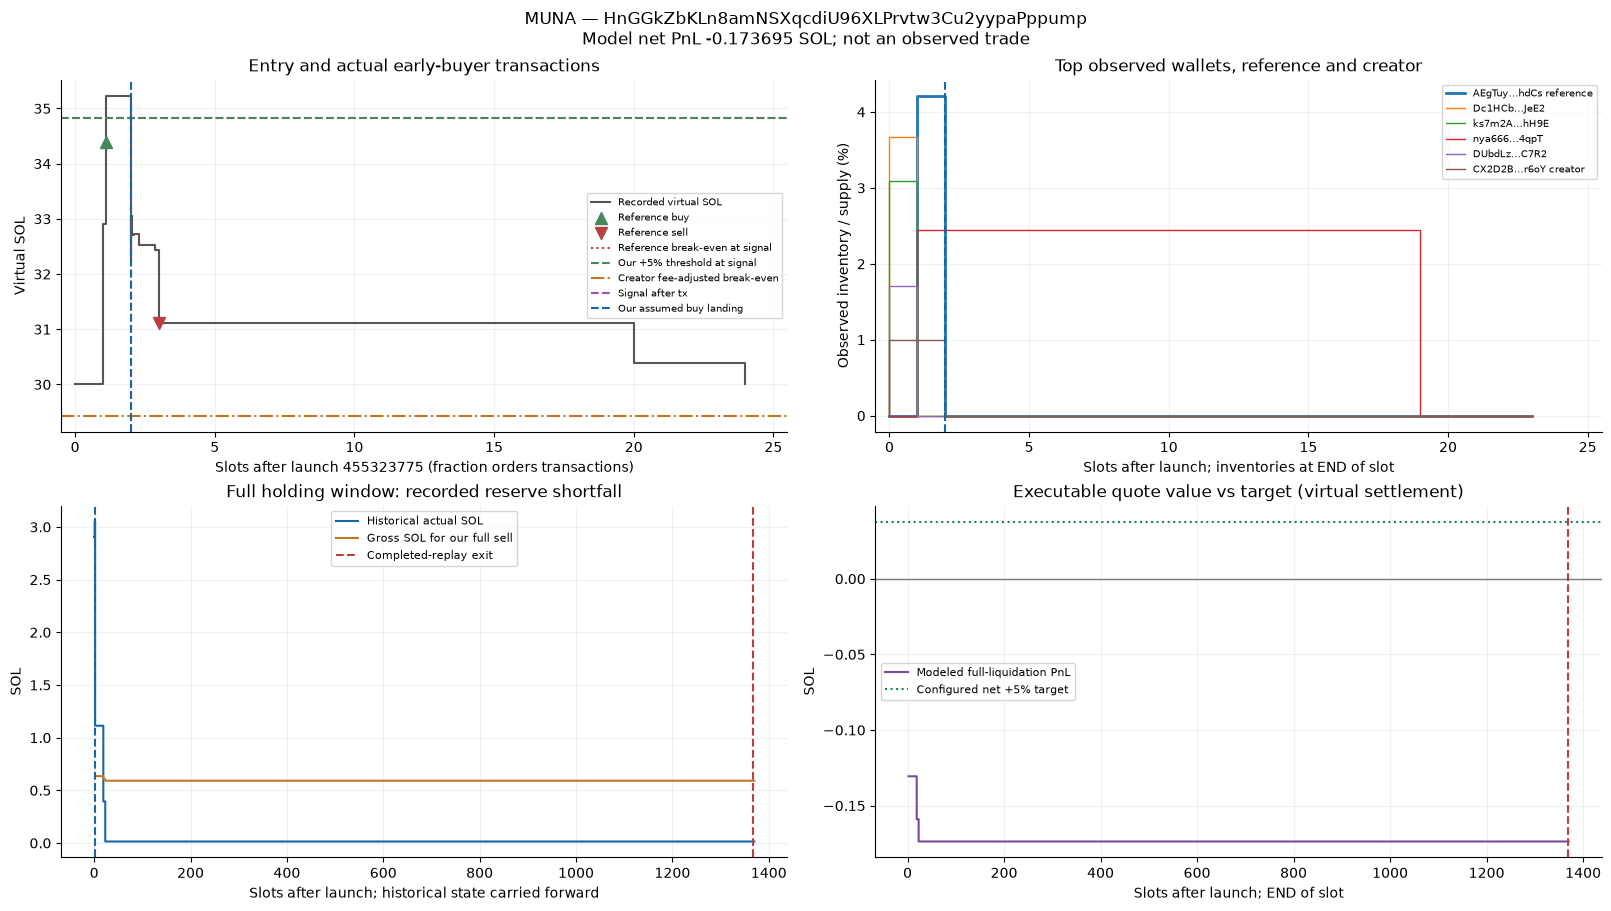

[MUNA](https://gmgn.ai/sol/token/HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump): signal slot **455323776**, tx **1132**; buy slot **455323777**. Sells before landing: **1**. Entry window still passes at landing: **False**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
93073,455323775,1955600722716263378,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,Dc1HCbbFAhViEhrkHqm5k67rJShicSedz5pjyDF4JeE2,36739990383007,1097686250,0
93075,455323775,1955600722716263379,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,Dc1HCbbFAhViEhrkHqm5k67rJShicSedz5pjyDF4JeE2,36739990383007,1097686250,0
93077,455323775,1955600722716263380,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,Dc1HCbbFAhViEhrkHqm5k67rJShicSedz5pjyDF4JeE2,36739990383007,1097686250,0
93079,455323776,1955600727011229817,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,42147788944843,1500455000,0
93080,455323776,1955600727011229817,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,Dc1HCbbFAhViEhrkHqm5k67rJShicSedz5pjyDF4JeE2,36739990383007,1097686250,0
93082,455323776,1955600727011229819,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,42147788944843,1500455000,0
93083,455323776,1955600727011229819,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,Dc1HCbbFAhViEhrkHqm5k67rJShicSedz5pjyDF4JeE2,36739990383007,1097686250,0
93085,455323776,1955600727011229823,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,42147788944843,1500455000,0
93086,455323776,1955600727011229823,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,Dc1HCbbFAhViEhrkHqm5k67rJShicSedz5pjyDF4JeE2,36739990383007,1097686250,0
93088,455323776,1955600727011229832,1791650236,ENTRY_CANDIDATE,NO_SIGNAL,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,42147788944843,1500455000,0


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
384,455323775,976,CX2D2BDzRW7niVJMJYJ2H7PBKgTbkTmNQyjwt1x7r6oY,buy,10000000000000,10000000000000,NaN,NaN
388,455323776,120,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,buy,42147788944843,42147788944843,NaN,NaN
396,455323777,32,CX2D2BDzRW7niVJMJYJ2H7PBKgTbkTmNQyjwt1x7r6oY,sell,10000000000000,0,44508965.0,71603105.0
400,455323777,945,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,sell,42147788944843,0,-210649740.0,-210649740.0


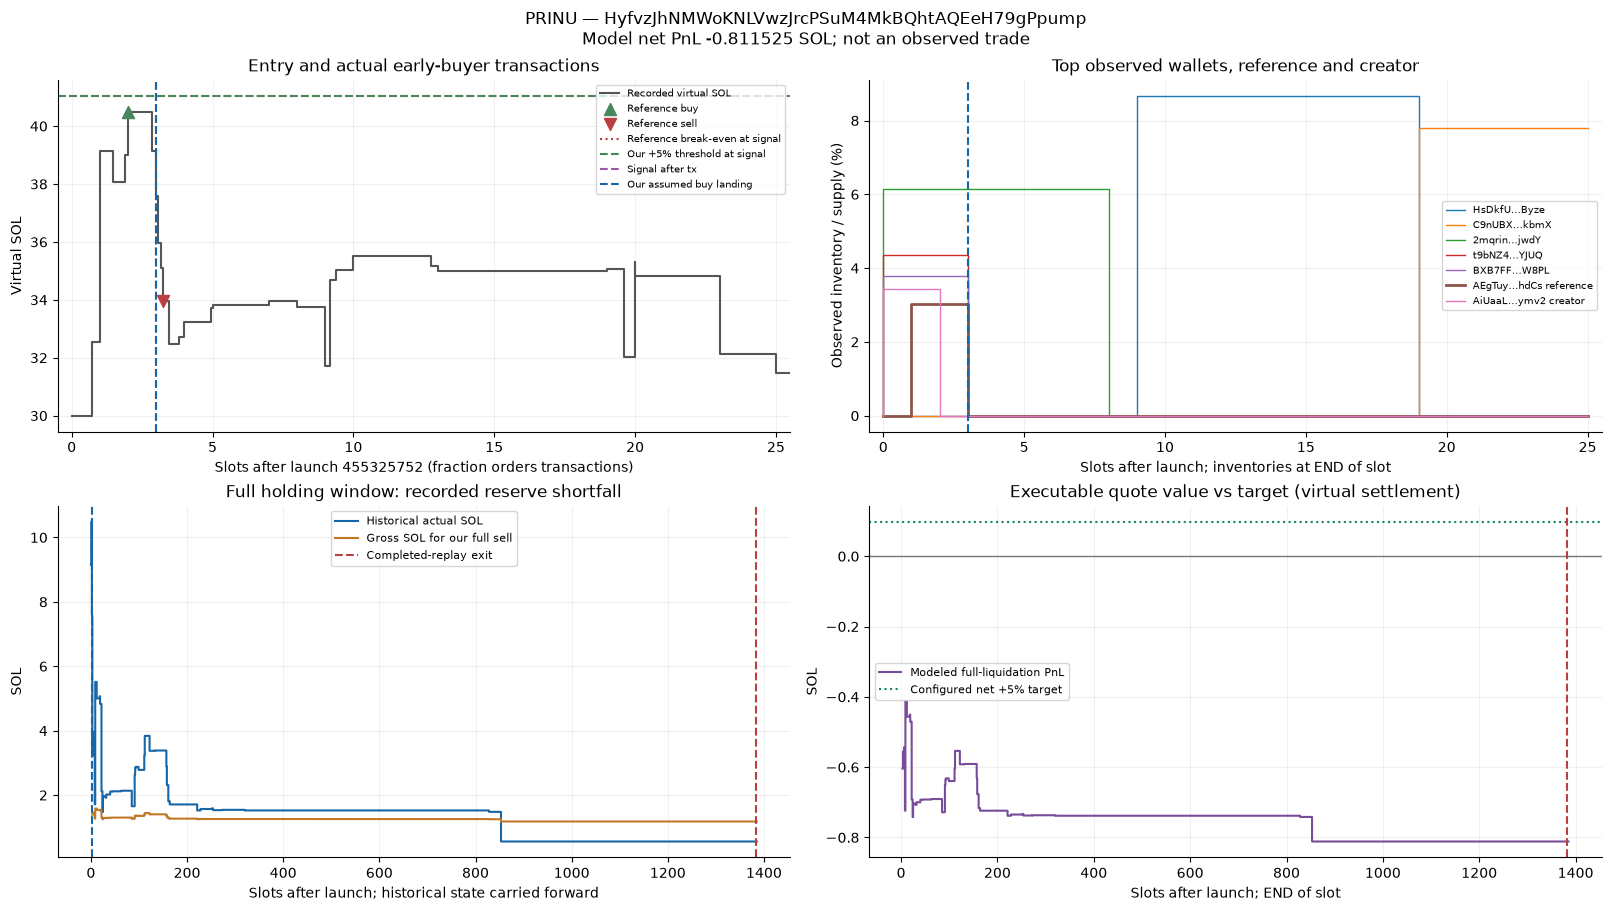

[PRINU](https://gmgn.ai/sol/token/HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump): signal slot **455325754**, tx **955**; buy slot **455325755**. Sells before landing: **0**. Entry window still passes at landing: **True**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
94473,455325752,1955609213866607294,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,AiUaaLhisTUx9gsthvyfD9P6aMJ8FEhxXEUMs1CUymv2,34344863190501,1001616002,0
94475,455325752,1955609213866607295,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,AiUaaLhisTUx9gsthvyfD9P6aMJ8FEhxXEUMs1CUymv2,34344863190501,999558520,0
94477,455325752,1955609213866607296,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,AiUaaLhisTUx9gsthvyfD9P6aMJ8FEhxXEUMs1CUymv2,34344863190501,996913186,0
94479,455325752,1955609213866607543,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,2mqrindMAjJEQPLhroYWyiYPo5h9iAsahfdd4QtsjwdY,61321818380227,2230005000,0
94480,455325752,1955609213866607543,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,AiUaaLhisTUx9gsthvyfD9P6aMJ8FEhxXEUMs1CUymv2,34344863190501,990453926,0
94482,455325752,1955609213866607544,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,2mqrindMAjJEQPLhroYWyiYPo5h9iAsahfdd4QtsjwdY,61321818380227,2230005000,0
94483,455325752,1955609213866607544,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,37956858462824,1500480000,0
94484,455325752,1955609213866607544,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,AiUaaLhisTUx9gsthvyfD9P6aMJ8FEhxXEUMs1CUymv2,34344863190501,986009481,0
94486,455325752,1955609213866607548,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,2mqrindMAjJEQPLhroYWyiYPo5h9iAsahfdd4QtsjwdY,61321818380227,2230005000,0
94487,455325752,1955609213866607548,1791650669,ENTRY_CANDIDATE,NO_SIGNAL,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,37956858462824,1500480000,0


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
403,455325752,701,AiUaaLhisTUx9gsthvyfD9P6aMJ8FEhxXEUMs1CUymv2,buy,34344863190501,34344863190501,NaN,NaN
412,455325753,1083,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,buy,30185995246216,30185995246216,NaN,NaN
414,455325754,955,AiUaaLhisTUx9gsthvyfD9P6aMJ8FEhxXEUMs1CUymv2,sell,34344863190501,0,544116291.0,586228686.0
417,455325755,200,AEgTuy8Lg4wfnjm285mk3P2k1p39ofqNXk8b5VtYhdCs,sell,30185995246216,0,-413507950.0,-413507950.0


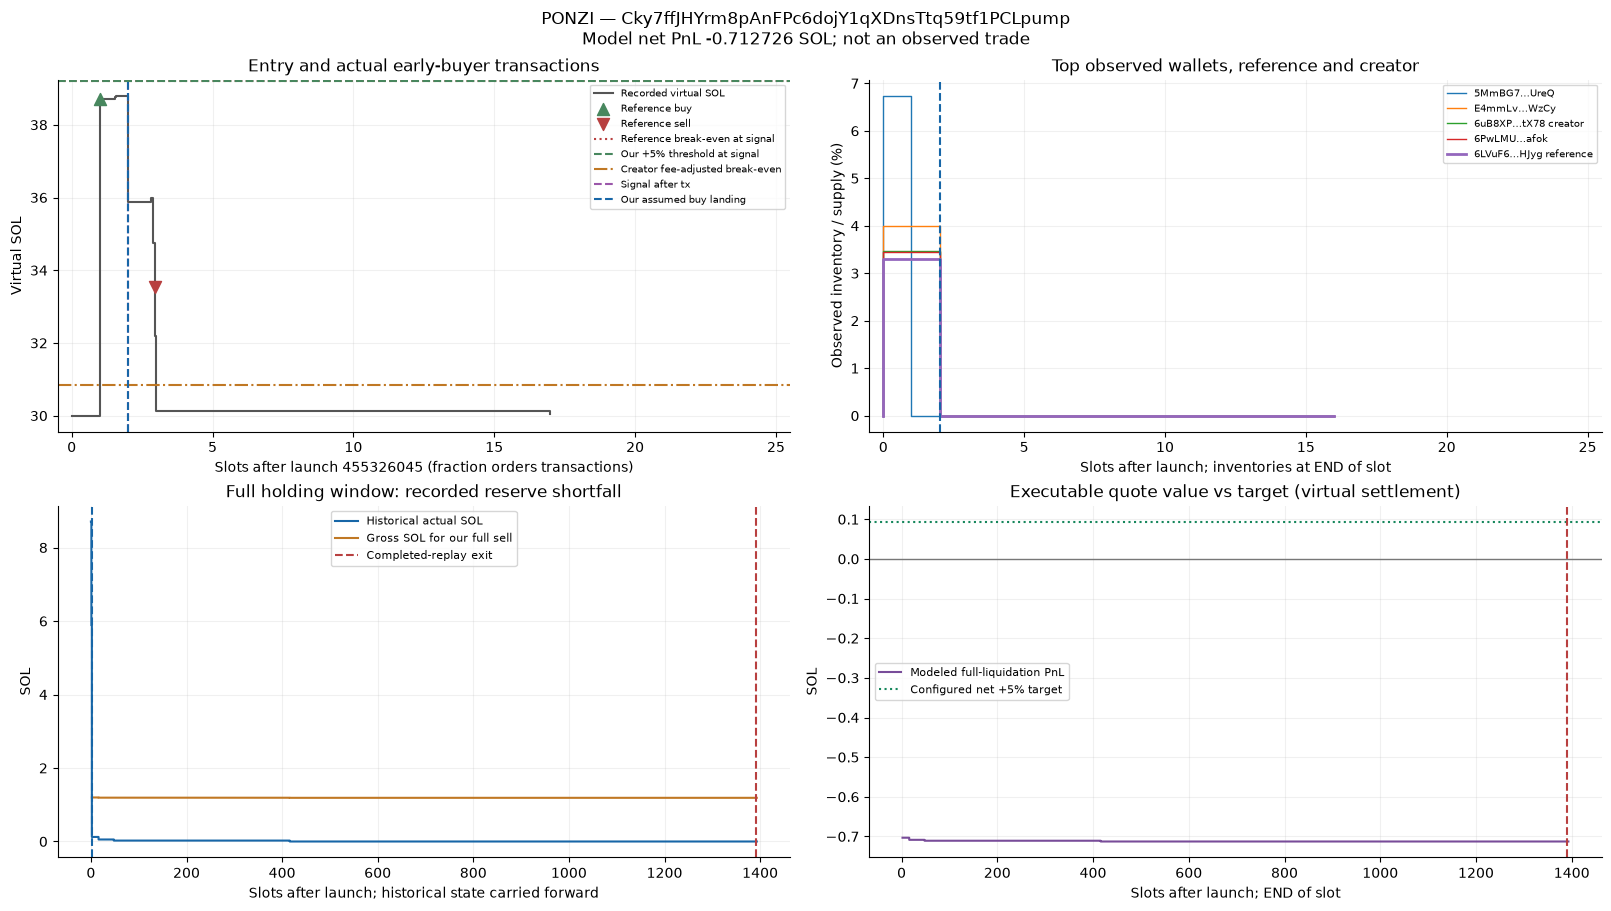

[PONZI](https://gmgn.ai/sol/token/Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump): signal slot **455326046**, tx **429**; buy slot **455326047**. Sells before landing: **0**. Entry window still passes at landing: **True**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
94865,455326045,1955610472292025279,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,6uB8XPXRzsDTGFDUGm3xqUrQi2L6PpRaZTYppXHNtX78,34612903225806,1009610000,0
94867,455326045,1955610472292025280,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,E4mmLv7MugAQoJvqbzVSRTzn6LRWtsAQgX5dYze7WzCy,39937965260545,1255610000,0
94868,455326045,1955610472292025280,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,6PwLMU3aTi2SGjnP5iRkxAW4VBgEdjwYdC8D7Sv3afok,34388035377079,1164375000,0
94869,455326045,1955610472292025280,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,6uB8XPXRzsDTGFDUGm3xqUrQi2L6PpRaZTYppXHNtX78,34612903225806,1002440000,0
94871,455326045,1955610472292025281,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,5MmBG7LnNDdnWwMFCCZLnPxtNEZoz3uRbrADFVdwUreQ,67403714520969,2541485000,0
94872,455326045,1955610472292025281,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,2ni5TVzyzEvKmrKY4bQqE1F2nStEdwpjvMsiyMh5APa1,32032079439934,1346625000,0
94873,455326045,1955610472292025281,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,E4mmLv7MugAQoJvqbzVSRTzn6LRWtsAQgX5dYze7WzCy,39937965260545,1255610000,0
94874,455326045,1955610472292025281,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,6PwLMU3aTi2SGjnP5iRkxAW4VBgEdjwYdC8D7Sv3afok,34388035377079,1164375000,0
94875,455326045,1955610472292025281,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,6uB8XPXRzsDTGFDUGm3xqUrQi2L6PpRaZTYppXHNtX78,34612903225806,990920000,0
94877,455326045,1955610472292025282,1791650734,ENTRY_CANDIDATE,NO_SIGNAL,5MmBG7LnNDdnWwMFCCZLnPxtNEZoz3uRbrADFVdwUreQ,67403714520969,2541485000,0


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
473,455326045,958,6uB8XPXRzsDTGFDUGm3xqUrQi2L6PpRaZTYppXHNtX78,buy,34612903225806,34612903225806,NaN,NaN
478,455326045,961,6LVuF6wjpLVeqdJq36bD6hYG2aQuVUSfTXWRdJDBHJyg,buy,33057231909583,33057231909583,NaN,NaN
484,455326047,779,6LVuF6wjpLVeqdJq36bD6hYG2aQuVUSfTXWRdJDBHJyg,sell,33057231909583,0,-316958524.0,-316958524.0
486,455326047,808,6uB8XPXRzsDTGFDUGm3xqUrQi2L6PpRaZTYppXHNtX78,sell,34612903225806,0,51607664.0,98396785.0


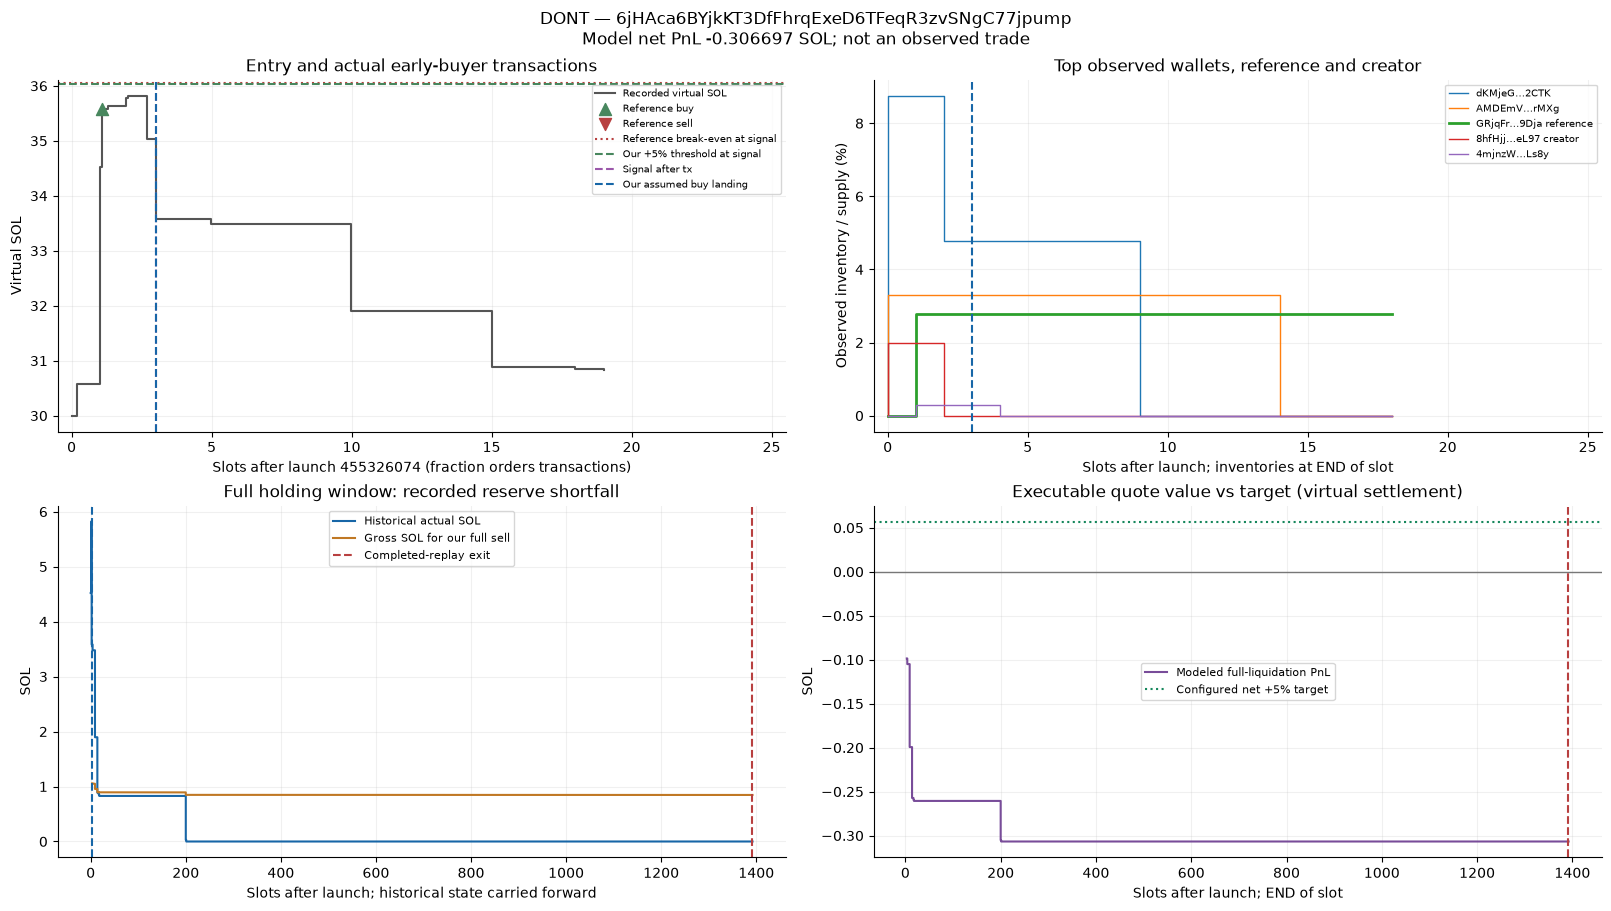

[DONT](https://gmgn.ai/sol/token/6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump): signal slot **455326076**, tx **299**; buy slot **455326077**. Sells before landing: **0**. Entry window still passes at landing: **True**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
94967,455326074,1955610596846076710,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,32955762800425,1001580000,0
94969,455326074,1955610596846076712,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,87552627736117,3000005087,0
94970,455326074,1955610596846076712,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,32955762800425,1001580000,0
94974,455326075,1955610601141043254,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,87552627736117,3000005087,0
94975,455326075,1955610601141043254,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,GRjqFrRcc5p5UU4KfB7EjHjLD2iBB67MFmcK5CHQ9Dja,27847242060718,1076241384,0
94976,455326075,1955610601141043254,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,32955762800425,1001580000,0
94978,455326075,1955610601141043426,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,87552627736117,3000005087,0
94979,455326075,1955610601141043426,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,GRjqFrRcc5p5UU4KfB7EjHjLD2iBB67MFmcK5CHQ9Dja,27847242060718,1076241384,0
94980,455326075,1955610601141043426,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,AMDEmVocLtN5ji2gBY7BrmSHEyM5vt6TGszBbg4crMXg,32955762800425,1001580000,0
94982,455326075,1955610601141043942,1791650741,ENTRY_CANDIDATE,NO_SIGNAL,dKMjeGJ4Mk9S3hxdfTThvZ7exks2xMwWqSM5NvN2CTK,87552627736117,3000005087,0


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
491,455326074,155,8hfHjjsqdDHoR9wotDuobnohgrozjZJRBpP4BiEieL97,buy,20000000000000,20000000000000,NaN,NaN
494,455326075,53,GRjqFrRcc5p5UU4KfB7EjHjLD2iBB67MFmcK5CHQ9Dja,buy,27847242060718,27847242060718,NaN,NaN
499,455326076,203,8hfHjjsqdDHoR9wotDuobnohgrozjZJRBpP4BiEieL97,sell,20000000000000,0,193089496.0,210552599.0
506,455326274,702,GRjqFrRcc5p5UU4KfB7EjHjLD2iBB67MFmcK5CHQ9Dja,sell,27847242060718,0,-285437160.0,-285437160.0


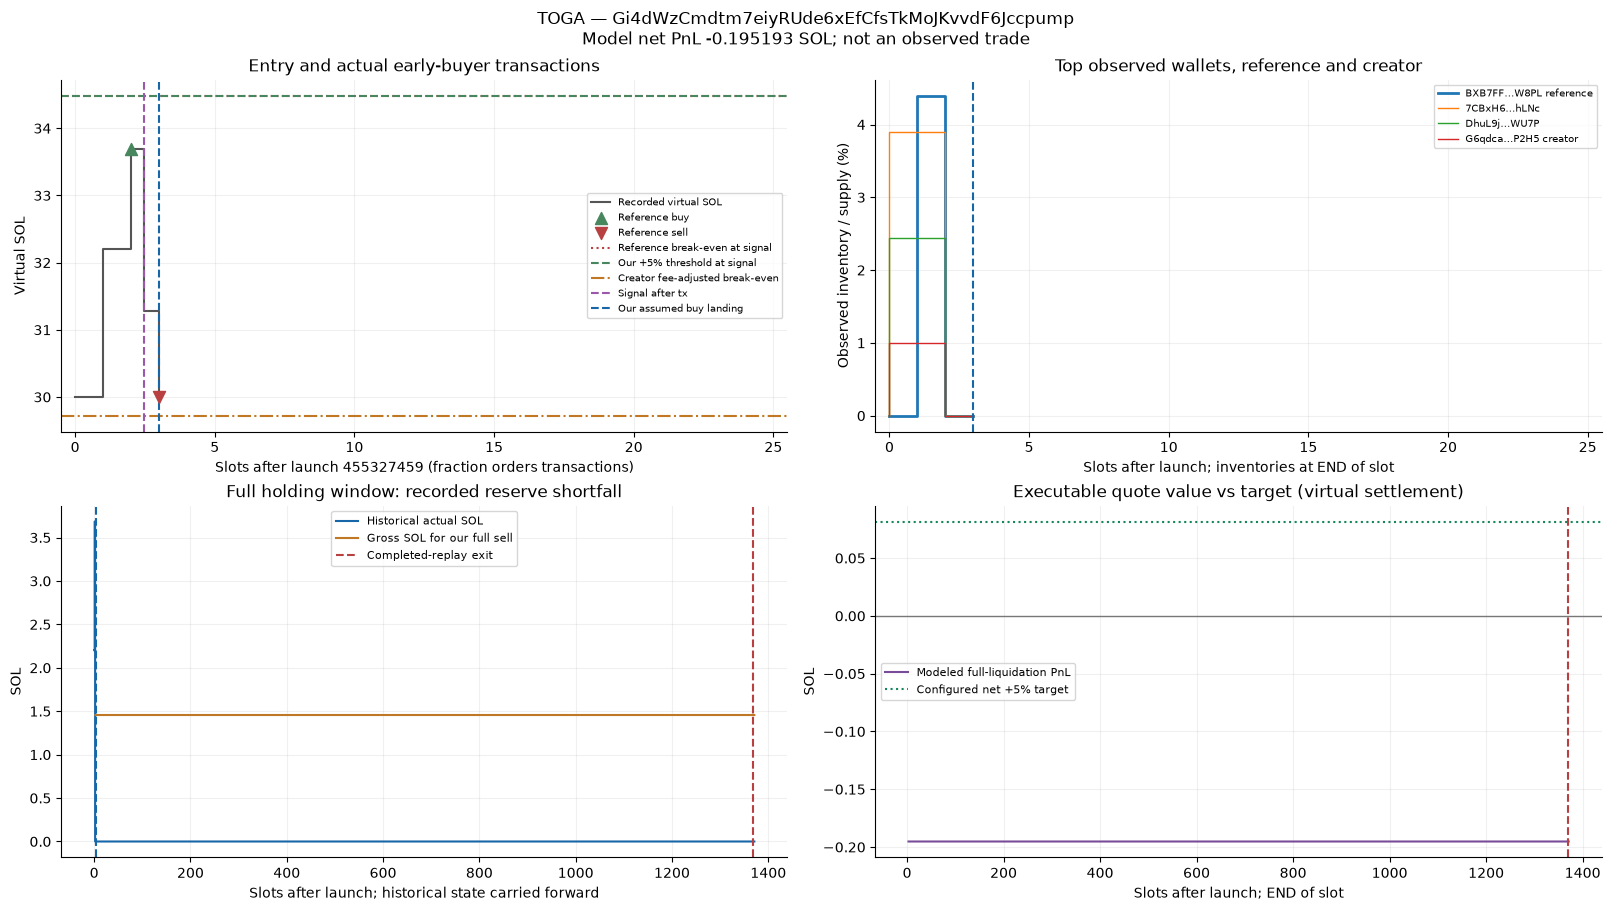

[TOGA](https://gmgn.ai/sol/token/Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump): signal slot **455327461**, tx **170**; buy slot **455327462**. Sells before landing: **2**. Entry window still passes at landing: **False**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
98821,455327459,1955616545375781898,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,7CBxH6uV3z7rLjQ8977VLzSJNMLQtZcmvbHv9PsfhLNc,39012158538716,1168156250,0
98823,455327459,1955616545375781899,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,7CBxH6uV3z7rLjQ8977VLzSJNMLQtZcmvbHv9PsfhLNc,39012158538716,1168156250,0
98826,455327460,1955616549670748361,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,43962785103449,1531705000,0
98827,455327460,1955616549670748361,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,7CBxH6uV3z7rLjQ8977VLzSJNMLQtZcmvbHv9PsfhLNc,39012158538716,1168156250,0
98830,455327461,1955616553965715619,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,43962785103449,1531705000,377323650
98831,455327461,1955616553965715619,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,7CBxH6uV3z7rLjQ8977VLzSJNMLQtZcmvbHv9PsfhLNc,39012158538716,1168156250,0
98833,455327461,1955616553965715627,1791651040,ENTRY_CANDIDATE,NO_SIGNAL,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,43962785103449,1531705000,1633186795
98834,455327461,1955616553965715627,1791651040,ENTRY_SIGNAL,PENDING_BUY,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,43962785103449,1531705000,1633186780
98835,455327461,1955616553965715627,1791651040,ORDER_ACCEPTED,PENDING_BUY,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,43962785103449,1531705000,
98839,455327462,1955616558260682752,1791651040,ORDER_FILLED,PENDING_BUY,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,0,266163347,


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
508,455327459,1032,G6qdcaPU7b73L2Hi5X8R5PhArEYoHySbdTaK2hpcP2H5,buy,10000000000000,10000000000000,NaN,NaN
511,455327460,200,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,buy,43962785103449,43962785103449,NaN,NaN
514,455327461,172,G6qdcaPU7b73L2Hi5X8R5PhArEYoHySbdTaK2hpcP2H5,sell,10000000000000,0,16476704.0,33818995.0
515,455327461,359,BXB7FF4m5x74ZoUvVHfPJnVBbqWHpMEU1WNUZAL9W8PL,sell,43962785103449,0,-266163347.0,-266163347.0


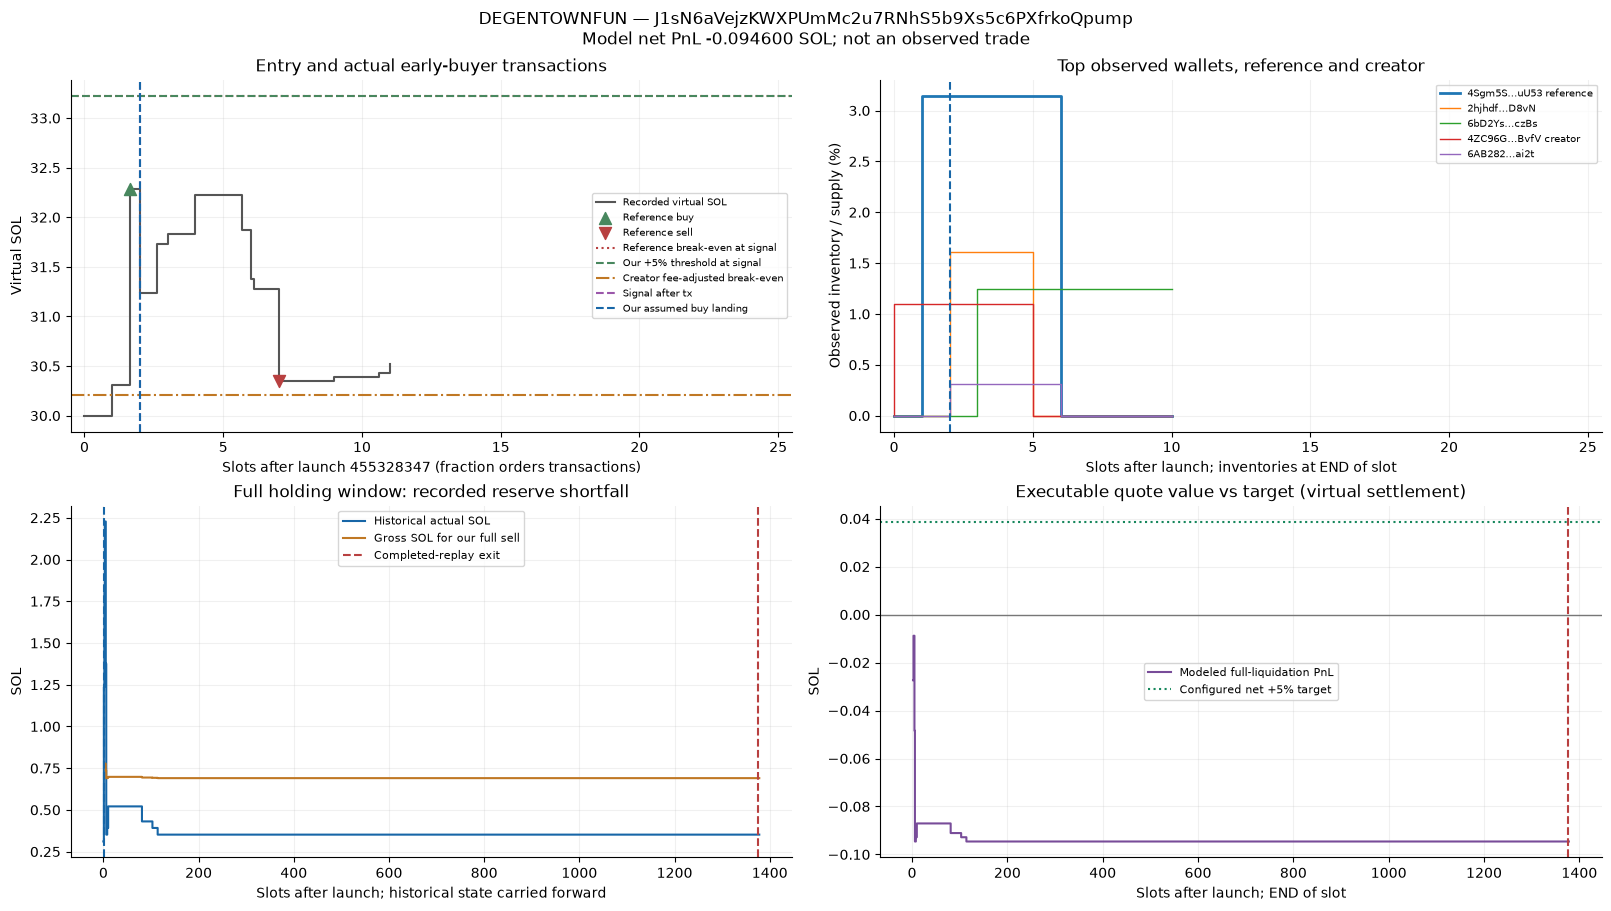

[DEGENTOWNFUN](https://gmgn.ai/sol/token/J1sN6aVejzKWXPUmMc2u7RNhS5b9Xs5c6PXfrkoQpump): signal slot **455328348**, tx **1011**; buy slot **455328349**. Sells before landing: **0**. Entry window still passes at landing: **True**. Reference full-position loss sale observed: **True**.

,slot,boundary_ordinal,time,action,status,wallet,wallet_tokens,wallet_adjusted_cost,budget_lamports
99732,455328348,1955620363601707647,1791651234,ENTRY_CANDIDATE,NO_SIGNAL,EaoBCDSwUfzyqthe55Qne8StLxS64TwSq7m5wD2umsFN,33512552165232,1005005000,0
99734,455328348,1955620363601707665,1791651234,ENTRY_CANDIDATE,NO_SIGNAL,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,31462203858512,1032005000,0
99735,455328348,1955620363601707665,1791651234,ENTRY_CANDIDATE,NO_SIGNAL,EaoBCDSwUfzyqthe55Qne8StLxS64TwSq7m5wD2umsFN,33512552165232,1005005000,0
99737,455328348,1955620363601708020,1791651234,ENTRY_CANDIDATE,NO_SIGNAL,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,31462203858512,1032005000,776072763
99738,455328348,1955620363601708020,1791651234,ENTRY_SIGNAL,PENDING_BUY,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,31462203858512,1032005000,776072720
99739,455328348,1955620363601708020,1791651234,ORDER_ACCEPTED,PENDING_BUY,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,31462203858512,1032005000,
99741,455328349,1955620367896674304,1791651234,ORDER_FILLED,PENDING_BUY,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,31462203858512,1032005000,
101601,455329722,1955626264886771712,1791651534,ORDER_ACCEPTED,OPEN,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,0,116172475,
101602,455329723,1955626269181739008,1791651534,ORDER_FILLED,OPEN,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,0,116172475,


,slot,tx_idx,wallet,side,tokens_raw,observed_tokens_after,closed_observed_cashflow_lamports,full_exit_pnl_at_pretrade_state_lamports
516,455328347,994,4ZC96Gebcxz27N8Pf6zi1tnHmNnqUMfw4jUaPFojBvfV,buy,11000000000000,11000000000000,NaN,NaN
518,455328348,656,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,buy,31462203858512,31462203858512,NaN,NaN
523,455328352,559,4ZC96Gebcxz27N8Pf6zi1tnHmNnqUMfw4jUaPFojBvfV,sell,11000000000000,0,31925067.0,44907597.0
526,455328353,416,4Sgm5SNaPw9hcRpDgSyyjjDiA2qgokCM6KgA9jBFuU53,sell,31462203858512,0,-116172475.0,-116172475.0


In [15]:
for mint in shortfall_mints:
    p = rows_by_run['virtual'][mint]
    launch = int(births[mint]['slot'])
    tape = trades_by_mint[mint]
    events = wallet_events[wallet_events['mint'] == mint]
    slots = slot_states[slot_states['mint'] == mint]
    buy = fill_by_run_mint['virtual'][mint]['BUY']
    signal_boundary = reservations['virtual'][buy['order_id']]
    max_tx = {s: max(r['tx_idx'] for r in tape if r['slot'] == s) + 2 for s in {r['slot'] for r in tape}}
    def tx_x(slot, index):
        return slot - launch + (index + 1) / max_tx[slot]
    signal_slot, signal_tx = signal_boundary >> 32, (signal_boundary & ((1 << 32)-1))-1
    signal_x = tx_x(signal_slot, signal_tx)
    early = [r for r in tape if r['slot'] <= launch + 25]
    fig, axes = plt.subplots(2, 2, figsize=(16, 9), layout='constrained')
    ax = axes[0, 0]
    ax.step([0]+[tx_x(r['slot'],r['tx_idx']) for r in early],
            [int(births[mint]['initial_virtual_quote_raw'])/LAMPORTS]+[int(r['virtual_quote'])/LAMPORTS for r in early], where='post', color='#555', label='Recorded virtual SOL')
    for side, marker, color in [('buy','^','#48875e'),('sell','v','#b84040')]:
        selected = [r for r in early if r['trader']==p['sniper_wallet'] and r['side']==side]
        ax.scatter([tx_x(r['slot'],r['tx_idx']) for r in selected], [int(r['virtual_quote'])/LAMPORTS for r in selected], marker=marker, color=color, s=75, label='Reference '+side, zorder=4)
    ax.axhline(float(p['signal_sniper_threshold'])/LAMPORTS, linestyle=':', color='#b84040', label='Reference break-even at signal')
    ax.axhline(float(p['signal_our_threshold'])/LAMPORTS, linestyle='--', color='#48875e', label='Our +5% threshold at signal')
    dev = holder_economics[(holder_economics['mint']==mint) & (holder_economics['checkpoint']=='signal_after_transaction') & holder_economics['is_launch_creator']]
    if len(dev) and pd.notna(dev.iloc[0]['wallet_break_even_virtual_SOL']):
        ax.axhline(dev.iloc[0]['wallet_break_even_virtual_SOL'],color='#c07824',linestyle='-.',label='Creator fee-adjusted break-even')
    ax.axvline(signal_x, color='#9b57aa', linestyle='--', label='Signal after tx')
    ax.axvline(p['entry_slot']-launch, color='#1766a7', linestyle='--', label='Our assumed buy landing')
    ax.set(xlabel=f'Slots after launch {launch} (fraction orders transactions)', ylabel='Virtual SOL', title='Entry and actual early-buyer transactions', xlim=(-.5,25.5))
    ax.legend(fontsize=7)
    ax = axes[0, 1]
    h = holder_slots[(holder_slots['mint']==mint) & (holder_slots['slot']<=launch+25)]
    top = h.groupby('wallet')['supply_pct'].max().sort_values(ascending=False).head(5).index.tolist()
    if p['sniper_wallet'] not in top:
        top.append(p['sniper_wallet'])
    if p['creator'] not in top and p['creator'] in h['wallet'].values:
        top.append(p['creator'])
    for wallet in top:
        w = h[h['wallet']==wallet].sort_values('slot')
        label = wallet[:6]+'…'+wallet[-4:] + (' reference' if wallet==p['sniper_wallet'] else '') + (' creator' if wallet==p['creator'] else '')
        ax.step([0]+(w['slot']-launch).tolist(), [0]+w['supply_pct'].tolist(), where='post', label=label, linewidth=2 if wallet==p['sniper_wallet'] else 1)
    ax.axvline(p['entry_slot']-launch, color='#1766a7', linestyle='--')
    ax.set(xlabel='Slots after launch; inventories at END of slot', ylabel='Observed inventory / supply (%)', title='Top observed wallets, reference and creator', xlim=(-.5,25.5))
    ax.legend(fontsize=7)
    ax = axes[1, 0]
    ax.step(slots['relative_slot'],slots['real_sol_lamports']/LAMPORTS, where='post', label='Historical actual SOL', color='#1766a7')
    ax.step(slots['relative_slot'],slots['hypothetical_full_sell_gross_lamports']/LAMPORTS, where='post', label='Gross SOL for our full sell', color='#c07824')
    ax.axvline(p['entry_slot']-launch,color='#1766a7',linestyle='--')
    ax.axvline(p['exit_slot']-launch,color='#b84040',linestyle='--',label='Completed-replay exit')
    ax.set(xlabel='Slots after launch; historical state carried forward', ylabel='SOL', title='Full holding window: recorded reserve shortfall')
    ax.legend(fontsize=8)
    ax = axes[1, 1]
    ax.step(slots['relative_slot'],slots['hypothetical_full_sell_pnl_lamports']/LAMPORTS, where='post', label='Modeled full-liquidation PnL', color='#784c99')
    ax.axhline(0,color='#777',linewidth=1)
    target = ((p['entry_cash_lamports']-2039280)*500+9999)//10000
    ax.axhline(target/LAMPORTS,color='#16875c',linestyle=':',label='Configured net +5% target')
    ax.axvline(p['exit_slot']-launch,color='#b84040',linestyle='--')
    ax.set(xlabel='Slots after launch; END of slot', ylabel='SOL', title='Executable quote value vs target (virtual settlement)')
    ax.legend(fontsize=8)
    for ax in axes.flat:
        ax.grid(alpha=.18)
    fig.suptitle(f"{p['symbol']} — {mint}\nModel net PnL {p['closed_pnl_lamports']/LAMPORTS:+.6f} SOL; not an observed trade", fontsize=12)
    fig.savefig(EXPORT/f'slot_trace_{mint}.png',dpi=150)
    plt.show()
    details = cases[cases['mint']==mint].iloc[0]
    display(Markdown(f"[{p['symbol']}]({p['gmgn_url']}): signal slot **{p['signal_slot']}**, tx **{int(details['signal_tx_idx'])}**; buy slot **{p['entry_slot']}**. Sells before landing: **{int(details['sells_between_signal_and_landing'])}**. Entry window still passes at landing: **{bool(details['entry_window_still_valid'])}**. Reference full-position loss sale observed: **{bool(details['anchor_full_loss_sale_observed'])}**."))
    relevant = strategy_trace[(strategy_trace['run']=='virtual') & (strategy_trace['mint']==mint) & (strategy_trace['action'].isin(['ENTRY_CANDIDATE','ENTRY_SIGNAL','ORDER_ACCEPTED','ORDER_FILLED','ORDER_FAILED','ORDER_REJECTED']))]
    display(relevant[['slot','boundary_ordinal','time','action','status','wallet','wallet_tokens','wallet_adjusted_cost','budget_lamports']])
    display(events[(events['is_anchor'] | events['is_launch_creator'])][['slot','tx_idx','wallet','side','tokens_raw','observed_tokens_after','closed_observed_cashflow_lamports','full_exit_pnl_at_pretrade_state_lamports']])

## Does waiting one second remove the problem?

This is a **separate native strategy run**, with the minimum age changed to
one second, the same two-slot early-buyer window, and the same one-slot order
latency. It rechecks the current observed wallet costs and curve state after
waiting. Original baseline results remain preserved. Block times have integer
second resolution, so this tests timestamp age, not a guaranteed 1000 ms
wall-clock delay. A token can age out of the two-slot window before it becomes
eligible: such suppression is reported, not silently removed from the sample.

The profitable subset below is selected using **exit-time shortfall**. It is
an explanatory hindsight calculation, not an entry filter or a backtest of
a deployable rule. Removing positions changes capital availability as well.

In [16]:
wait_dir = ROOT / 'var/dnipro/sniper-window-20261010-wait-one-second-virtual-v1'
wait_manifest = json.loads((wait_dir/'manifest.json').read_text())
assert wait_manifest['complete']
for filename,digest in wait_manifest['files'].items():
    assert sha(wait_dir/filename)==digest,filename
wait_run = json.loads((wait_dir/'result.json').read_text())
assert wait_run['summary']['source_input_sha256']==runs['virtual']['summary']['source_input_sha256']
wait_by_mint = {r['mint']:r for r in wait_run['positions']}
wait_comparison = pd.DataFrame([dict(token=cases[cases['mint']==mint]['token'].iloc[0], mint=mint,
    gmgn_url=rows_by_run['virtual'][mint]['gmgn_url'], baseline_pnl_SOL=rows_by_run['virtual'][mint]['closed_pnl_lamports']/LAMPORTS,
    waited_status=wait_by_mint[mint]['status'], waited_reason=wait_by_mint[mint]['reason'],
    waited_signal_slot=wait_by_mint[mint].get('signal_slot'), waited_entry_slot=wait_by_mint[mint].get('entry_slot'),
    waited_pnl_SOL=wait_by_mint[mint]['closed_pnl_lamports']/LAMPORTS if wait_by_mint[mint].get('closed_pnl_lamports') is not None else np.nan) for mint in shortfall_mints])
linked_table(wait_comparison)
wait_summary = wait_run['summary']
display(pd.DataFrame([dict(run=name,signals=s['signals'],filled=s['filled_entries'],closed=s['closed_positions'],net_modeled_pnl_SOL=s['realized_net_pnl_lamports']/LAMPORTS,shortfall_positions=s['synthetic_shortfall_positions']) for name,s in [('baseline',runs['virtual']['summary']),('minimum_age_one_second',wait_summary)]]))
pnl_without_shortfall = sum(r['closed_pnl_lamports'] for r in runs['virtual']['positions'] if r['status']=='CLOSED' and not r.get('exit_synthetic_shortfall_lamports',0))-runs['virtual']['summary']['failed_entry_cost_lamports']
investigation = dict(cases=len(cases), entry_windows_invalid_at_landing=int((~cases['entry_window_still_valid']).sum()),
    anchors_with_full_loss_sale=int(cases['anchor_full_loss_sale_observed'].sum()),
    cases_with_profitable_other_holders_at_signal=int((cases['other_profitable_wallets_after_our_signal_buy']>0).sum()),
    cases_with_sells_before_our_landing=int((cases['sells_between_signal_and_landing']>0).sum()),
    shortfalls_greater_than_ignored_own_deposit=int(cases['shortfall_exceeds_own_ignored_deposit'].sum()),
    hindsight_nonshortfall_pnl_lamports=pnl_without_shortfall,
    baseline_net_modeled_pnl_lamports=runs['virtual']['summary']['realized_net_pnl_lamports'],
    waited_net_modeled_pnl_lamports=wait_summary['realized_net_pnl_lamports'],
    waited_filled=wait_summary['filled_entries'], waited_shortfall_positions=wait_summary['synthetic_shortfall_positions'],
    exact_holder_coverage=False, order_landing_assumed=True, counterfactual_market_impact_propagated=False)
display(Markdown(f"The ex-post nonshortfall subset, after all baseline failed-entry fees, is **{pnl_without_shortfall/LAMPORTS:+.9f} SOL**. It does not establish an observable entry rule."))
print(json.dumps(investigation,indent=2))
display(Markdown(f"**Entry explanation:** all {len(cases)} selected signals passed the reference buyer formula with approximately 0.001 SOL reserve margin. In all {int((cases['other_profitable_wallets_after_our_signal_buy']>0).sum())} cases, another observed holder could already sell profitably in an isolated post-buy quote. No all-holder break-even condition is enforced. **{int((~cases['entry_window_still_valid']).sum())}** windows also failed a fresh calculation at landing (CRD, MUNA and TOGA), while the order's minimum-output condition still allowed a fill. Historical reference wallets subsequently sold their observed positions at losses; this does not establish how they would react to our additional buy."))
display(Markdown(f"**Liquidity interpretation:** all eleven exit shortfalls were smaller than the SOL deposit that this replay omits from later states. Adding that deposit alone would cover the recorded cap, but is not a consistent counterfactual replay: it must also update token reserves and reprice subsequent orders. Neither a price chart nor these reserve diagnostics prove that a real sell would fail. **Waiting one timestamp second** produced {wait_summary['filled_entries']} fills and {wait_summary['realized_net_pnl_lamports']/LAMPORTS:+.6f} SOL modeled net PnL; it did not validate a profitable strategy."))
strategy_trace.to_csv(EXPORT/'strategy_decision_trace.csv',index=False)
native_order_audit.to_csv(EXPORT/'native_order_audit.csv',index=False)
cases.to_csv(EXPORT/'all_liquidity_shortfall_cases.csv',index=False)
wallet_events.to_csv(EXPORT/'shortfall_wallet_event_log.csv',index=False)
holder_slots.to_csv(EXPORT/'observed_holder_slot_snapshots.csv',index=False)
holder_checkpoints.to_csv(EXPORT/'observed_holder_boundary_checkpoints.csv',index=False)
holder_economics.to_csv(EXPORT/'holder_break_even_comparison.csv',index=False)
slot_states.to_csv(EXPORT/'shortfall_slot_states.csv',index=False)
wait_comparison.to_csv(EXPORT/'one_second_wait_case_comparison.csv',index=False)
(EXPORT/'slot_trace_findings.json').write_text(json.dumps(dict(investigation=investigation,cases=case_records),indent=2)+'\n')

token,mint,baseline_pnl_SOL,waited_status,waited_reason,waited_signal_slot,waited_entry_slot,waited_pnl_SOL
BRIMHUB,6T7onF86JS5R6hVtF6YATaC8AWGX3MabRFnYTZ7Rpump,-0.151824,NO_SIGNAL,NO_ELIGIBLE_EARLY_BUYER,—,—,—
UNBOX,9vRVhLof3UsZUZr37fbvjpM5DXA5dMD6ux7rgLWa7Box,-0.789750,NO_SIGNAL,NO_ELIGIBLE_EARLY_BUYER,—,—,—
Qweb,AhWaFsSporAQC3iRMr7cpTq7A9nz3ZQ2v5YSoBMFpump,-0.869005,NO_SIGNAL,NO_ELIGIBLE_EARLY_BUYER,—,—,—
KUSO,AkbJPKrzjP6jwvzukXtndEboymWNcmCYkBXvV3VUpump,-0.354739,NO_SIGNAL,NO_ELIGIBLE_EARLY_BUYER,—,—,—
CRD,CfSRPGHxD1pyg6ch1smQYgR9q7fVAGw82E6pg5Anpump,-0.412630,NO_SIGNAL,NO_ELIGIBLE_EARLY_BUYER,—,—,—
MUNA,HnGGkZbKLn8amNSXqcdiU96XLPrvtw3Cu2yypaPppump,-0.173695,CLOSED,TIMEOUT,"455,323,777.000000","455,323,778.000000",-0.116731
PRINU,HyfvzJhNMWoKNLVwzJrcPSuM4MkBQhtAQEeH79gPpump,-0.811525,CLOSED,TIMEOUT,"455,325,754.000000","455,325,755.000000",-0.811525
PONZI,Cky7ffJHYrm8pAnFPc6dojY1qXDnsTtq59tf1PCLpump,-0.712726,CLOSED,TIMEOUT,"455,326,046.000000","455,326,047.000000",-0.712726
DONT,6jHAca6BYjkKT3DfFhrqExeD6TFeqR3zvSNgC77jpump,-0.306697,NO_SIGNAL,NO_ELIGIBLE_EARLY_BUYER,—,—,—
TOGA,Gi4dWzCmdtm7eiyRUde6xEfCfsTkMoJKvvdF6Jccpump,-0.195193,NO_SIGNAL,NO_ELIGIBLE_EARLY_BUYER,—,—,—


,run,signals,filled,closed,net_modeled_pnl_SOL,shortfall_positions
0,baseline,38,27,27,-3.759502,11
1,minimum_age_one_second,15,10,10,-3.796551,4


The ex-post nonshortfall subset, after all baseline failed-entry fees, is **+1.112882600 SOL**. It does not establish an observable entry rule.

{
  "cases": 11,
  "entry_windows_invalid_at_landing": 3,
  "anchors_with_full_loss_sale": 11,
  "cases_with_profitable_other_holders_at_signal": 11,
  "cases_with_sells_before_our_landing": 3,
  "shortfalls_greater_than_ignored_own_deposit": 0,
  "hindsight_nonshortfall_pnl_lamports": 1112882600,
  "baseline_net_modeled_pnl_lamports": -3759502143,
  "waited_net_modeled_pnl_lamports": -3796550930,
  "waited_filled": 10,
  "waited_shortfall_positions": 4,
  "exact_holder_coverage": false,
  "order_landing_assumed": true,
  "counterfactual_market_impact_propagated": false
}


**Entry explanation:** all 11 selected signals passed the reference buyer formula with approximately 0.001 SOL reserve margin. In all 11 cases, another observed holder could already sell profitably in an isolated post-buy quote. No all-holder break-even condition is enforced. **3** windows also failed a fresh calculation at landing (CRD, MUNA and TOGA), while the order's minimum-output condition still allowed a fill. Historical reference wallets subsequently sold their observed positions at losses; this does not establish how they would react to our additional buy.

**Liquidity interpretation:** all eleven exit shortfalls were smaller than the SOL deposit that this replay omits from later states. Adding that deposit alone would cover the recorded cap, but is not a consistent counterfactual replay: it must also update token reserves and reprice subsequent orders. Neither a price chart nor these reserve diagnostics prove that a real sell would fail. **Waiting one timestamp second** produced 10 fills and -3.796551 SOL modeled net PnL; it did not validate a profitable strategy.

17667

## All profitable positions versus all liquidity shortfalls

This compares **all 13 profitable positions**, **all 11 shortfall cases**, and
the **three other losses** from the same completed native replay. No new
entry rule, cutoff or strategy is applied. Each dot is a token; overlapping
distributions and counterexamples remain visible.

Signal features use complete retained transactions through the decision,
including its triggering transaction. Landing features use only transactions
strictly before our modeled buy. Later observations are in a separate CSV:
an outcome difference is not information available at entry. Inventories
refer to observed wallet swaps, and developer refers to the launch creator
address; linked wallets and transfers remain unproven.

In [17]:
COMPARISON = ROOT/'var/dnipro/sniper-window-20261010-group-comparison-v3'
comparison_receipt = json.loads((COMPARISON/'receipt.json').read_text())
assert comparison_receipt['native_result_sha256']==sha(RUN_DIRS['virtual']/'result.json')
assert comparison_receipt['source_input_sha256']==runs['virtual']['summary']['source_input_sha256']
for name,digest in comparison_receipt['csv_hashes'].items():
    assert sha(COMPARISON/name)==digest,name
entry_comparison = pd.read_csv(COMPARISON/'entry_features.csv')
later_comparison = pd.read_csv(COMPARISON/'post_entry_outcomes.csv')
assert entry_comparison['group'].value_counts().to_dict()=={'profitable':13,'shortfall':11,'other_loss':3}
assert entry_comparison['signal_window_still_valid'].all()
group_order=['profitable','shortfall','other_loss']
group_labels=['Profitable (13)','Shortfall (11)','Other loss (3)']
group_colors=['#16875c','#b34343','#6d7279']
comparison_rows=[]
for group in group_order:
    f=entry_comparison[entry_comparison['group']==group]
    future=later_comparison[later_comparison['group']==group]
    comparison_rows.append(dict(group=group,n=len(f),
        no_observed_creator_buy_by_signal=int((~f['signal_launch_creator_bought']).sum()),
        creator_sold_all_by_signal=int(f['signal_launch_creator_sold_all'].sum()),
        creator_sold_all_by_landing=int(f['landing_launch_creator_sold_all'].sum()),
        real_SOL_at_signal_median=f['signal_actual_sol_reserve_SOL'].median(),
        unique_buyers_at_signal_median=f['signal_unique_buyers'].median(),
        wallets_with_positive_inventory_median=f['signal_positive_inventory_wallets'].median(),
        top3_pct_observed_inventory_median=f['signal_top3_pct_observed_inventory'].median(),
        other_profitable_holder_exists=int((f['signal_other_profitable_wallets']>0).sum()),
        additional_target_net_SOL_to_actual_reserve_pct_median=f['signal_additional_target_flow_to_real_reserve_ratio'].median()*100,
        original_window_no_longer_passes_at_landing=int((~f['landing_window_still_valid']).sum()),
        AFTER_ENTRY_5s_new_buyers_median=future['postentry_5s_new_buyers'].median(),
        AFTER_ENTRY_5s_gross_curve_buys_SOL_median=future['postentry_5s_gross_buy_SOL'].median(),
        AFTER_ENTRY_5s_peak_running_net_flow_SOL_median=future['postentry_5s_max_running_net_flow_SOL'].median()))
group_comparison = pd.DataFrame(comparison_rows)
display(group_comparison.T)
linked_table(entry_comparison[['token','gmgn_url','group','signal_launch_creator_bought','signal_launch_creator_sold_all','signal_actual_sol_reserve_SOL','signal_unique_buyers','signal_other_profitable_wallets','signal_additional_target_flow_to_real_reserve_ratio']].sort_values(['group','signal_actual_sol_reserve_SOL']))
group_comparison.to_csv(COMPARISON/'display_comparison.csv',index=False)

,0,1,2
group,profitable,shortfall,other_loss
n,13,11,3
no_observed_creator_buy_by_signal,7,0,1
creator_sold_all_by_signal,3,4,0
creator_sold_all_by_landing,3,5,0
real_SOL_at_signal_median,8.978687,3.583534,6.15293
unique_buyers_at_signal_median,7.0,8.0,6.0
wallets_with_positive_inventory_median,6.0,6.0,6.0
top3_pct_observed_inventory_median,73.472853,85.453907,92.535693
other_profitable_holder_exists,11,11,3


token,group,signal_launch_creator_bought,signal_launch_creator_sold_all,signal_actual_sol_reserve_SOL,signal_unique_buyers,signal_other_profitable_wallets,signal_additional_target_flow_to_real_reserve_ratio
POPPOINT,other_loss,True,False,5.346416,6,3,0.259934
QUANTARENA,other_loss,True,False,6.152930,7,3,0.228600
毒チワワ,other_loss,False,False,24.252008,6,3,0.087094
BETDRONE,profitable,True,True,1.213148,3,0,1.086600
STOR,profitable,True,True,2.550408,4,0,0.558474
NEZARA,profitable,True,True,3.500201,8,1,0.385008
DDAVE,profitable,True,False,4.184770,7,2,0.320656
PKMON,profitable,False,False,5.180023,10,3,0.263718
CATS,profitable,False,False,6.104965,8,7,0.244782
VYRNO,profitable,True,False,8.978687,9,6,0.171988


findfont: Failed to find font weight normal for Hiragino Sans GB, now using 300.


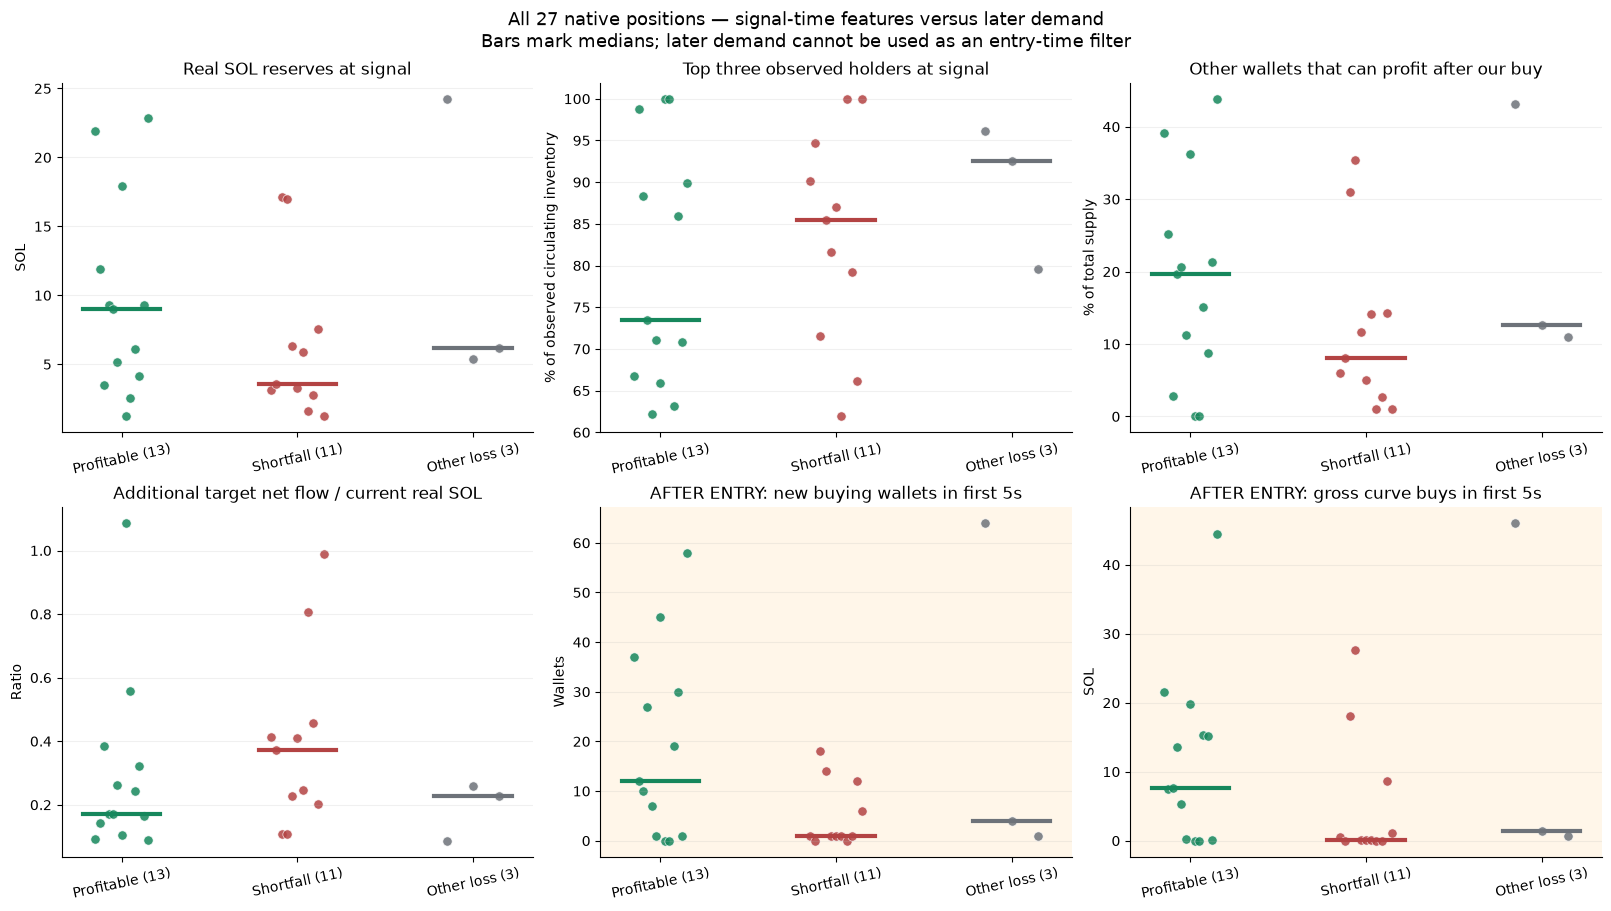

In [18]:
fig,axes=plt.subplots(2,3,figsize=(16,9),layout='constrained')
panels=[
    (entry_comparison,'signal_actual_sol_reserve_SOL','Real SOL reserves at signal','SOL',False),
    (entry_comparison,'signal_top3_pct_observed_inventory','Top three observed holders at signal','% of observed circulating inventory',False),
    (entry_comparison,'signal_other_profitable_supply_pct','Other wallets that can profit after our buy','% of total supply',False),
    (entry_comparison,'signal_additional_target_flow_to_real_reserve_ratio','Additional target net flow / current real SOL','Ratio',False),
    (later_comparison,'postentry_5s_new_buyers','AFTER ENTRY: new buying wallets in first 5s','Wallets',True),
    (later_comparison,'postentry_5s_gross_buy_SOL','AFTER ENTRY: gross curve buys in first 5s','SOL',True),
]
for ax,(frame,feature,title,ylabel,is_future) in zip(axes.flat,panels):
    for i,(group,color) in enumerate(zip(group_order,group_colors)):
        selected=frame[frame['group']==group].sort_values('mint')
        y=selected[feature].dropna().to_numpy()
        x=i+np.linspace(-.15,.15,len(y))
        ax.scatter(x,y,color=color,s=45,alpha=.85,edgecolor='white',linewidth=.5)
        if len(y):
            ax.plot([i-.22,i+.22],[np.median(y)]*2,color=color,linewidth=3)
    ax.set_xticks(range(3),group_labels,rotation=12)
    ax.set(ylabel=ylabel,title=title)
    ax.grid(axis='y',alpha=.18)
    if is_future:
        ax.set_facecolor('#fff6e9')
fig.suptitle('All 27 native positions — signal-time features versus later demand\nBars mark medians; later demand cannot be used as an entry-time filter',fontsize=13)
fig.savefig(COMPARISON/'group_comparison.png',dpi=160)
plt.show()

## What separates the groups in this sample

**Subsequent demand is the largest difference.** During the first five
timestamp seconds after entry, winners had a median of 12 new buying wallets
and 7.637 SOL of gross curve buys; shortfall cases had one new buyer and
0.099 SOL. The median maximum running net historical inflow was +3.983 SOL
for winners and zero for shortfalls. These windows may include activity after
a winner has already exited. They describe the market's continuation, not a
feature known at the initial signal or proof of causation by our order.

Volume alone has important counterexamples. UNBOX received 18.136 SOL of
curve buys in those five seconds, but historical selling left net flow at
-8.170 SOL. Qweb received 27.582 SOL of buys, but net flow was -5.934 SOL.
The ordinary loser 毒チワワ had 64 new buyers and 46.053 SOL of curve buys,
yet still lost in the replay. The order and size of selling matter alongside
incoming demand; simple volume or trader-count confirmation is insufficient.

**An observable difference is developer participation.** Seven of thirteen
winners had no observed launch-creator buy by the signal, while every
shortfall case had one. The losing token 毒チワワ also had no observed creator
buy, so this is not a guaranteed profit condition. Dev sellout by the signal
appears in three winners and four shortfalls; by landing it appears in five
shortfalls. Waiting for sellout alone does not separate the outcomes.

**Shortfalls generally had thinner pools and greater holder concentration.**
Median actual SOL at the signal was 3.584 versus 8.979 for winners. The top
three wallets held 85.45% versus 73.47% of observed circulating inventory.
Additional net flow needed for our target was 37.12% versus 17.20% of the
current actual reserve. The groups overlap substantially: BETDRONE won with
just 1.213 SOL of historical actual liquidity, while UNBOX and Qweb lost
despite roughly 17 SOL. A simple minimum-liquidity cutoff cannot capture this.

**Several suspected warnings also appear in winners.** Profitable exits for
other holders existed in eleven of thirteen winners and all eleven
shortfalls. The original reference sizing window failed a fresh calculation
at landing in six winners and three shortfalls. All signals were deliberately
sized near the same 0.001 SOL reserve margin. Initial unique-buyer counts were
similar: medians of seven and eight. Those facts do not independently explain
which launches receive the next wave of demand.

These are exploratory observations from one hour and 27 filled positions.
No model or optimized threshold has been fitted and no new filter has been
validated on a later day. The replay's reserve-impact limitation still
applies; a shortfall label does not establish a real-world failed sale.

## Revised rules and paired independent-period test

The revised strategy was selected on the previously investigated October 10
hour. Both the original and revised version then use exactly the same
October 11, 10:00-11:00 UTC birth cohort, with a tail through 11:16 UTC.
Selection is recorded before any validation run. No validation outcomes
change the rules. This is the requested **before and after comparison**.

The selected revision requires no recorded buy by the launch creator, caps
gross buy budget at 0.2 SOL, and watches an initial feasible reference window.
It waits at least one additional slot, requires two new buying wallet
addresses and at least 0.1 SOL net curve inflow since that watch began, then
recomputes sizing and thresholds. Reference buyers still qualify in the
original first two slots; entry decisions may continue through slot eight.
Target remains +5% net. A -10% quote-based loss trigger or five-second timeout
schedules a sale one slot later. These triggers do not guarantee that a
delayed sale can fill at that loss or price.

Both versions start with 10 SOL and use the same network, program, creator,
rent and minimum-output scenarios. The original remains otherwise unchanged.
All three proposed revisions and the development baseline are retained.
The best development revision remained slightly negative in exogenous
settlement; calling it the selected candidate does not imply profitability.

**Execution comparisons:** strict replay and explicit virtual settlement
retain historical reserves. Conditional replay now keeps our own reserve
effects, reprices historical exact-quote purchases and exact-token buys,
and checks counterpart inventories. Two conditional sell assumptions are
shown separately: fixed recorded token input, or the observed fraction of
the seller's retained position. The latter is an assumption about a trader's
sell sizing, not proof of their response. Unknown buy intent, unsupported
counterpart inventory, liquidity and source gaps retain open exposure.
Conditional modes never add synthetic funding.

In [19]:
REDESIGN = ROOT/'var/dnipro/sniper-window-redesign-v1'
experiment_plan=json.loads((REDESIGN/'experiment_plan.json').read_text())
selection=json.loads((REDESIGN/'selection.json').read_text())
assert sha(REDESIGN/'experiment_plan.json')==selection['experiment_plan_sha256']
redesign_rows=[]
redesign_positions=[]
validation_source_hashes=set()
for folder in sorted(REDESIGN.iterdir()):
    if not folder.is_dir() or not (folder/'manifest.json').exists():
        continue
    manifest=json.loads((folder/'manifest.json').read_text())
    assert manifest['complete']
    for filename,digest in manifest['files'].items():
        assert sha(folder/filename)==digest,(folder.name,filename)
    data=json.loads((folder/'result.json').read_text())
    s=data['summary']
    for transaction in data['ledger']:
        totals=defaultdict(int)
        for posting in transaction['postings']:
            totals[posting['asset_id']]+=posting['amount_atomic']
        assert all(value==0 for value in totals.values())
    if s['execution_mode']=='CONDITIONAL_PROTOCOL_REPLAY':
        assert s['synthetic_shortfall_lamports']==0
        assert s['own_reserve_impact_propagated']
    if folder.name.startswith('validation-'):
        validation_source_hashes.add(s['source_input_sha256'])
    redesign_rows.append(dict(run=folder.name,mode=s['execution_mode'],
        modeled_closed_net_PnL_SOL=s['realized_net_pnl_lamports']/LAMPORTS,
        filled=s['filled_entries'],closed=s['closed_positions'],open=s['open_positions'],
        unresolved_cost_SOL=s['open_cash_cost_lamports']/LAMPORTS,
        zero_recovery_stress_SOL=(s['realized_net_pnl_lamports']-s['open_cash_cost_lamports'])/LAMPORTS,
        synthetic_shortfall_SOL=s['synthetic_shortfall_lamports']/LAMPORTS,
        source_gaps=len(s['publication_gaps']),conditional_errors=s['conditional_repricing_errors'],
        counterpart_sell_fraction=s['policy']['counterpart_sell_fraction']))
    for p in data['positions']:
        if 'signal_slot' in p:
            redesign_positions.append(dict(run=folder.name,token=p['symbol'],gmgn_url=p['gmgn_url'],
                mint=p['mint'],status=p['status'],reason=p['reason'],
                signal_slot=p['signal_slot'],entry_slot=p.get('entry_slot'),exit_slot=p.get('exit_slot'),
                gross_buy_budget_SOL=p['budget_lamports']/LAMPORTS,
                modeled_closed_PnL_SOL=p['closed_pnl_lamports']/LAMPORTS if p.get('closed_pnl_lamports') is not None else None,
                remaining_tokens_raw=p['remaining_tokens_atomic']))
assert len(validation_source_hashes)==1
paired_results=pd.DataFrame(redesign_rows)
paired_positions=pd.DataFrame(redesign_positions)
display(Markdown('Selected development candidate: **'+selection['selected']+'**.'))
display(paired_results[paired_results['run'].str.startswith('development-')])
display(paired_results[paired_results['run'].str.startswith('validation-')])
display(paired_results[paired_results['run'].str.startswith('additional-')])
paired_results.to_csv(REDESIGN/'notebook_before_after.csv',index=False)
paired_positions.to_csv(REDESIGN/'all_variant_signal_positions.csv',index=False)
linked_table(paired_positions[paired_positions['run']=='validation-virtual-after'])

Selected development candidate: **creator_flat_confirmed_small**.

,run,mode,modeled_closed_net_PnL_SOL,filled,closed,open,unresolved_cost_SOL,zero_recovery_stress_SOL,synthetic_shortfall_SOL,source_gaps,conditional_errors,counterpart_sell_fraction
8,development-baseline,EXOGENOUS_VIRTUAL_SETTLEMENT,-3.759502,27,27,0,0.000000,-3.759502,7.942451,0,0,0
9,development-conditional_fixed-after,CONDITIONAL_PROTOCOL_REPLAY,-0.034330,5,4,1,0.202144,-0.236474,0.000000,0,5,0
10,development-conditional_fixed-before,CONDITIONAL_PROTOCOL_REPLAY,0.117201,9,2,7,9.578980,-9.461779,0.000000,0,9,0
11,development-conditional_fraction-after,CONDITIONAL_PROTOCOL_REPLAY,-0.005749,5,5,0,0.000000,-0.005749,0.000000,0,4,1
12,development-conditional_fraction-before,CONDITIONAL_PROTOCOL_REPLAY,-1.150398,18,12,6,8.731632,-9.882031,0.000000,0,8,1
13,development-confirmed_small,EXOGENOUS_VIRTUAL_SETTLEMENT,-0.172668,22,22,0,0.000000,-0.172668,0.000000,0,0,0
14,development-creator_flat_confirmed_small,EXOGENOUS_VIRTUAL_SETTLEMENT,-0.002444,5,5,0,0.000000,-0.002444,0.000000,0,0,0
15,development-creator_flat_small,EXOGENOUS_VIRTUAL_SETTLEMENT,-0.043592,9,9,0,0.000000,-0.043592,0.000000,0,0,0
16,development-strict-after,EXOGENOUS_REPLAY,-0.002444,5,5,0,0.000000,-0.002444,0.000000,0,0,0
17,development-strict-before,EXOGENOUS_REPLAY,0.433958,22,15,7,9.701283,-9.267325,0.000000,0,0,0


,run,mode,modeled_closed_net_PnL_SOL,filled,closed,open,unresolved_cost_SOL,zero_recovery_stress_SOL,synthetic_shortfall_SOL,source_gaps,conditional_errors,counterpart_sell_fraction
18,validation-conditional_fixed-after,CONDITIONAL_PROTOCOL_REPLAY,-0.000105,0,0,0,0.000000,-0.000105,0.0,25,0,0
19,validation-conditional_fixed-before,CONDITIONAL_PROTOCOL_REPLAY,0.487665,10,5,5,8.893691,-8.406027,0.0,25,9,0
20,validation-conditional_fraction-after,CONDITIONAL_PROTOCOL_REPLAY,-0.000105,0,0,0,0.000000,-0.000105,0.0,25,0,1
21,validation-conditional_fraction-before,CONDITIONAL_PROTOCOL_REPLAY,0.487665,10,5,5,8.893691,-8.406027,0.0,25,8,1
22,validation-double_network,EXOGENOUS_VIRTUAL_SETTLEMENT,-0.000210,0,0,0,0.000000,-0.000210,0.0,25,0,0
23,validation-double_network-before,EXOGENOUS_VIRTUAL_SETTLEMENT,0.048389,7,1,6,9.906249,-9.857861,0.0,25,0,0
24,validation-strict-after,EXOGENOUS_REPLAY,-0.000105,0,0,0,0.000000,-0.000105,0.0,25,0,0
25,validation-strict-before,EXOGENOUS_REPLAY,0.331858,9,3,6,9.873278,-9.541420,0.0,25,0,0
26,validation-two_slot_latency,EXOGENOUS_VIRTUAL_SETTLEMENT,-0.000105,0,0,0,0.000000,-0.000105,0.0,25,0,0
27,validation-two_slot_latency-before,EXOGENOUS_VIRTUAL_SETTLEMENT,0.182890,7,1,6,9.873278,-9.690388,0.0,25,0,0


,run,mode,modeled_closed_net_PnL_SOL,filled,closed,open,unresolved_cost_SOL,zero_recovery_stress_SOL,synthetic_shortfall_SOL,source_gaps,conditional_errors,counterpart_sell_fraction
0,additional-conditional_fixed-after,CONDITIONAL_PROTOCOL_REPLAY,-0.019276,3,2,1,0.202249,-0.221525,0.000000,0,3,0
1,additional-conditional_fixed-before,CONDITIONAL_PROTOCOL_REPLAY,0.416647,15,8,7,9.988525,-9.571878,0.000000,0,11,0
2,additional-conditional_fraction-after,CONDITIONAL_PROTOCOL_REPLAY,-0.038403,3,3,0,0.000000,-0.038403,0.000000,0,0,1
3,additional-conditional_fraction-before,CONDITIONAL_PROTOCOL_REPLAY,1.771675,34,29,5,9.279650,-7.507976,0.000000,0,15,1
4,additional-strict-after,EXOGENOUS_REPLAY,-0.043697,3,3,0,0.000000,-0.043697,0.000000,0,0,0
5,additional-strict-before,EXOGENOUS_REPLAY,1.378414,15,7,8,10.597802,-9.219389,0.000000,0,0,0
6,additional-virtual-after,EXOGENOUS_VIRTUAL_SETTLEMENT,-0.043697,3,3,0,0.000000,-0.043697,0.000000,0,0,0
7,additional-virtual-before,EXOGENOUS_VIRTUAL_SETTLEMENT,-4.005116,36,36,0,0.000000,-4.005116,21.227053,0,0,0


run,token,mint,status,reason,signal_slot,entry_slot,exit_slot,gross_buy_budget_SOL,modeled_closed_PnL_SOL,remaining_tokens_raw
validation-virtual-after,egge,pREppWcXsq56L8egM9iM3z7YkHUrBacG6d279t5JGDJ,ENTRY_FAILED,MINIMUM_OUTPUT_NOT_MET,455619018,—,—,0.200000,—,0


## How to interpret the before and after results

A positive closed-position total with open positions is an incomplete
portfolio result. Open costs and zero-recovery stress are shown alongside it;
zero recovery is a stress scenario rather than an observed loss. Virtual
settlement exposes assumed funding and cannot establish on-chain solvency.

The October 11 snapshot has 25 unproven publication intervals. Both
versions use the same fail-closed coverage behavior; affected positions are
retained, never removed as inconvenient trades. A further fixed October 10
17:30-18:30 UTC period contains 3,146 launches, 175,172 trades and no unproven
publication gaps. Both unchanged versions and the same execution scenarios
are tested there; the first independent result remains included.
Conditional counterpart
conflicts likewise cannot be relabeled as clean profitable completions.

The paired tests establish how these particular versions behaved on this
bounded sample. They do not establish exact landing, full holder history,
historical slippage limits, trader reactions or a guaranteed profitable
strategy. Network fees are a configured scenario, tips are zero, and the
physical conditional replay has separate assumptions from unchanged-price
historical settlement. Original results and notebooks remain preserved.

## CSV exports and reproducibility

Every table is saved as a plain CSV. The notebook uses the native result ledgers
and upstream quote function; it does not replace the trusted backtest engine.
Its source manifests and output hashes are recorded in the export receipt.

To rerun in IntelliJ, select the local interpreter
`var/dnipro/sniper-notebook-venv/bin/python` from this repository. The environment
is isolated from the backtest engine; its resolved packages are saved in
`var/dnipro/sniper-notebook-requirements.txt`. The builder can execute this notebook
using the workspace-local `sniper-research` kernel.

**Remaining realism limits:** neither replay propagates our reserve impact
through other traders' orders. Holdings/transfers, historical fee-tier changes,
actual order landing, tips and the configured transaction costs are not exact
execution evidence. Virtual-settlement losses are modeled losses; strict open
inventory remains an unvalued position rather than a confirmed total loss.

In [20]:
summary_table.to_csv(EXPORT / 'run_summaries.csv', index=False)
all_buys.to_csv(EXPORT / 'simulated_buys.csv', index=False)
outcomes.to_csv(EXPORT / 'position_outcomes.csv', index=False)
liquidity.to_csv(EXPORT / 'liquidity_blocked_positions.csv', index=False)
failures.to_csv(EXPORT / 'simulated_order_failures.csv', index=False)
signals.to_csv(EXPORT / 'all_signal_outcomes.csv', index=False)
developers.to_csv(EXPORT / 'developer_fee_accounting.csv', index=False)
fee_comparison.to_csv(EXPORT / 'creator_fee_rerun_comparison.csv', index=False)
selected_tape = [r for r in all_trades if r['mint'] in filled_mints]
pd.DataFrame([{k: r[k] for k in ['mint', 'slot', 'tx_idx', 'event_uid', 'time', 'side', 'trader', 'quote', 'tokens', 'virtual_quote', 'virtual_base', 'real_quote', 'real_base', 'signature']} for r in selected_tape]).to_csv(EXPORT / 'historical_curve_trades.csv', index=False)
receipt = {
    'schema': 'dnipro.sniper-result-notebook/v1',
    'strict_result_sha256': sha(RUN_DIRS['strict'] / 'result.json'),
    'virtual_result_sha256': sha(RUN_DIRS['virtual'] / 'result.json'),
    'source_manifest_sha256': sha(SOURCE / 'manifest.json'),
    'source_input_sha256': runs['virtual']['summary']['source_input_sha256'],
    'filled_buy_records_across_runs': len(all_buys),
    'virtual_filled_and_closed': len(outcomes), 'strict_liquidity_blocked': len(liquidity),
    'strict_blocked_submitted_sells': int(liquidity['submitted_strict_sell_attempts'].sum()),
    'all_native_ledgers_conserve': True,
    'all_seven_native_full_sell_quotes_rejected': True,
    'partial_quote_diagnostics_use_native_model': True,
    'creator_fee_credit_enabled': True,
    'developer_receivables_are_not_our_trading_PnL': True,
    'native_creator_fee_rerun_economics_match_baseline': True,
    'additional_creator_fees_from_our_fills_lamports': simulated_fee_total,
    'our_fill_creator_fee_allocation_conservation_verified': True,
    'last_retained_clock_utc': utc(max(clock.values())),
    'all_shortfall_cases_traced': len(cases),
    'strategy_decision_records': len(strategy_trace),
    'observed_inventory_conservation_verified': True,
    'holder_break_even_rows': len(holder_economics),
    'wait_result_sha256': sha(wait_dir / 'result.json'),
    'group_comparison_receipt_sha256': sha(COMPARISON/'receipt.json'),
    'group_comparison_counts': comparison_receipt['group_counts'],
    'redesign_selection_sha256': sha(REDESIGN/'selection.json'),
    'redesign_before_after_csv_sha256': sha(REDESIGN/'notebook_before_after.csv'),
    'csv_hashes': {p.name: sha(p) for p in sorted(EXPORT.glob('*.csv'))},
}
(EXPORT / 'receipt.json').write_text(json.dumps(receipt, indent=2) + '\n')
display(Markdown(f'Exports: `{EXPORT}`'))
print(json.dumps(receipt, indent=2))

Exports: `./var/dnipro/sniper-window-20261010-slot-traces-notebook-v1`

{
  "schema": "dnipro.sniper-result-notebook/v1",
  "strict_result_sha256": "53b4d6807386663794594466ded31d5d8b62356ccbd9cd8ec0a983f69eb52678",
  "virtual_result_sha256": "b050cdda30415d55f87a0ed8505b92d62fe7d7265424b2266e7d6c742fd3a16d",
  "source_manifest_sha256": "db5db9010ebb8b1f16f42af488a105277b22e7133986903b85aaf9125e8e0f25",
  "source_input_sha256": "9c172ff5a765a7c45154b92c9c0aed0c22bb2bde1202d5f82559a4ab809c4439",
  "filled_buy_records_across_runs": 49,
  "virtual_filled_and_closed": 27,
  "strict_liquidity_blocked": 7,
  "strict_blocked_submitted_sells": 0,
  "all_native_ledgers_conserve": true,
  "all_seven_native_full_sell_quotes_rejected": true,
  "partial_quote_diagnostics_use_native_model": true,
  "creator_fee_credit_enabled": true,
  "developer_receivables_are_not_our_trading_PnL": true,
  "native_creator_fee_rerun_economics_match_baseline": true,
  "additional_creator_fees_from_our_fills_lamports": 224505329,
  "our_fill_creator_fee_allocation_conservation_verified":